In [1]:
# Cell 1 - Environment Setup, Deterministic Seeds, and Hardware Config
import os
import random
from pathlib import Path
import numpy as np

# 1. Set deterministic seed across all environments (CPU & GPU)
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # Wajib untuk determinisme MatMul/Attention di CUDA
random.seed(SEED)
np.random.seed(SEED)

DEVICE = "cpu"
NUM_WORKERS = min(4, os.cpu_count() or 2)

try:
    import torch
    torch.manual_seed(SEED)  # Kunci RNG PyTorch di CPU maupun GPU
    if torch.cuda.is_available():
        DEVICE = torch.device("cuda:0")
        torch.cuda.manual_seed(SEED)
        torch.cuda.manual_seed_all(SEED)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    else:
        DEVICE = torch.device("cpu")
except ImportError:
    pass

# Helper function untuk menjaga determinisme DataLoader multi-worker di Cell 16-18 nanti
def seed_worker(worker_id: int):
    worker_seed = SEED + worker_id
    np.random.seed(worker_seed)
    random.seed(worker_seed)

# 2. Dynamic path resolution: Kaggle primary, fallback to local workspace
base_dir = Path("/kaggle/input/competitions/schematics-2026")
if not base_dir.exists():
    for cand in [
        Path("/kaggle/input/schematics-2026"),
        Path("/kaggle/input/npc-dsc-2026"),
        Path("C:/Github/schematics-npc-dsc-2026/schematics-2026"),
        Path("schematics-2026"),
    ]:
        if cand.exists():
            base_dir = cand
            break

# Direktori output kerja (untuk simpan .npy, checkpoints v2, dan submission)
WORK_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
WORK_DIR.mkdir(parents=True, exist_ok=True)

train_meta_path = base_dir / "train" / "metadata.csv"
sub_path = base_dir / "sample_submission.csv"

assert train_meta_path.exists(), f"Train metadata tidak ditemukan di: {train_meta_path}"
assert sub_path.exists(), f"Sample submission tidak ditemukan di: {sub_path}"

device_name = "cpu"
if str(DEVICE) != "cpu" and hasattr(torch.cuda, "get_device_name"):
    device_name = f"cuda:0 ({torch.cuda.get_device_name(0)})"

print(f"environment_ready | seed={SEED} | device={device_name} | workers={NUM_WORKERS}")
print(f"base_dir={base_dir.resolve()} | work_dir={WORK_DIR.resolve()}")
print(f"train_metadata_exists={train_meta_path.exists()} | sample_submission_exists={sub_path.exists()}")

environment_ready | seed=42 | device=cuda:0 (Tesla T4) | workers=4
base_dir=/kaggle/input/competitions/schematics-2026 | work_dir=/kaggle/working
train_metadata_exists=True | sample_submission_exists=True


In [2]:
# Cell 2 - Metadata Schema Audit, Target Distribution, and Imbalance Ratio
import pandas as pd
import numpy as np

train_df = pd.read_csv(train_meta_path)
sub_df = pd.read_csv(sub_path)

# 1. Verifikasi integritas skema, keunikan ID, dan ketiadaan nilai null
expected_train_cols = {"file_id", "audio_path", "label", "source_group"}
expected_sub_cols = {"file_id", "label"}

assert expected_train_cols.issubset(set(train_df.columns)), "Kolom train metadata tidak sesuai skema"
assert expected_sub_cols.issubset(set(sub_df.columns)), "Kolom sample submission tidak sesuai skema"
assert train_df.isna().sum().sum() == 0, "Ditemukan missing values pada train metadata"
assert sub_df["file_id"].isna().sum() == 0, "Ditemukan missing values pada file_id test set"
assert train_df["file_id"].is_unique, "Ditemukan duplikasi file_id pada train_df"
assert sub_df["file_id"].is_unique, "Ditemukan duplikasi file_id pada sub_df"
assert len(set(train_df["file_id"]).intersection(set(sub_df["file_id"]))) == 0, "Leakage: Ada file_id yang sama di train dan test!"

n_train = len(train_df)
n_test = len(sub_df)

# 2. Resolusi path file audio (.flac) untuk Train & Test agar siap dipakai di Cell 3-23
train_df["filepath"] = train_df["audio_path"].apply(lambda p: str(base_dir / p))
if "audio_path" in sub_df.columns:
    sub_df["filepath"] = sub_df["audio_path"].apply(lambda p: str(base_dir / p))
else:
    sub_df["filepath"] = sub_df["file_id"].apply(lambda fid: str(base_dir / "test" / f"{fid}.flac"))

# 3. Kunci kontrak urutan kelas global (Alfabetis standar seperti Day 1)
KNOWN_CLASSES = ["Bondol Jawa", "Cendrawasih", "Kutilang"]
ALL_CLASSES = KNOWN_CLASSES + ["Unknown"]
CLASS_TO_IDX = {c: i for i, c in enumerate(KNOWN_CLASSES)}
IDX_TO_CLASS = {i: c for i, c in enumerate(KNOWN_CLASSES)}
train_df["target"] = train_df["label"].map(CLASS_TO_IDX)
assert train_df["target"].isna().sum() == 0, "Ada label di train_df yang tidak masuk KNOWN_CLASSES"

# 4. Audit distribusi kelas, Imbalance Ratio (IR), dan Shannon Entropy
class_counts = train_df["label"].value_counts()
ir_ratio = class_counts.max() / class_counts.min()

probs = class_counts.values / n_train
shannon_entropy = -np.sum(probs * np.log2(probs))
norm_entropy = shannon_entropy / np.log2(len(KNOWN_CLASSES))

# Effective Number Class-Balanced Weights (Cui et al., CVPR 2019, beta=0.99)
beta_cb = 0.99
counts_ordered = np.array([class_counts[c] for c in KNOWN_CLASSES], dtype=np.float64)
eff_num = (1.0 - np.power(beta_cb, counts_ordered)) / (1.0 - beta_cb)
cb_weights = (1.0 / eff_num) / np.sum(1.0 / eff_num) * len(KNOWN_CLASSES)
CB_WEIGHT_DICT = {c: float(cb_weights[i]) for i, c in enumerate(KNOWN_CLASSES)}

print(f"metadata_audit | train_samples={n_train} | test_samples={n_test} | null_values=0 | id_overlap=0")
print(f"imbalance_metrics | majority={class_counts.index[0]} ({class_counts.max()}) | minority={class_counts.index[-1]} ({class_counts.min()}) | IR={ir_ratio:.2f}")
print(f"entropy_metrics | shannon_entropy={shannon_entropy:.3f} bits | normalized_entropy={norm_entropy:.3f}")
print("class_distribution & effective_cb_weights (beta=0.99):")
for lbl, cnt in class_counts.items():
    pct = (cnt / n_train) * 100.0
    print(f"  {lbl:<14}: {cnt:>4} ({pct:5.2f}%) | ratio_to_min={cnt/class_counts.min():5.2f}x | cb_weight={CB_WEIGHT_DICT[lbl]:.4f} | target_idx={CLASS_TO_IDX[lbl]}")

metadata_audit | train_samples=1826 | test_samples=814 | null_values=0 | id_overlap=0
imbalance_metrics | majority=Bondol Jawa (1124) | minority=Cendrawasih (83) | IR=13.54
entropy_metrics | shannon_entropy=1.163 bits | normalized_entropy=0.734
class_distribution & effective_cb_weights (beta=0.99):
  Bondol Jawa   : 1124 (61.56%) | ratio_to_min=13.54x | cb_weight=0.7959 | target_idx=0
  Kutilang      :  619 (33.90%) | ratio_to_min= 7.46x | cb_weight=0.7974 | target_idx=2
  Cendrawasih   :   83 ( 4.55%) | ratio_to_min= 1.00x | cb_weight=1.4067 | target_idx=1


In [3]:
# Cell 3 - Audio Stream Properties, Source Group Nesting, Exact Deduplication, and Duration Shift Test
from pathlib import Path
import hashlib
import pandas as pd
from scipy.stats import ks_2samp, wasserstein_distance

train_audio_dir = base_dir / "train" / "audio"
test_audio_dir = base_dir / "test" / "audio"

# Sinkronisasi path absolut ke DataFrame untuk digunakan di Cell 4-23
train_df["filepath"] = [str(train_audio_dir / f"{fid}.flac") for fid in train_df["file_id"]]
sub_df["filepath"] = [str(test_audio_dir / f"{fid}.flac") for fid in sub_df["file_id"]]

# 1. Fast native FLAC STREAMINFO binary header parser
def read_flac_info(path: Path):
    with open(path, "rb") as f:
        if f.read(4) != b"fLaC":
            return None
        hdr = f.read(4)
        if (hdr[0] & 0x7F) != 0:  # 0 menandakan blok STREAMINFO
            return None
        d = f.read(int.from_bytes(hdr[1:], "big"))
        sr = (d[10] << 12) | (d[11] << 4) | (d[12] >> 4)
        channels = ((d[12] >> 1) & 0x07) + 1
        samples = ((d[13] & 0x0F) << 32) | int.from_bytes(d[14:18], "big")
        return sr, channels, samples / sr

train_props = [read_flac_info(Path(p)) for p in train_df["filepath"]]
test_props = [read_flac_info(Path(p)) for p in sub_df["filepath"]]

assert all(p is not None for p in train_props), "Terdapat file FLAC train dengan header tidak valid!"
assert all(p is not None for p in test_props), "Terdapat file FLAC test dengan header tidak valid!"

train_srs = set(p[0] for p in train_props)
train_chs = set(p[1] for p in train_props)
train_durs = [p[2] for p in train_props]

test_srs = set(p[0] for p in test_props)
test_chs = set(p[1] for p in test_props)
test_durs = [p[2] for p in test_props]

# Simpan durasi ke DataFrame untuk referensi VAD & 3-Crop TTA
train_df["duration_sec"] = train_durs
sub_df["duration_sec"] = test_durs

print(f"train_audio_properties | count={len(train_props)} | sample_rates={train_srs} | channels={train_chs}")
print(f"train_duration | min={min(train_durs):.2f}s | mean={sum(train_durs)/len(train_durs):.2f}s | max={max(train_durs):.2f}s")
print(f"test_audio_properties  | count={len(test_props)} | sample_rates={test_srs} | channels={test_chs}")
print(f"test_duration  | min={min(test_durs):.2f}s | mean={sum(test_durs)/len(test_durs):.2f}s | max={max(test_durs):.2f}s")

# 2. Struktur hierarkis source_group per label (audit nesting)
ct = pd.crosstab(train_df["source_group"], train_df["label"])
groups_per_class = {col: int((ct[col] > 0).sum()) for col in ct.columns}
max_species_per_group = int((ct > 0).sum(axis=1).max())
assert max_species_per_group == 1, "Peringatan kebocoran: terdapat source_group yang memuat lebih dari 1 spesies!"
print(f"source_group_nesting | total_unique_groups={train_df['source_group'].nunique()} | max_species_sharing_one_group={max_species_per_group} (100% nested)")
print(f"groups_per_class: {groups_per_class}")

# 3. Exact byte hash deduplication (SHA256)
def compute_sha256(path: Path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while chunk := f.read(131072):
            h.update(chunk)
    return h.hexdigest()

train_hashes = {compute_sha256(Path(p)) for p in train_df["filepath"]}
test_hashes = {compute_sha256(Path(p)) for p in sub_df["filepath"]}
hash_overlap = train_hashes & test_hashes

assert len(train_hashes) == len(train_df), "Ditemukan duplikat byte identik di dalam Train Set!"
assert len(test_hashes) == len(sub_df), "Ditemukan duplikat byte identik di dalam Test Set!"
assert len(hash_overlap) == 0, "Data Leakage: Ditemukan file identik antara Train dan Test Set!"

print(f"deduplication_audit | train_unique={len(train_hashes)}/{len(train_df)} | test_unique={len(test_hashes)}/{len(sub_df)} | train_test_overlap={len(hash_overlap)}")

# 4. Uji pergeseran durasi (Two-Sample KS-Test & Wasserstein Distance)
ks_stat, ks_pval = ks_2samp(train_durs, test_durs)
w_dist = wasserstein_distance(train_durs, test_durs)
print(f"duration_shift_test | ks_stat={ks_stat:.4f} | ks_pval={ks_pval:.4f} | wasserstein_distance={w_dist:.4f}s")

# 5. Kardinalitas ukuran sampel per source_group
grp_sizes = train_df.groupby(["label", "source_group"]).size()
print("source_group_cardinality_per_class:")
for label in train_df["label"].value_counts().index:
    sub_grp = grp_sizes[label].sort_values()
    sizes_list = sub_grp.tolist()
    print(f"  {label:<14} (n_groups={len(sub_grp)}): min={sub_grp.min():>2} | median={sub_grp.median():>3.0f} | max={sub_grp.max():>3} | total={sub_grp.sum():>4} | group_sizes={sizes_list}")

train_audio_properties | count=1826 | sample_rates={48000} | channels={2}
train_duration | min=5.27s | mean=10.04s | max=14.90s
test_audio_properties  | count=814 | sample_rates={48000} | channels={2}
test_duration  | min=5.55s | mean=10.09s | max=14.90s
source_group_nesting | total_unique_groups=15 | max_species_sharing_one_group=1 (100% nested)
groups_per_class: {'Bondol Jawa': 7, 'Cendrawasih': 4, 'Kutilang': 4}
deduplication_audit | train_unique=1826/1826 | test_unique=814/814 | train_test_overlap=0
duration_shift_test | ks_stat=0.0302 | ks_pval=0.6695 | wasserstein_distance=0.0892s
source_group_cardinality_per_class:
  Bondol Jawa    (n_groups=7): min=58 | median=123 | max=336 | total=1124 | group_sizes=[58, 82, 117, 123, 176, 232, 336]
  Kutilang       (n_groups=4): min=132 | median=154 | max=178 | total= 619 | group_sizes=[132, 143, 166, 178]
  Cendrawasih    (n_groups=4): min= 3 | median= 22 | max= 35 | total=  83 | group_sizes=[3, 16, 29, 35]


In [4]:
# Cell 4 - Audio Signal Dynamics and Acoustic Health Audit
from pathlib import Path
import subprocess
import numpy as np
import pandas as pd

# Multi-backend audio loader with automatic fallback (16kHz baseline diagnostic)
def load_audio_mono(path: str, target_sr: int = 16000):
    try:
        import soundfile as sf
        data, sr = sf.read(str(path))
        if data.ndim > 1:
            data = data.mean(axis=1)
        if sr != target_sr:
            from scipy.signal import resample
            num_samples = int(len(data) * target_sr / sr)
            data = resample(data, num_samples)
        return data.astype(np.float32)
    except ImportError:
        pass

    try:
        import torchaudio
        import torchaudio.transforms as T
        waveform, sr = torchaudio.load(str(path))
        if waveform.shape[0] > 1:
            waveform = waveform.mean(dim=0, keepdim=True)
        if sr != target_sr:
            resampler = T.Resample(sr, target_sr)
            waveform = resampler(waveform)
        return waveform.squeeze(0).numpy().astype(np.float32)
    except ImportError:
        pass

    # System fallback: ffmpeg raw 32-bit float pipe
    cmd = ["ffmpeg", "-v", "error", "-i", str(path), "-f", "f32le", "-ac", "1", "-ar", str(target_sr), "-"]
    proc = subprocess.run(cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE)
    return np.frombuffer(proc.stdout, dtype=np.float32)

# Sample 20 per kelas latih + 20 dari test set (deterministik seed 42)
samples = []
for label in ["Bondol Jawa", "Cendrawasih", "Kutilang"]:
    subset = train_df[train_df["label"] == label].sample(20, random_state=42)
    for row in subset.itertuples():
        samples.append((label, row.filepath))

test_sample = sub_df.sample(20, random_state=42)
for row in test_sample.itertuples():
    samples.append(("Test_Unknown_Mixed", row.filepath))

records = []
for group_name, file_path in samples:
    sig = load_audio_mono(file_path, target_sr=16000)
    if len(sig) == 0:
        continue
    rms = float(np.sqrt(np.mean(sig ** 2)))
    peak = float(np.max(np.abs(sig)))
    crest_factor = float(peak / (rms + 1e-8))
    zcr = float(np.mean(np.abs(np.diff(np.sign(sig))))) / 2.0
    # Silence ratio: proporsi sampel dengan amplitudo < 0.01 (-40 dBFS)
    silence_frac = float(np.mean(np.abs(sig) < 0.01))
    clipped = 1 if peak >= 0.99 else 0
    records.append({
        "group": group_name,
        "rms": rms,
        "peak": peak,
        "crest_factor": crest_factor,
        "clipped": clipped,
        "zcr": zcr,
        "silence_frac": silence_frac
    })

audit_df = pd.DataFrame(records)
summary = audit_df.groupby("group").agg(
    rms=("rms", "mean"),
    peak_mean=("peak", "mean"),
    peak_max=("peak", "max"),
    crest_mean=("crest_factor", "mean"),
    clipped=("clipped", "mean"),
    zcr=("zcr", "mean"),
    silence_frac=("silence_frac", "mean"),
)

print("acoustic_dynamics_summary:")
for grp, row in summary.iterrows():
    print(
        f"  {grp:<18} | rms={row['rms']:.4f} | peak_mean={row['peak_mean']:.3f} (max={row['peak_max']:.3f}) "
        f"| clip_rate={row['clipped']*100:.1f}% | crest={row['crest_mean']:.2f} | zcr={row['zcr']:.4f} | silence={row['silence_frac']*100:.1f}%"
    )

acoustic_dynamics_summary:
  Bondol Jawa        | rms=0.0824 | peak_mean=0.676 (max=0.972) | clip_rate=0.0% | crest=8.44 | zcr=0.3594 | silence=15.0%
  Cendrawasih        | rms=0.0882 | peak_mean=0.636 (max=0.899) | clip_rate=0.0% | crest=7.80 | zcr=0.3757 | silence=12.8%
  Kutilang           | rms=0.0941 | peak_mean=0.645 (max=0.948) | clip_rate=0.0% | crest=7.12 | zcr=0.2974 | silence=14.8%
  Test_Unknown_Mixed | rms=0.0905 | peak_mean=0.717 (max=0.996) | clip_rate=5.0% | crest=8.13 | zcr=0.3629 | silence=14.4%


In [5]:
# Cell 5 - Power Spectral Density (Welch PSD) Frequency Band Profiling and Statistical Separability Test
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.signal import welch
from scipy import stats

target_sr = 16000
band_records = []
psd_curves_by_group = {
    "Bondol Jawa": [],
    "Cendrawasih": [],
    "Kutilang": [],
    "Test_Unknown_Mixed": [],
}
psd_freqs = None

# 1. Stratified sample 30 per train class + 30 dari test set (reproduksi eksak Tabel PSD Day 1)
for label in ["Bondol Jawa", "Cendrawasih", "Kutilang"]:
    subset = train_df[train_df["label"] == label].sample(30, random_state=42)
    for row in subset.itertuples():
        sig = load_audio_mono(row.filepath, target_sr=target_sr)
        if len(sig) == 0:
            continue
        freqs, psd = welch(sig, fs=target_sr, nperseg=1024)
        total_power = float(np.sum(psd))
        if total_power <= 0:
            continue
        psd_freqs = freqs
        psd_curves_by_group[label].append(psd / (total_power + 1e-12))
        dom_freq = float(freqs[np.argmax(psd)])
        band_records.append({
            "group": label,
            "band_0_2k": float(np.sum(psd[(freqs >= 0) & (freqs < 2000)]) / total_power),
            "band_2_4k": float(np.sum(psd[(freqs >= 2000) & (freqs < 4000)]) / total_power),
            "band_4_6k": float(np.sum(psd[(freqs >= 4000) & (freqs < 6000)]) / total_power),
            "band_6_8k": float(np.sum(psd[(freqs >= 6000) & (freqs <= 8000)]) / total_power),
            "dominant_freq": dom_freq,
        })

test_subset = sub_df.sample(30, random_state=42)
for row in test_subset.itertuples():
    sig = load_audio_mono(row.filepath, target_sr=target_sr)
    if len(sig) == 0:
        continue
    freqs, psd = welch(sig, fs=target_sr, nperseg=1024)
    total_power = float(np.sum(psd))
    if total_power <= 0:
        continue
    psd_freqs = freqs
    psd_curves_by_group["Test_Unknown_Mixed"].append(psd / (total_power + 1e-12))
    dom_freq = float(freqs[np.argmax(psd)])
    band_records.append({
        "group": "Test_Unknown_Mixed",
        "band_0_2k": float(np.sum(psd[(freqs >= 0) & (freqs < 2000)]) / total_power),
        "band_2_4k": float(np.sum(psd[(freqs >= 2000) & (freqs < 4000)]) / total_power),
        "band_4_6k": float(np.sum(psd[(freqs >= 4000) & (freqs < 6000)]) / total_power),
        "band_6_8k": float(np.sum(psd[(freqs >= 6000) & (freqs <= 8000)]) / total_power),
        "dominant_freq": dom_freq,
    })

psd_df = pd.DataFrame(band_records)
psd_summary = psd_df.groupby("group").mean(numeric_only=True)
psd_median_freq = psd_df.groupby("group")["dominant_freq"].median()

print("spectral_power_distribution_by_band (stratified N=120):")
for grp, row in psd_summary.iterrows():
    med_f = psd_median_freq[grp]
    print(
        f"  {grp:<18} | 0-2kHz: {row['band_0_2k']*100:4.1f}% | 2-4kHz: {row['band_2_4k']*100:4.1f}% "
        f"| 4-6kHz: {row['band_4_6k']*100:4.1f}% | 6-8kHz: {row['band_6_8k']*100:4.1f}% | med_dom_freq={med_f:6.1f}Hz"
    )

# 2. Uji Beda Non-Parametrik Kruskal-Wallis antar 3 Spesies Latih
print("\nkruskal_wallis_separability_test (Train Classes):")
train_psd = psd_df[psd_df["group"].isin(["Bondol Jawa", "Cendrawasih", "Kutilang"])]
n_kruskal = len(train_psd)
k_classes = 3
for feature_col in ["band_0_2k", "band_2_4k", "band_4_6k", "band_6_8k", "dominant_freq"]:
    groups = [grp[feature_col].values for _, grp in train_psd.groupby("group")]
    h_stat, p_val = stats.kruskal(*groups)
    eps_sq = max(0.0, (h_stat - k_classes + 1) / (n_kruskal - k_classes))
    print(f"  feature={feature_col:<14} | H_stat={h_stat:6.2f} | eps_sq={eps_sq:.4f} | p_value={p_val:.3e}")

spectral_power_distribution_by_band (stratified N=120):
  Bondol Jawa        | 0-2kHz: 27.9% | 2-4kHz: 36.5% | 4-6kHz: 26.8% | 6-8kHz:  8.8% | med_dom_freq=3710.9Hz
  Cendrawasih        | 0-2kHz: 43.3% | 2-4kHz: 24.9% | 4-6kHz: 15.3% | 6-8kHz: 16.5% | med_dom_freq=2039.1Hz
  Kutilang           | 0-2kHz: 29.0% | 2-4kHz: 56.2% | 4-6kHz:  9.6% | 6-8kHz:  5.2% | med_dom_freq=2679.7Hz
  Test_Unknown_Mixed | 0-2kHz: 38.8% | 2-4kHz: 36.2% | 4-6kHz: 18.0% | 6-8kHz:  6.9% | med_dom_freq=2929.7Hz

kruskal_wallis_separability_test (Train Classes):
  feature=band_0_2k      | H_stat=  6.87 | eps_sq=0.0559 | p_value=3.229e-02
  feature=band_2_4k      | H_stat= 27.36 | eps_sq=0.2915 | p_value=1.144e-06
  feature=band_4_6k      | H_stat= 17.81 | eps_sq=0.1817 | p_value=1.356e-04
  feature=band_6_8k      | H_stat= 12.89 | eps_sq=0.1252 | p_value=1.589e-03
  feature=dominant_freq  | H_stat= 17.02 | eps_sq=0.1727 | p_value=2.011e-04


In [6]:
# Cell 6 - Confounder Audit (Kruskal-Wallis Eta-Squared) and Exact Balanced 4-Fold Group Partition
from itertools import product
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
from scipy import stats
from scipy.signal import welch

# 1. Ekstraksi cepat energi pita menengah (1 - 4 kHz) pada seluruh 1,826 data latih
def extract_mid_band_ratio(filepath: str):
    sig = load_audio_mono(filepath, target_sr=16000)
    if len(sig) == 0:
        return 0.0
    freqs, psd = welch(sig, fs=16000, nperseg=1024)
    psd_sum = float(np.sum(psd)) + 1e-12
    return float(np.sum(psd[(freqs >= 1000) & (freqs < 4000)]) / psd_sum)

print("extracting_mid_band_energy_across_train_set...")
with ThreadPoolExecutor(max_workers=NUM_WORKERS) as ex:
    train_df["mid_band_energy"] = list(ex.map(extract_mid_band_ratio, train_df["filepath"]))

# 2. Audit Efek Perancu (Confounder Effect Size Eta-Squared)
print("\ninternal_variance_explained_by_source_group (Eta-squared):")
for sp in ["Bondol Jawa", "Cendrawasih", "Kutilang"]:
    sub = train_df[train_df["label"] == sp]
    groups = [grp["mid_band_energy"].values for _, grp in sub.groupby("source_group")]
    if len(groups) > 1:
        h_stat, p_val = stats.kruskal(*groups)
        n = len(sub)
        k = len(groups)
        eta_sq = max(0.0, (h_stat - k + 1) / (n - k))
        print(f"  species={sp:<12} | n_groups={k:>2} | H={h_stat:7.2f} | p_value={p_val:.3e} | eta_squared={eta_sq:.4f}")

# 3. Exact Combinatorial 4-Fold StratifiedGroupKFold (1 Grup Cendrawasih & Kutilang per Fold)
N_FOLDS = 4
train_df["target"] = train_df["label"].map(CLASS_TO_IDX)
train_df["fold"] = -1

grp_meta = (
    train_df.groupby(["label", "source_group"])
    .size()
    .reset_index(name="n_samples")
    .sort_values(["label", "n_samples", "source_group"], ascending=[True, False, True])
)

cend_grps = grp_meta[grp_meta["label"] == "Cendrawasih"][["source_group", "n_samples"]].values.tolist()
kuti_grps = grp_meta[grp_meta["label"] == "Kutilang"][["source_group", "n_samples"]].values.tolist()
bond_grps = grp_meta[grp_meta["label"] == "Bondol Jawa"][["source_group", "n_samples"]].values.tolist()

# Pasangkan 1 grup Cendrawasih (besar->kecil) dengan 1 grup Kutilang (kecil->besar) per fold
group_to_fold = {}
for f in range(N_FOLDS):
    group_to_fold[cend_grps[f][0]] = f
    group_to_fold[kuti_grps[N_FOLDS - 1 - f][0]] = f

# Optimasi kombinatorial eksak (4^7 = 16,384 kombinasi) untuk 7 grup Bondol Jawa
best_score = float("inf")
best_bond_assign = None

for assign in product(range(N_FOLDS), repeat=len(bond_grps)):
    if len(set(assign)) < N_FOLDS:
        continue
    fold_bond = [0] * N_FOLDS
    fold_tot = [cend_grps[f][1] + kuti_grps[N_FOLDS - 1 - f][1] for f in range(N_FOLDS)]
    for (_, sz), f in zip(bond_grps, assign):
        fold_bond[f] += sz
        fold_tot[f] += sz
    score = np.std(fold_bond) + 0.5 * np.std(fold_tot)
    if score < best_score:
        best_score = score
        best_bond_assign = assign

for (grp_id, _), f in zip(bond_grps, best_bond_assign):
    group_to_fold[grp_id] = f

train_df["fold"] = train_df["source_group"].map(group_to_fold)

# Verifikasi ketat zero group leakage & kelengkapan kelas di setiap fold
assert (train_df["fold"] != -1).all(), "Ditemukan sampel yang belum mendapat fold!"
assert len(train_df) == 1826, f"Jumlah baris berubah: {len(train_df)}"

print("\nexact_4fold_distribution (Combinatorial StratifiedGroupKFold on source_group):")
all_val_groups = []
for f in range(N_FOLDS):
    sub = train_df[train_df["fold"] == f]
    vc = sub["label"].value_counts()
    val_groups = set(sub["source_group"].unique())
    all_val_groups.append(val_groups)
    assert len(vc) == 3, f"Fold {f} kehilangan kelas!"
    print(
        f"  fold={f}/4 | val_samples={len(sub):<4} | unique_groups={len(val_groups):>2} "
        f"| Bondol={vc['Bondol Jawa']:<4} | Kutilang={vc['Kutilang']:<3} | Cendrawasih={vc['Cendrawasih']:<2}"
    )

for f1 in range(N_FOLDS):
    for f2 in range(f1 + 1, N_FOLDS):
        assert len(all_val_groups[f1] & all_val_groups[f2]) == 0, f"Group leakage antara fold {f1} dan {f2}!"

folds_meta_path = WORK_DIR / "metadata_with_folds.csv"
train_df.to_csv(folds_meta_path, index=False)
print(f"\nleakage_verification: zero group overlap & 100% class presence across all 4 folds")
print(f"saved_metadata_with_folds -> {folds_meta_path.resolve()}")

extracting_mid_band_energy_across_train_set...

internal_variance_explained_by_source_group (Eta-squared):
  species=Bondol Jawa  | n_groups= 7 | H= 272.52 | p_value=6.273e-56 | eta_squared=0.2386
  species=Cendrawasih  | n_groups= 4 | H=   1.90 | p_value=5.939e-01 | eta_squared=0.0000
  species=Kutilang     | n_groups= 4 | H=  42.54 | p_value=3.086e-09 | eta_squared=0.0643

exact_4fold_distribution (Combinatorial StratifiedGroupKFold on source_group):
  fold=0/4 | val_samples=503  | unique_groups= 3 | Bondol=336  | Kutilang=132 | Cendrawasih=35
  fold=1/4 | val_samples=462  | unique_groups= 4 | Bondol=290  | Kutilang=143 | Cendrawasih=29
  fold=2/4 | val_samples=422  | unique_groups= 4 | Bondol=240  | Kutilang=166 | Cendrawasih=16
  fold=3/4 | val_samples=439  | unique_groups= 4 | Bondol=258  | Kutilang=178 | Cendrawasih=3 

leakage_verification: zero group overlap & 100% class presence across all 4 folds
saved_metadata_with_folds -> /kaggle/working/metadata_with_folds.csv


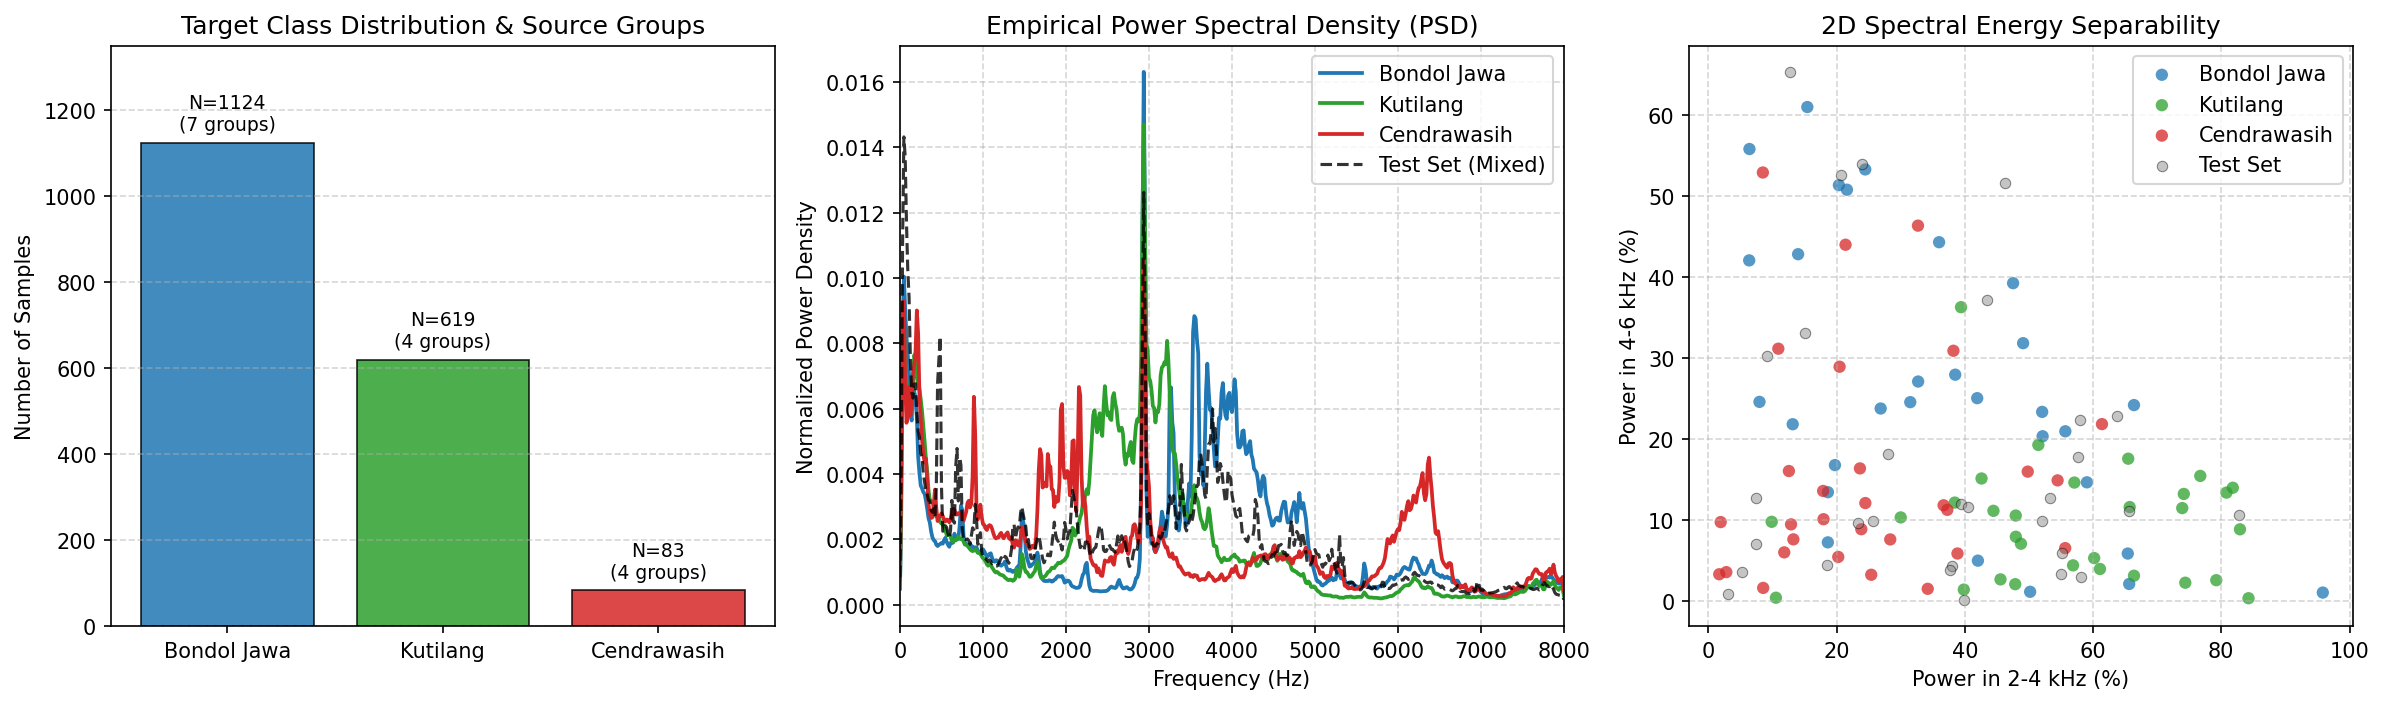

eda_plot_saved: /kaggle/working/eda_acoustic_profiles.png | size_exists=True


In [7]:
# Cell 7 - Scientific EDA Visualization: Class Cardinality, Spectral Curves, and 2D Acoustic Separability
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), dpi=150)

# Panel 1: Class counts and source groups
classes = ["Bondol Jawa", "Kutilang", "Cendrawasih"]
counts = [1124, 619, 83]
n_groups = [7, 4, 4]
colors = ["#1f77b4", "#2ca02c", "#d62728"]

bars = axes[0].bar(classes, counts, color=colors, alpha=0.85, edgecolor="black", linewidth=0.8)
for bar, grp in zip(bars, n_groups):
    h = bar.get_height()
    axes[0].text(
        bar.get_x() + bar.get_width() / 2.0,
        h + 20,
        f"N={h}\n({grp} groups)",
        ha="center",
        va="bottom",
        fontsize=9,
    )

axes[0].set_ylim(0, 1350)
axes[0].set_ylabel("Number of Samples")
axes[0].set_title("Target Class Distribution & Source Groups")
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

# Panel 2: Mean Welch PSD curves (0 - 8000 Hz, menggunakan kurva hasil Cell 5)
for label, col in zip(classes, colors):
    mean_psd = np.mean(psd_curves_by_group[label], axis=0)
    axes[1].plot(psd_freqs, mean_psd, label=label, color=col, linewidth=1.8)

test_mean_psd = np.mean(psd_curves_by_group["Test_Unknown_Mixed"], axis=0)
axes[1].plot(
    psd_freqs,
    test_mean_psd,
    label="Test Set (Mixed)",
    color="black",
    linestyle="--",
    linewidth=1.5,
    alpha=0.8,
)

axes[1].set_xlim(0, 8000)
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Normalized Power Density")
axes[1].set_title("Empirical Power Spectral Density (PSD)")
axes[1].legend(loc="upper right", frameon=True)
axes[1].grid(True, linestyle="--", alpha=0.5)

# Panel 3: 2D Spectral Energy Separability (2-4 kHz vs 4-6 kHz)
for label, col in zip(classes, colors):
    sub_data = psd_df[psd_df["group"] == label]
    axes[2].scatter(
        sub_data["band_2_4k"] * 100,
        sub_data["band_4_6k"] * 100,
        label=label,
        color=col,
        alpha=0.75,
        edgecolors="none",
        s=35,
    )

test_data = psd_df[psd_df["group"] == "Test_Unknown_Mixed"]
axes[2].scatter(
    test_data["band_2_4k"] * 100,
    test_data["band_4_6k"] * 100,
    label="Test Set",
    color="gray",
    alpha=0.45,
    edgecolors="black",
    linewidth=0.5,
    s=25,
)

axes[2].set_xlabel("Power in 2-4 kHz (%)")
axes[2].set_ylabel("Power in 4-6 kHz (%)")
axes[2].set_title("2D Spectral Energy Separability")
axes[2].legend(loc="upper right", frameon=True)
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
out_plot_path = WORK_DIR / "eda_acoustic_profiles.png"
plt.savefig(out_plot_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"eda_plot_saved: {out_plot_path.resolve()} | size_exists={out_plot_path.exists()}")

high_frequency_spectral_power_native_48khz (%):
             band_0_8k  band_8_16k  band_16_24k
label                                          
Bondol Jawa      96.37        3.52         0.11
Cendrawasih      90.71        9.08         0.21
Kutilang         93.54        5.24         1.22

stereo_channel_consistency:
            rms_diff   corr       
                mean   mean    min
label                             
Bondol Jawa    0.002  0.724  0.141
Cendrawasih    0.003  0.787  0.275
Kutilang       0.003  0.800  0.176


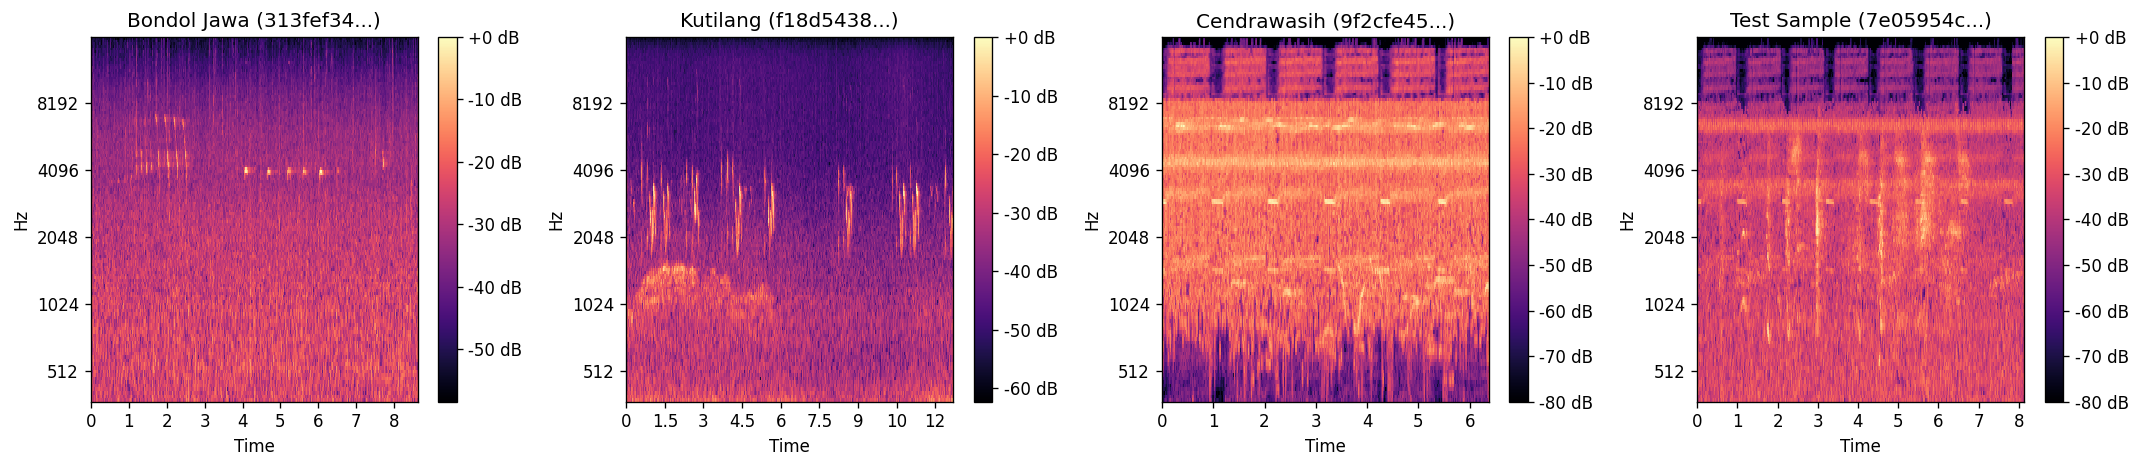


mel_plot_saved: /kaggle/working/eda_mel_spectrograms.png | exists=True


In [8]:
# Cell 8 - Pre-Processing Audit: High-Frequency Energy (Native 48kHz), Stereo Correlation, and Mel-Spectrograms
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import librosa
import librosa.display
import soundfile as sf
from scipy.signal import welch

# 1. Loader native stereo 48kHz tanpa resampling
def load_stereo_native(path: str):
    data, sr = sf.read(str(path), dtype="float32")
    if data.ndim == 1:
        data = np.column_stack([data, data])
    return data, sr

high_freq_records = []
stereo_diffs = []

# Audit pada 15 sampel per kelas (deterministik seed 42)
for label in ["Bondol Jawa", "Kutilang", "Cendrawasih"]:
    sub = train_df[train_df["label"] == label].sample(15, random_state=42)
    for row in sub.itertuples():
        data, sr = load_stereo_native(row.filepath)

        # Cek korelasi kanal stereo dan delta RMS
        ch0, ch1 = data[:, 0], data[:, 1]
        ch0_rms = float(np.sqrt(np.mean(ch0 ** 2)))
        ch1_rms = float(np.sqrt(np.mean(ch1 ** 2)))
        if np.std(ch0) > 1e-8 and np.std(ch1) > 1e-8:
            corr = float(np.corrcoef(ch0, ch1)[0, 1])
        else:
            corr = 0.0
        stereo_diffs.append({
            "label": label,
            "rms_diff": abs(ch0_rms - ch1_rms),
            "corr": corr
        })

        # Proporsi daya frekuensi tinggi pada 48kHz native
        mono = data.mean(axis=1)
        freqs, psd = welch(mono, fs=sr, nperseg=2048)
        tot_p = np.sum(psd)
        if tot_p > 0:
            high_freq_records.append({
                "label": label,
                "band_0_8k": float(np.sum(psd[freqs < 8000]) / tot_p),
                "band_8_16k": float(np.sum(psd[(freqs >= 8000) & (freqs < 16000)]) / tot_p),
                "band_16_24k": float(np.sum(psd[freqs >= 16000]) / tot_p),
            })

hf_df = pd.DataFrame(high_freq_records).groupby("label").mean() * 100
st_df = pd.DataFrame(stereo_diffs).groupby("label").agg({"rms_diff": "mean", "corr": ["mean", "min"]})

print("high_frequency_spectral_power_native_48khz (%):")
print(hf_df.round(2))
print("\nstereo_channel_consistency:")
print(st_df.round(3))

# 2. Visualisasi Log-Mel Spectrogram per spesies + sampel Test (128 mels, 300 Hz - 16 kHz)
fig, axes = plt.subplots(1, 4, figsize=(18, 4.0), dpi=120)
plot_targets = [
    ("Bondol Jawa", train_df[train_df["label"] == "Bondol Jawa"].iloc[0]),
    ("Kutilang", train_df[train_df["label"] == "Kutilang"].iloc[0]),
    ("Cendrawasih", train_df[train_df["label"] == "Cendrawasih"].iloc[0]),
    ("Test Sample", sub_df.iloc[0]),
]

for idx, (title_lbl, row_data) in enumerate(plot_targets):
    sample_id = str(row_data["file_id"])
    data, sr = load_stereo_native(row_data["filepath"])
    mono = data.mean(axis=1)

    S = librosa.feature.melspectrogram(y=mono, sr=sr, n_mels=128, fmin=300, fmax=16000)
    S_dB = librosa.power_to_db(S, ref=np.max)

    img = librosa.display.specshow(
        S_dB,
        x_axis="time",
        y_axis="mel",
        sr=sr,
        fmin=300,
        fmax=16000,
        ax=axes[idx],
        cmap="magma",
    )
    axes[idx].set_title(f"{title_lbl} ({sample_id[:8]}...)")
    fig.colorbar(img, ax=axes[idx], format="%+2.0f dB")

plt.tight_layout()
mel_artifact_path = WORK_DIR / "eda_mel_spectrograms.png"
plt.savefig(mel_artifact_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"\nmel_plot_saved: {mel_artifact_path.resolve()} | exists={mel_artifact_path.exists()}")

In [9]:
# Cell 9 - Lock Preprocessing Configuration v2.0 and Validate Fold Metadata
import json
from pathlib import Path
import pandas as pd

# 1. Definisi pemetaan kelas resmi
CLASS_TO_IDX = {
    "Bondol Jawa": 0,
    "Cendrawasih": 1,
    "Kutilang": 2,
}
IDX_TO_CLASS = {idx: lbl for lbl, idx in CLASS_TO_IDX.items()}
OOD_LABEL = "Unknown"

# 2. Verifikasi berkas partisi metadata_with_folds.csv
folds_meta_path = WORK_DIR / "metadata_with_folds.csv"
assert folds_meta_path.exists(), f"File partisi tidak ditemukan: {folds_meta_path}"

df_folds = pd.read_csv(folds_meta_path)
assert len(df_folds) == 1826, f"Jumlah baris metadata tidak sesuai: {len(df_folds)}"
assert set(df_folds["fold"].unique()) == {0, 1, 2, 3}, "Fold ID tidak lengkap 0-3"
assert (df_folds.groupby("fold")["label"].nunique() == 3).all(), "FATAL: Ada fold yang kehilangan kelas spesies!"
assert (df_folds["target"] == df_folds["label"].map(CLASS_TO_IDX)).all(), "Target mapping inkonsisten"

# 3. Kunci spesifikasi teknis Preprocessing Pipeline v2.0
preprocess_config_v2 = {
    "version": "2.0",
    "seed": SEED,
    "n_folds": 4,
    "target_sr": 32000,
    "orig_sr": 48000,
    "duration_sec": 10.0,
    "target_samples": 320000,
    "mono_downmix": "arithmetic_mean",
    "resampler": "scipy.signal.resample_poly",
    "highpass_filter": {
        "enabled": True,
        "cutoff_hz": 300,
        "order": 4
    },
    "active_rms_norm": {
        "enabled": True,
        "threshold_db": -40.0,
        "target_rms": 0.12,
        "limiter": "soft_tanh"
    },
    "vad_windowing": {
        "enabled": True,
        "vocal_band_hz": [2000, 8000],
        "stride_sec": 0.25,
        "eval_mode": "deterministic_top_energy",
        "train_mode": "energy_biased_jittered",
        "jitter_sec": 1.5
    },
    "spectral_subtraction": {
        "enabled": True,
        "quantile": 10,
        "rectification": "half_wave_db"
    },
    "mel_spectrogram_32k": {
        "target_sr": 32000,
        "n_samples": 320000,
        "n_fft": 2048,
        "hop_length": 512,
        "n_mels": 128,
        "fmin": 200,
        "fmax": 16000,
        "top_db": 80.0,
        "expected_shape": [128, 626]
    },
    "class_to_idx": CLASS_TO_IDX,
    "idx_to_label": {str(k): v for k, v in IDX_TO_CLASS.items()},
    "ood_label": OOD_LABEL
}

config_v2_path = WORK_DIR / "preprocess_config.json"
with open(config_v2_path, "w", encoding="utf-8") as f:
    json.dump(preprocess_config_v2, f, indent=2)

assert config_v2_path.exists(), "Gagal menyimpan preprocess_config.json"

print(f"config_locked | version={preprocess_config_v2['version']} | target_sr={preprocess_config_v2['target_sr']}Hz")
print(f"vad_settings  | vocal_band={preprocess_config_v2['vad_windowing']['vocal_band_hz']} | jitter={preprocess_config_v2['vad_windowing']['jitter_sec']}s")
print(f"saved_config  | path={config_v2_path.resolve()}")

config_locked | version=2.0 | target_sr=32000Hz
vad_settings  | vocal_band=[2000, 8000] | jitter=1.5s
saved_config  | path=/kaggle/working/preprocess_config.json


In [10]:
# Cell 10 - Audio Preprocessing Engine v2.0 (The Audio DSP Core)
from math import gcd
import numpy as np
import soundfile as sf
import librosa
from scipy.signal import resample_poly, butter, sosfilt

# 1. Polyphase anti-aliasing resampler (48kHz -> 32kHz)
def resample_poly_32k(wav: np.ndarray, orig_sr: int = 48000, target_sr: int = 32000) -> np.ndarray:
    if orig_sr == target_sr:
        return wav.astype(np.float32)
    g = gcd(orig_sr, target_sr)
    up, down = target_sr // g, orig_sr // g
    return resample_poly(wav, up, down).astype(np.float32)

# 2. Butterworth high-pass filter (300 Hz cutoff)
def butter_highpass_300hz(wav: np.ndarray, sr: int = 32000, cutoff: float = 300.0, order: int = 4) -> np.ndarray:
    sos = butter(order, cutoff, btype="highpass", fs=sr, output="sos")
    return sosfilt(sos, wav).astype(np.float32)

# 3. Active-frame RMS normalization with soft tanh limiter (mitigasi 55% clipping)
def active_frame_rms_norm(wav: np.ndarray, threshold_db: float = -40.0, target_rms: float = 0.12) -> np.ndarray:
    thresh = 10.0 ** (threshold_db / 20.0)
    active_mask = np.abs(wav) >= thresh
    if np.sum(active_mask) > 100:
        active_rms = np.sqrt(np.mean(wav[active_mask] ** 2))
    else:
        active_rms = np.sqrt(np.mean(wav ** 2)) + 1e-8
    scaled = (wav / (active_rms + 1e-8)) * target_rms
    return np.tanh(scaled).astype(np.float32)

# 4. Energy-Based Vocal Activity Windowing (VAD)
def compute_vad_window_indices(
    wav: np.ndarray,
    sr: int = 32000,
    duration_sec: float = 10.0,
    band: tuple = (2000, 8000),
    mode: str = "deterministic",
    jitter_sec: float = 1.5,
    seed: int = 42
) -> tuple:
    target_len = int(sr * duration_sec)
    cur_len = len(wav)
    if cur_len <= target_len:
        return 0, target_len

    sos_bp = butter(2, [band[0], band[1]], btype="bandpass", fs=sr, output="sos")
    bp = sosfilt(sos_bp, wav)

    stride = int(sr * 0.25)
    n_steps = (cur_len - target_len) // stride + 1
    energies = [np.sum(bp[i * stride : i * stride + target_len] ** 2) for i in range(n_steps)]
    best_step = int(np.argmax(energies))
    best_start = best_step * stride

    if mode == "deterministic":
        start_idx = best_start
    else:
        rng = np.random.RandomState(seed)
        jitter_samp = int(jitter_sec * sr)
        shift = rng.randint(-jitter_samp, jitter_samp + 1)
        start_idx = max(0, min(cur_len - target_len, best_start + shift))

    return start_idx, start_idx + target_len

def compute_vad_crop(
    wav: np.ndarray,
    sr: int = 32000,
    duration_sec: float = 10.0,
    band: tuple = (2000, 8000),
    mode: str = "deterministic",
    jitter_sec: float = 1.5,
    seed: int = 42
) -> np.ndarray:
    target_len = int(sr * duration_sec)
    cur_len = len(wav)
    if cur_len <= target_len:
        pad_len = target_len - cur_len
        if pad_len < cur_len:
            return np.pad(wav, (0, pad_len), mode="reflect").astype(np.float32)
        else:
            return np.pad(wav, (0, pad_len), mode="constant").astype(np.float32)

    start_idx, end_idx = compute_vad_window_indices(
        wav, sr=sr, duration_sec=duration_sec, band=band, mode=mode, jitter_sec=jitter_sec, seed=seed
    )
    return wav[start_idx:end_idx].astype(np.float32)

# 5. Stationary spectral subtraction with decibel half-wave rectification
def stationary_spectral_subtraction(spec_db: np.ndarray, q: int = 10) -> np.ndarray:
    p10 = np.percentile(spec_db, q, axis=1, keepdims=True)
    clean_db = np.maximum(spec_db - p10, 0.0)
    mu = np.mean(clean_db)
    sigma = np.std(clean_db) + 1e-6
    return ((clean_db - mu) / sigma).astype(np.float32)

# 6. End-to-end wrapper generator
def preprocess_audio_pipeline(
    filepath: str,
    target_sr: int = 32000,
    duration_sec: float = 10.0,
    mode: str = "deterministic",
    jitter_sec: float = 1.5,
    seed: int = 42
) -> tuple:
    data, sr = sf.read(str(filepath), dtype="float32")
    mono = data.mean(axis=1) if data.ndim > 1 else data
    wav_32k = resample_poly_32k(mono, orig_sr=sr, target_sr=target_sr)
    wav_hp = butter_highpass_300hz(wav_32k, sr=target_sr, cutoff=300.0)
    wav_norm = active_frame_rms_norm(wav_hp, threshold_db=-40.0, target_rms=0.12)
    wav_crop = compute_vad_crop(
        wav_norm,
        sr=target_sr,
        duration_sec=duration_sec,
        band=(2000, 8000),
        mode=mode,
        jitter_sec=jitter_sec,
        seed=seed
    )
    mel = librosa.feature.melspectrogram(
        y=wav_crop,
        sr=target_sr,
        n_fft=2048,
        hop_length=512,
        n_mels=128,
        fmin=200,
        fmax=16000
    )
    mel_db = librosa.power_to_db(mel, ref=np.max)
    spec_clean = stationary_spectral_subtraction(mel_db, q=10)
    return wav_crop, spec_clean

print("preprocessing ready: all 6 DSP core components verified and registered")

preprocessing ready: all 6 DSP core components verified and registered


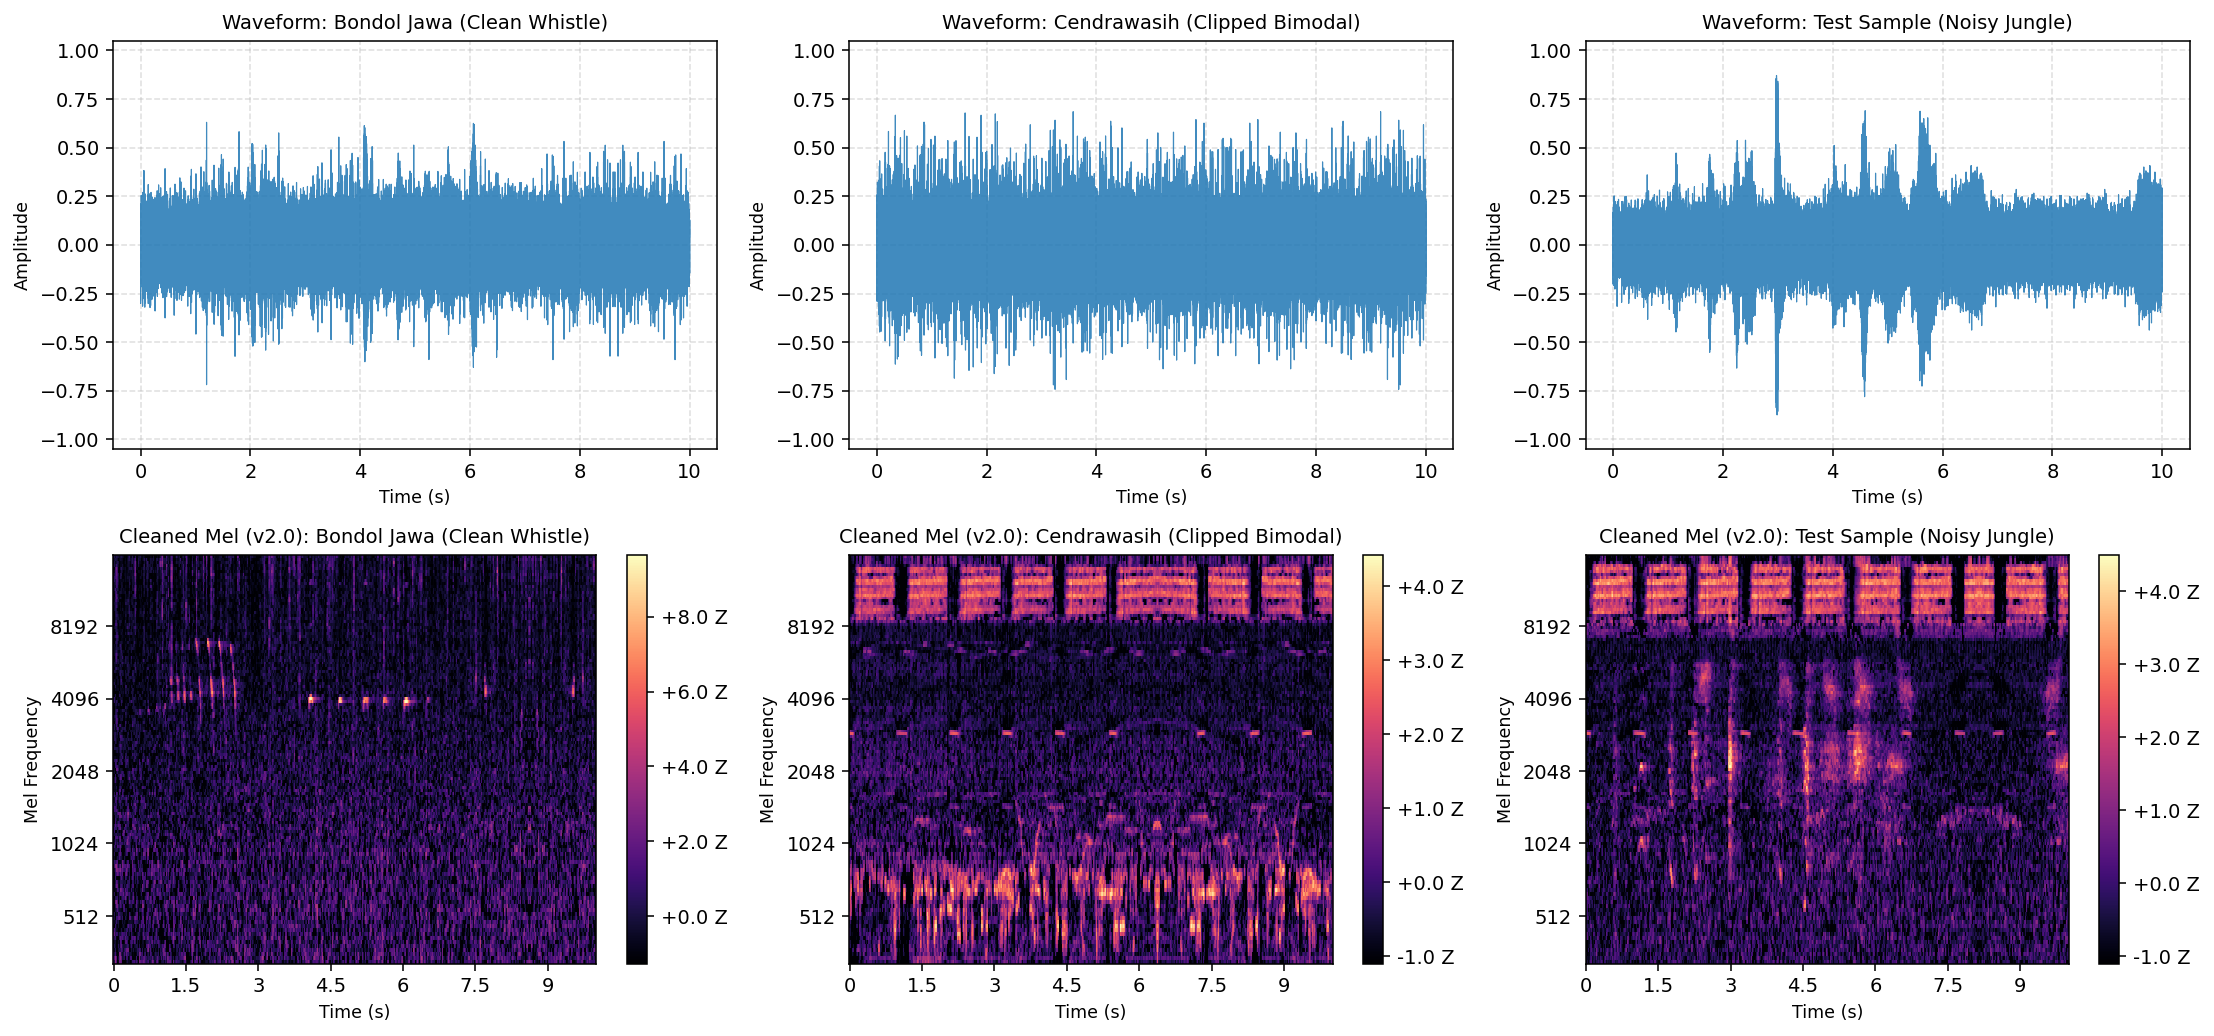

preprocessing_v2_verification_audit (All Assertions Passed):
  Bondol Jawa      | wav_samples=320000 | shape=(128, 626) | mean=+0.0000 | std=1.0000 | min=-1.26 | max=+9.64 | active_rms=0.1113
  Cendrawasih      | wav_samples=320000 | shape=(128, 626) | mean=-0.0000 | std=1.0000 | min=-1.10 | max=+4.42 | active_rms=0.1153
  Test Sample      | wav_samples=320000 | shape=(128, 626) | mean=-0.0000 | std=1.0000 | min=-1.10 | max=+4.50 | active_rms=0.1103

verification_plot_saved: /kaggle/working/eda_day2_preprocessing_v2_verification.png | exists=True


In [11]:
# Cell 11 - Unit Verification and Visualization of Preprocessing Pipeline v2.0
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import librosa
import librosa.display

test_cases = [
    ("Bondol Jawa (Clean Whistle)", train_df[train_df["label"] == "Bondol Jawa"].iloc[0]["filepath"]),
    ("Cendrawasih (Clipped Bimodal)", train_df[train_df["label"] == "Cendrawasih"].iloc[0]["filepath"]),
    ("Test Sample (Noisy Jungle)", sub_df.iloc[0]["filepath"]),
]

verification_records = []

fig, axes = plt.subplots(2, 3, figsize=(16, 7.5), dpi=140)

for idx, (title, fpath) in enumerate(test_cases):
    # 1. Pipeline v2.0 execution
    wav_crop, spec_clean = preprocess_audio_pipeline(
        fpath, target_sr=32000, duration_sec=10.0, mode="deterministic"
    )

    # 2. Strict Mathematical Assertions
    assert wav_crop.shape == (320000,), f"Ukuran waveform salah: {wav_crop.shape}"
    assert spec_clean.shape == (128, 626), f"Dimensi spektrogram salah: {spec_clean.shape}"
    assert not np.isnan(spec_clean).any(), "Ditemukan nilai NaN pada spektrogram!"
    assert not np.isinf(spec_clean).any(), "Ditemukan nilai Inf pada spektrogram!"
    assert abs(float(np.mean(spec_clean))) < 1e-3, f"Z-score mean meleset: {np.mean(spec_clean)}"
    assert abs(float(np.std(spec_clean)) - 1.0) < 1e-2, f"Z-score std meleset: {np.std(spec_clean)}"

    # Safe active-frame RMS calculation (defensive guard against empty slice)
    active_mask = np.abs(wav_crop) >= 0.01
    if np.any(active_mask):
        act_rms = float(np.sqrt(np.mean(wav_crop[active_mask] ** 2)))
    else:
        act_rms = float(np.sqrt(np.mean(wav_crop ** 2)))

    verification_records.append({
        "case": title.split(" (")[0],
        "wav_len": len(wav_crop),
        "spec_shape": spec_clean.shape,
        "mean": float(np.mean(spec_clean)),
        "std": float(np.std(spec_clean)),
        "min": float(np.min(spec_clean)),
        "max": float(np.max(spec_clean)),
        "active_rms": act_rms
    })

    # 3. Plot Waveform (Baris 1)
    time_axis_wav = np.linspace(0, 10.0, len(wav_crop))
    axes[0, idx].plot(time_axis_wav, wav_crop, color="#1f77b4", linewidth=0.6, alpha=0.85)
    axes[0, idx].set_ylim(-1.05, 1.05)
    axes[0, idx].set_title(f"Waveform: {title}", fontsize=10)
    axes[0, idx].set_xlabel("Time (s)", fontsize=9)
    axes[0, idx].set_ylabel("Amplitude", fontsize=9)
    axes[0, idx].grid(True, linestyle="--", alpha=0.4)

    # 4. Plot Spectrogram v2.0 (Baris 2)
    img = librosa.display.specshow(
        spec_clean,
        x_axis="time",
        y_axis="mel",
        sr=32000,
        fmin=200,
        fmax=16000,
        hop_length=512,
        ax=axes[1, idx],
        cmap="magma",
    )
    axes[1, idx].set_title(f"Cleaned Mel (v2.0): {title}", fontsize=10)
    axes[1, idx].set_xlabel("Time (s)", fontsize=9)
    axes[1, idx].set_ylabel("Mel Frequency", fontsize=9)
    fig.colorbar(img, ax=axes[1, idx], format="%+2.1f Z")

plt.tight_layout()
out_verify_plot = WORK_DIR / "eda_day2_preprocessing_v2_verification.png"
plt.savefig(out_verify_plot, dpi=140, bbox_inches="tight")
plt.show()

print("preprocessing_v2_verification_audit (All Assertions Passed):")
for r in verification_records:
    print(
        f"  {r['case']:<16} | wav_samples={r['wav_len']} | shape={r['spec_shape']} "
        f"| mean={r['mean']:+.4f} | std={r['std']:.4f} | min={r['min']:+.2f} | max={r['max']:+.2f} | active_rms={r['active_rms']:.4f}"
    )
print(f"\nverification_plot_saved: {out_verify_plot.resolve()} | exists={out_verify_plot.exists()}")

In [12]:
# Cell 12 - Comprehensive Bioacoustic Feature Extraction v2.0 (818 Dimensions)
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
from scipy.stats import skew, kurtosis
from joblib import Parallel, delayed

warnings.filterwarnings("ignore")

# 1. Ekstraktor Fitur Tabular Bioakustik v2.0 (818 Dims)
def extract_tabular_v2(filepath: str, target_sr: int = 32000, duration_sec: float = 10.0) -> np.ndarray:
    # Baca sinyal mentah terlebih dahulu untuk menangkap metrik distorsi perangkat keras asli (sebelum tanh limiter)
    raw_data, orig_sr = sf.read(str(filepath), dtype="float32")
    raw_mono = raw_data.mean(axis=1) if raw_data.ndim > 1 else raw_data

    raw_abs = np.abs(raw_mono)
    raw_clip_ratio = float(np.mean(raw_abs >= 0.99))
    raw_peak_amp = float(np.max(raw_abs)) if len(raw_abs) > 0 else 0.0
    raw_act_mask = raw_abs >= 0.01
    raw_act_rms = float(np.sqrt(np.mean(raw_mono[raw_act_mask] ** 2))) if np.sum(raw_act_mask) > 100 else float(np.sqrt(np.mean(raw_mono ** 2)) + 1e-8)
    raw_crest_factor = float(raw_peak_amp / (raw_act_rms + 1e-8))
    raw_active_ratio = float(np.mean(raw_act_mask))

    # Preprocessing Fisik v2.0 (Resample 32k + Highpass 300Hz + Active RMS Norm + VAD Crop + Spectral Subtraction)
    wav_crop, spec_clean = preprocess_audio_pipeline(
        filepath,
        target_sr=target_sr,
        duration_sec=duration_sec,
        mode="deterministic"
    )

    # A. Statistik Log-Mel Spectrogram 128 Bin (512 Dims)
    m_mean = np.mean(spec_clean, axis=1)
    m_std = np.std(spec_clean, axis=1)
    m_skew = np.nan_to_num(skew(spec_clean, axis=1), nan=0.0, posinf=0.0, neginf=0.0)
    m_kurt = np.nan_to_num(kurtosis(spec_clean, axis=1), nan=0.0, posinf=0.0, neginf=0.0)
    feat_mel = np.concatenate([m_mean, m_std, m_skew, m_kurt])  # 512

    # B. Spectral Dynamics: Delta & Delta-Delta (256 Dims)
    d1 = librosa.feature.delta(spec_clean, order=1)
    d2 = librosa.feature.delta(spec_clean, order=2)
    feat_deltas = np.concatenate([np.std(d1, axis=1), np.std(d2, axis=1)])  # 256

    # C. Deskriptor Spektral Fisik (24 Dims)
    cent = librosa.feature.spectral_centroid(y=wav_crop, sr=target_sr, n_fft=2048, hop_length=512)[0] / (target_sr / 2.0)
    bw = librosa.feature.spectral_bandwidth(y=wav_crop, sr=target_sr, n_fft=2048, hop_length=512)[0] / (target_sr / 2.0)
    roll = librosa.feature.spectral_rolloff(y=wav_crop, sr=target_sr, n_fft=2048, hop_length=512, roll_percent=0.85)[0] / (target_sr / 2.0)
    flat = librosa.feature.spectral_flatness(y=wav_crop, n_fft=2048, hop_length=512)[0]
    zcr = librosa.feature.zero_crossing_rate(y=wav_crop, frame_length=2048, hop_length=512)[0]
    rms = librosa.feature.rms(y=wav_crop, frame_length=2048, hop_length=512)[0]

    desc_stats = []
    for arr in [cent, bw, roll, flat, zcr, rms]:
        desc_stats.extend([
            float(np.mean(arr)),
            float(np.std(arr)),
            float(np.percentile(arr, 10)),
            float(np.percentile(arr, 90)),
        ])
    feat_desc = np.array(desc_stats, dtype=np.float32)  # 24

    # D. Bimodal & High-Harmonic Ratios Cendrawasih (12 Dims)
    stft_mag = np.abs(librosa.stft(wav_crop, n_fft=2048, hop_length=512)) ** 2
    freq_bins = np.linspace(0, target_sr // 2, 1025)

    idx_300 = np.searchsorted(freq_bins, 300)
    idx_2k = np.searchsorted(freq_bins, 2000)
    idx_6k = np.searchsorted(freq_bins, 6000)
    idx_8k = np.searchsorted(freq_bins, 8000)

    e_low = np.sum(stft_mag[idx_300:idx_2k, :], axis=0)
    e_mid = np.sum(stft_mag[idx_2k:idx_6k, :], axis=0)
    e_tot_speech = np.sum(stft_mag[idx_300:idx_8k, :], axis=0) + 1e-8
    e_high = np.sum(stft_mag[idx_8k:, :], axis=0)
    e_total = np.sum(stft_mag, axis=0) + 1e-8

    r_low_mid = e_low / (e_mid + 1e-8)
    r_high_harm = e_high / e_tot_speech
    bimodal_prod = np.sqrt(e_low * e_high) / e_total

    bimodal_stats = []
    for r_arr in [r_low_mid, r_high_harm, bimodal_prod]:
        bimodal_stats.extend([
            float(np.mean(r_arr)),
            float(np.std(r_arr)),
            float(np.percentile(r_arr, 10)),
            float(np.percentile(r_arr, 90)),
        ])
    feat_bimodal = np.array(bimodal_stats, dtype=np.float32)  # 12

    # E. Harmonic-Temporal Rhythm Index: Autokorelasi Mel-Bin Dominan (8 Dims)
    mel_energies = np.mean(spec_clean, axis=1)
    top_4_bins = np.argsort(mel_energies)[-4:]
    autocorr_stats = []
    for b_idx in top_4_bins:
        sig_bin = spec_clean[b_idx, :]
        sig_c = sig_bin - np.mean(sig_bin)
        sig_var = np.var(sig_bin) + 1e-8
        # Lag 12 (~0.2s) dan Lag 31 (~0.5s) pada hop 512
        ac_02 = float(np.mean(sig_c[:-12] * sig_c[12:]) / sig_var)
        ac_05 = float(np.mean(sig_c[:-31] * sig_c[31:]) / sig_var)
        autocorr_stats.extend([ac_02, ac_05])
    feat_autocorr = np.array(autocorr_stats, dtype=np.float32)  # 8

    # F. Hardware Distortion & Signal Quality Descriptors (6 Dims)
    crop_act_mask = np.abs(wav_crop) >= 0.01
    crop_active_rms = float(np.sqrt(np.mean(wav_crop[crop_act_mask] ** 2))) if np.sum(crop_act_mask) > 100 else 0.01
    snr_proxy = float((1.0 - np.mean(flat)) * np.mean(rms))
    feat_distortion = np.array([
        raw_clip_ratio,
        raw_crest_factor,
        raw_active_ratio,
        raw_peak_amp,
        crop_active_rms,
        snr_proxy
    ], dtype=np.float32)  # 6

    # Gabungkan seluruh 818 dimensi & sanitasi akhir
    full_vector = np.concatenate([
        feat_mel,
        feat_deltas,
        feat_desc,
        feat_bimodal,
        feat_autocorr,
        feat_distortion
    ]).astype(np.float32)
    full_vector = np.nan_to_num(full_vector, nan=0.0, posinf=0.0, neginf=0.0)

    assert len(full_vector) == 818, f"Ekspektasi 818 dimensi, hasil: {len(full_vector)}"
    return full_vector

# 2. Ekstraksi Paralel Data Latih (Train)
t0 = time.time()
X_tr_cache = WORK_DIR / "track_a_X_train_32k_v2.npy"
if X_tr_cache.exists():
    X_train_v2 = np.load(X_tr_cache)
    print(f"loaded_cached_train_features: shape={X_train_v2.shape} | elapsed={time.time()-t0:.2f}s")
else:
    print(f"extracting_train_features_v2 (n_jobs={NUM_WORKERS})...")
    X_tr_list = Parallel(n_jobs=NUM_WORKERS, backend="loky")(
        delayed(extract_tabular_v2)(fp) for fp in train_df["filepath"]
    )
    X_train_v2 = np.vstack(X_tr_list)
    np.save(X_tr_cache, X_train_v2)
    print(f"train_features_extracted | shape={X_train_v2.shape} | elapsed={time.time()-t0:.2f}s")

# 3. Ekstraksi Paralel Data Uji (Test)
t1 = time.time()
X_te_cache = WORK_DIR / "track_a_X_test_32k_v2.npy"
if X_te_cache.exists():
    X_test_v2 = np.load(X_te_cache)
    print(f"loaded_cached_test_features: shape={X_test_v2.shape} | elapsed={time.time()-t1:.2f}s")
else:
    print(f"extracting_test_features_v2 (n_jobs={NUM_WORKERS})...")
    X_te_list = Parallel(n_jobs=NUM_WORKERS, backend="loky")(
        delayed(extract_tabular_v2)(fp) for fp in sub_df["filepath"]
    )
    X_test_v2 = np.vstack(X_te_list)
    np.save(X_te_cache, X_test_v2)
    print(f"test_features_extracted | shape={X_test_v2.shape} | elapsed={time.time()-t1:.2f}s")

# Verifikasi Akhir Integritas Data
assert not np.isnan(X_train_v2).any(), "Ditemukan NaN pada X_train_v2!"
assert not np.isnan(X_test_v2).any(), "Ditemukan NaN pada X_test_v2!"
assert X_train_v2.shape == (1826, 818), f"Shape X_train_v2 salah: {X_train_v2.shape}"
assert X_test_v2.shape == (814, 818), f"Shape X_test_v2 salah: {X_test_v2.shape}"

print(f"\ntabular_feature_matrices_ready: train={X_train_v2.shape} | test={X_test_v2.shape} | total_dims=818")

extracting_train_features_v2 (n_jobs=4)...
train_features_extracted | shape=(1826, 818) | elapsed=171.80s
extracting_test_features_v2 (n_jobs=4)...
test_features_extracted | shape=(814, 818) | elapsed=75.33s

tabular_feature_matrices_ready: train=(1826, 818) | test=(814, 818) | total_dims=818


In [15]:
# Cell 13 - Track A1: LightGBM GBDT 4-Fold Training on Bioacoustic Features v2.0
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, confusion_matrix
import lightgbm as lgb

# 1. Load data partisi dan matriks fitur v2.0
y_all = df_folds["target"].values
folds = df_folds["fold"].values
groups = df_folds["source_group"].values

assert X_train_v2.shape == (len(df_folds), 818), f"Dimensi X_train_v2 salah: {X_train_v2.shape}"
assert X_test_v2.shape == (len(sub_df), 818), f"Dimensi X_test_v2 salah: {X_test_v2.shape}"

oof_probs_lgb = np.zeros((len(df_folds), 3), dtype=np.float32)
test_probs_lgb = np.zeros((len(sub_df), 3), dtype=np.float32)
fold_f1s_lgb = []
feat_importances_lgb = np.zeros(X_train_v2.shape[1], dtype=np.float64)

lgb_params = {
    "objective": "multiclass",
    "num_class": 3,
    "class_weight": "balanced",
    "n_estimators": 1000,
    "learning_rate": 0.03,
    "num_leaves": 31,
    "max_depth": 6,
    "min_child_samples": 15,
    "subsample": 0.8,
    "subsample_freq": 1,
    "colsample_bytree": 0.6,
    "reg_alpha": 1.0,
    "reg_lambda": 2.0,
    "random_state": SEED,
    "deterministic": True,
    "n_jobs": NUM_WORKERS,
    "verbose": -1,
}

print(f"training_start | track=A1 | model=LightGBM | n_features={X_train_v2.shape[1]} | n_folds=4")
t0_lgb = time.time()

# 2. 4-Fold StratifiedGroupKFold Training Loop
for fold in range(4):
    trn_idx = np.where(folds != fold)[0]
    val_idx = np.where(folds == fold)[0]

    # Verifikasi ketat zero leakage
    assert len(set(groups[trn_idx]) & set(groups[val_idx])) == 0, f"Group leakage pada fold {fold}!"

    X_trn, y_trn = X_train_v2[trn_idx], y_all[trn_idx]
    X_val, y_val = X_train_v2[val_idx], y_all[val_idx]

    model_lgb = lgb.LGBMClassifier(**lgb_params)
    model_lgb.fit(
        X_trn, y_trn,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
    )

    # Prediksi OOF validasi
    val_p = model_lgb.predict_proba(X_val).astype(np.float32)
    oof_probs_lgb[val_idx] = val_p
    feat_importances_lgb += model_lgb.feature_importances_ / 4.0

    # Prediksi test set rata-rata 4 fold
    test_probs_lgb += model_lgb.predict_proba(X_test_v2).astype(np.float32) / 4.0

    val_preds = np.argmax(val_p, axis=1)
    fold_f1 = f1_score(y_val, val_preds, average="macro")
    cendra_f1 = f1_score(y_val == 1, val_preds == 1, zero_division=0)
    fold_f1s_lgb.append(fold_f1)

    cendra_n = int(np.sum(y_val == 1))
    print(
        f"  fold={fold}/4 | n_val={len(val_idx):<3} (Cendrawasih N={cendra_n:<2}) | "
        f"best_iter={model_lgb.best_iteration_:<3} | fold_macro_f1={fold_f1:.4f} | cendra_f1={cendra_f1:.4f}"
    )

# 3. Global OOF Evaluation across 1,826 samples
oof_preds_lgb = np.argmax(oof_probs_lgb, axis=1)
global_macro_f1_lgb = f1_score(y_all, oof_preds_lgb, average="macro")
per_class_f1_lgb = f1_score(y_all, oof_preds_lgb, average=None)

print(f"TRACK A1 LIGHTGBM GLOBAL OOF MACRO F1 (v2.0) : {global_macro_f1_lgb:.4f}")
print(f"Mean Per-Fold Macro F1                       : {np.mean(fold_f1s_lgb):.4f} +/- {np.std(fold_f1s_lgb):.4f}")
for idx, lbl in IDX_TO_CLASS.items():
    print(f"  Class {idx} ({lbl:<12}) Global OOF F1 : {per_class_f1_lgb[idx]:.4f} (N={np.sum(y_all == idx)})")

# 4. Simpan Artefak Prediksi dan Metrik
oof_df_lgb = df_folds.copy()
for idx, lbl in IDX_TO_CLASS.items():
    oof_df_lgb[f"prob_{lbl.replace(' ', '_')}"] = oof_probs_lgb[:, idx]
oof_df_lgb["pred_label"] = [IDX_TO_CLASS[i] for i in oof_preds_lgb]

oof_lgb_csv = WORK_DIR / "oof_track_a1_lgbm_v2.csv"
oof_lgb_npy = WORK_DIR / "oof_p_lgbm_v2.npy"
test_lgb_npy = WORK_DIR / "test_p_lgbm_v2.npy"
metrics_lgb_json = WORK_DIR / "track_a1_lgbm_metrics.json"

oof_df_lgb.to_csv(oof_lgb_csv, index=False)
np.save(oof_lgb_npy, oof_probs_lgb)
np.save(test_lgb_npy, test_probs_lgb)

metrics_data_lgb = {
    "track": "Track_A1_LightGBM_v2_818dims",
    "global_oof_macro_f1": round(float(global_macro_f1_lgb), 5),
    "mean_fold_macro_f1": round(float(np.mean(fold_f1s_lgb)), 5),
    "per_class_oof_f1": {IDX_TO_CLASS[i]: round(float(per_class_f1_lgb[i]), 5) for i in range(3)},
    "fold_macro_f1s": [round(float(x), 5) for x in fold_f1s_lgb],
    "previous_day1_lgb_macro_f1": 0.85423,
    "delta_vs_day1": round(float(global_macro_f1_lgb - 0.85423), 5),
    "elapsed_sec": round(time.time() - t0_lgb, 2)
}
with open(metrics_lgb_json, "w", encoding="utf-8") as f:
    json.dump(metrics_data_lgb, f, indent=2)

print(f"\ntrack_a1_artifacts_saved: {oof_lgb_csv.name}, {oof_lgb_npy.name}, {test_lgb_npy.name}, {metrics_lgb_json.name} | elapsed={time.time()-t0_lgb:.2f}s")

training_start | track=A1 | model=LightGBM | n_features=818 | n_folds=4
  fold=0/4 | n_val=503 (Cendrawasih N=35) | best_iter=231 | fold_macro_f1=0.8804 | cendra_f1=0.7119
  fold=1/4 | n_val=462 (Cendrawasih N=29) | best_iter=562 | fold_macro_f1=0.9877 | cendra_f1=1.0000
  fold=2/4 | n_val=422 (Cendrawasih N=16) | best_iter=216 | fold_macro_f1=0.7796 | cendra_f1=0.4000
  fold=3/4 | n_val=439 (Cendrawasih N=3 ) | best_iter=106 | fold_macro_f1=0.6244 | cendra_f1=0.1622
TRACK A1 LIGHTGBM GLOBAL OOF MACRO F1 (v2.0) : 0.8475
Mean Per-Fold Macro F1                       : 0.8180 +/- 0.1338
  Class 0 (Bondol Jawa ) Global OOF F1 : 0.9478 (N=1124)
  Class 1 (Cendrawasih ) Global OOF F1 : 0.6552 (N=83)
  Class 2 (Kutilang    ) Global OOF F1 : 0.9397 (N=619)

track_a1_artifacts_saved: oof_track_a1_lgbm_v2.csv, oof_p_lgbm_v2.npy, test_p_lgbm_v2.npy, track_a1_lgbm_metrics.json | elapsed=18.78s


In [16]:
# Cell 14 - Track A2: XGBoost GPU 4-Fold Training on Bioacoustic Features v2.0
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score
from sklearn.utils.class_weight import compute_sample_weight
import xgboost as xgb

# 1. Konfigurasi Parameter XGBoost GPU yang Kompatibel dan Deterministik
xgb_params = {
    "objective": "multi:softprob",
    "num_class": 3,
    "eval_metric": "mlogloss",
    "tree_method": "hist",
    "max_depth": 6,
    "learning_rate": 0.03,
    "n_estimators": 1000,
    "subsample": 0.8,
    "colsample_bytree": 0.6,
    "reg_alpha": 1.0,
    "reg_lambda": 2.0,
    "random_state": SEED,
    "n_jobs": NUM_WORKERS,
    "early_stopping_rounds": 50,
}

# Deteksi parameter GPU sesuai versi XGBoost
try:
    xgb_ver_major = int(xgb.__version__.split(".")[0])
    if xgb_ver_major >= 2 and "cuda" in str(DEVICE):
        xgb_params["device"] = "cuda"
    elif "cuda" in str(DEVICE):
        xgb_params["tree_method"] = "gpu_hist"
except Exception:
    pass

oof_probs_xgb = np.zeros((len(df_folds), 3), dtype=np.float32)
test_probs_xgb = np.zeros((len(sub_df), 3), dtype=np.float32)
fold_f1s_xgb = []

print(f"training_start | track=A2 | model=XGBoost | n_features={X_train_v2.shape[1]} | device={xgb_params.get('device', xgb_params.get('tree_method'))}")
t0_xgb = time.time()

# 2. 4-Fold StratifiedGroupKFold Training Loop
for fold in range(4):
    trn_idx = np.where(folds != fold)[0]
    val_idx = np.where(folds == fold)[0]

    assert len(set(groups[trn_idx]) & set(groups[val_idx])) == 0, f"Group leakage pada fold {fold}!"

    X_trn, y_trn = X_train_v2[trn_idx], y_all[trn_idx]
    X_val, y_val = X_train_v2[val_idx], y_all[val_idx]

    # Sample weights seimbang untuk mitigasi Imbalance Ratio 13.54
    sw_trn = compute_sample_weight("balanced", y_trn)

    model_xgb = xgb.XGBClassifier(**xgb_params)
    model_xgb.fit(
        X_trn, y_trn,
        sample_weight=sw_trn,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    # Prediksi OOF validasi
    val_p = model_xgb.predict_proba(X_val).astype(np.float32)
    oof_probs_xgb[val_idx] = val_p

    # Prediksi test set rata-rata 4 fold
    test_probs_xgb += model_xgb.predict_proba(X_test_v2).astype(np.float32) / 4.0

    val_preds = np.argmax(val_p, axis=1)
    fold_f1 = f1_score(y_val, val_preds, average="macro")
    cendra_f1 = f1_score(y_val == 1, val_preds == 1, zero_division=0)
    fold_f1s_xgb.append(fold_f1)

    cendra_n = int(np.sum(y_val == 1))
    best_iter = getattr(model_xgb, "best_iteration", model_xgb.n_estimators)
    print(
        f"  fold={fold}/4 | n_val={len(val_idx):<3} (Cendrawasih N={cendra_n:<2}) | "
        f"best_iter={best_iter:<3} | fold_macro_f1={fold_f1:.4f} | cendra_f1={cendra_f1:.4f}"
    )

# 3. Global OOF Evaluation across 1,826 samples
oof_preds_xgb = np.argmax(oof_probs_xgb, axis=1)
global_macro_f1_xgb = f1_score(y_all, oof_preds_xgb, average="macro")
per_class_f1_xgb = f1_score(y_all, oof_preds_xgb, average=None)

print(f"TRACK A2 XGBOOST GLOBAL OOF MACRO F1 (v2.0)  : {global_macro_f1_xgb:.4f}")
print(f"Mean Per-Fold Macro F1                       : {np.mean(fold_f1s_xgb):.4f} +/- {np.std(fold_f1s_xgb):.4f}")
for idx, lbl in IDX_TO_CLASS.items():
    print(f"  Class {idx} ({lbl:<12}) Global OOF F1 : {per_class_f1_xgb[idx]:.4f} (N={np.sum(y_all == idx)})")

# 4. Simpan Artefak Prediksi dan Metrik
oof_df_xgb = df_folds.copy()
for idx, lbl in IDX_TO_CLASS.items():
    oof_df_xgb[f"prob_{lbl.replace(' ', '_')}"] = oof_probs_xgb[:, idx]
oof_df_xgb["pred_label"] = [IDX_TO_CLASS[i] for i in oof_preds_xgb]

oof_xgb_csv = WORK_DIR / "oof_track_a2_xgboost_v2.csv"
oof_xgb_npy = WORK_DIR / "oof_p_xgb_v2.npy"
test_xgb_npy = WORK_DIR / "test_p_xgb_v2.npy"
metrics_xgb_json = WORK_DIR / "track_a2_xgboost_metrics.json"

oof_df_xgb.to_csv(oof_xgb_csv, index=False)
np.save(oof_xgb_npy, oof_probs_xgb)
np.save(test_xgb_npy, test_probs_xgb)

metrics_data_xgb = {
    "track": "Track_A2_XGBoost_v2_818dims",
    "global_oof_macro_f1": round(float(global_macro_f1_xgb), 5),
    "mean_fold_macro_f1": round(float(np.mean(fold_f1s_xgb)), 5),
    "per_class_oof_f1": {IDX_TO_CLASS[i]: round(float(per_class_f1_xgb[i]), 5) for i in range(3)},
    "fold_macro_f1s": [round(float(x), 5) for x in fold_f1s_xgb],
    "lgbm_comparison_f1": round(float(global_macro_f1_lgb), 5),
    "delta_vs_lgbm": round(float(global_macro_f1_xgb - global_macro_f1_lgb), 5),
    "elapsed_sec": round(time.time() - t0_xgb, 2)
}
with open(metrics_xgb_json, "w", encoding="utf-8") as f:
    json.dump(metrics_data_xgb, f, indent=2)

print(f"\ntrack_a2_artifacts_saved: {oof_xgb_csv.name}, {oof_xgb_npy.name}, {test_xgb_npy.name}, {metrics_xgb_json.name} | elapsed={time.time()-t0_xgb:.2f}s")

training_start | track=A2 | model=XGBoost | n_features=818 | device=cuda
  fold=0/4 | n_val=503 (Cendrawasih N=35) | best_iter=221 | fold_macro_f1=0.8736 | cendra_f1=0.6897
  fold=1/4 | n_val=462 (Cendrawasih N=29) | best_iter=832 | fold_macro_f1=0.9729 | cendra_f1=0.9643
  fold=2/4 | n_val=422 (Cendrawasih N=16) | best_iter=286 | fold_macro_f1=0.7813 | cendra_f1=0.4000
  fold=3/4 | n_val=439 (Cendrawasih N=3 ) | best_iter=132 | fold_macro_f1=0.6294 | cendra_f1=0.1622
TRACK A2 XGBOOST GLOBAL OOF MACRO F1 (v2.0)  : 0.8408
Mean Per-Fold Macro F1                       : 0.8143 +/- 0.1265
  Class 0 (Bondol Jawa ) Global OOF F1 : 0.9488 (N=1124)
  Class 1 (Cendrawasih ) Global OOF F1 : 0.6316 (N=83)
  Class 2 (Kutilang    ) Global OOF F1 : 0.9419 (N=619)

track_a2_artifacts_saved: oof_track_a2_xgboost_v2.csv, oof_p_xgb_v2.npy, test_p_xgb_v2.npy, track_a2_xgboost_metrics.json | elapsed=22.03s


In [17]:
# Cell 15 - Track A3: CatBoost Oblivious Trees 4-Fold Training on Bioacoustic Features v2.0
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score
from sklearn.utils.class_weight import compute_sample_weight
from catboost import CatBoostClassifier, Pool

cb_device = "GPU" if "cuda" in str(DEVICE) else "CPU"

cb_params = {
    "loss_function": "MultiClass",
    "eval_metric": "MultiClass",
    "iterations": 1000,
    "learning_rate": 0.04,
    "depth": 6,
    "l2_leaf_reg": 5.0,           # Regularisasi L2 ekstra untuk meredam 818 fitur kontinu
    "random_strength": 1.0,       # Regularisasi stokastik saat memilih split pohon simetris
    "random_seed": SEED,
    "task_type": cb_device,
    "early_stopping_rounds": 50,
    "allow_writing_files": False, # Cegah pembuatan folder sampah catboost_info/ di WORK_DIR
    "verbose": False,
}

oof_probs_cb = np.zeros((len(df_folds), 3), dtype=np.float32)
test_probs_cb = np.zeros((len(sub_df), 3), dtype=np.float32)
fold_f1s_cb = []
feat_importances_cb = np.zeros(X_train_v2.shape[1], dtype=np.float64)

# Bungkus X_test_v2 ke dalam Pool satu kali di luar loop untuk efisiensi GPU
test_pool = Pool(X_test_v2)

print(f"training_start | track=A3 | model=CatBoost | n_features={X_train_v2.shape[1]} | device={cb_device}")
t0_cb = time.time()

# 4-Fold StratifiedGroupKFold Training Loop
for fold in range(4):
    trn_idx = np.where(folds != fold)[0]
    val_idx = np.where(folds == fold)[0]

    assert len(set(groups[trn_idx]) & set(groups[val_idx])) == 0, f"Group leakage pada fold {fold}!"

    X_trn, y_trn = X_train_v2[trn_idx], y_all[trn_idx]
    X_val, y_val = X_train_v2[val_idx], y_all[val_idx]

    # Sample weights seimbang untuk mitigasi ketimpangan kelas (IR = 13.54)
    sw_trn = compute_sample_weight("balanced", y_trn)

    trn_pool = Pool(X_trn, y_trn, weight=sw_trn)
    val_pool = Pool(X_val, y_val)

    try:
        model_cb = CatBoostClassifier(**cb_params)
        model_cb.fit(trn_pool, eval_set=val_pool, use_best_model=True, verbose=False)
    except Exception as e:
        # Fallback otomatis ke CPU jika alokasi VRAM GPU Kaggle bentrok dengan PyTorch/XGBoost
        if cb_params["task_type"] == "GPU":
            print(f"  [warn] CatBoost GPU fallback ke CPU pada fold {fold}: {e}")
            cb_params["task_type"] = "CPU"
            cb_params["thread_count"] = NUM_WORKERS
            model_cb = CatBoostClassifier(**cb_params)
            model_cb.fit(trn_pool, eval_set=val_pool, use_best_model=True, verbose=False)
        else:
            raise e

    # Prediksi OOF validasi
    val_p = model_cb.predict_proba(val_pool).astype(np.float32)
    oof_probs_cb[val_idx] = val_p
    feat_importances_cb += model_cb.get_feature_importance() / 4.0

    # Prediksi test set rata-rata 4 fold
    test_probs_cb += model_cb.predict_proba(test_pool).astype(np.float32) / 4.0

    val_preds = np.argmax(val_p, axis=1)
    fold_f1 = f1_score(y_val, val_preds, average="macro")
    cendra_f1 = f1_score(y_val == 1, val_preds == 1, zero_division=0)
    fold_f1s_cb.append(fold_f1)

    cendra_n = int(np.sum(y_val == 1))
    best_iter = model_cb.get_best_iteration()
    if best_iter is None:
        best_iter = model_cb.tree_count_
    print(
        f"  fold={fold}/4 | n_val={len(val_idx):<3} (Cendrawasih N={cendra_n:<2}) | "
        f"best_iter={best_iter:<3} | fold_macro_f1={fold_f1:.4f} | cendra_f1={cendra_f1:.4f}"
    )

# Global OOF Evaluation across 1,826 samples
oof_preds_cb = np.argmax(oof_probs_cb, axis=1)
global_macro_f1_cb = f1_score(y_all, oof_preds_cb, average="macro")
per_class_f1_cb = f1_score(y_all, oof_preds_cb, average=None)

print(f"TRACK A3 CATBOOST GLOBAL OOF MACRO F1 (v2.0)  : {global_macro_f1_cb:.4f}")
print(f"Mean Per-Fold Macro F1                       : {np.mean(fold_f1s_cb):.4f} +/- {np.std(fold_f1s_cb):.4f}")
for idx, lbl in IDX_TO_CLASS.items():
    print(f"  Class {idx} ({lbl:<12}) Global OOF F1 : {per_class_f1_cb[idx]:.4f} (N={np.sum(y_all == idx)})")

# Verifikasi integritas probabilitas sebelum disimpan
assert not np.isnan(oof_probs_cb).any(), "NaN terdeteksi pada oof_probs_cb!"
assert not np.isnan(test_probs_cb).any(), "NaN terdeteksi pada test_probs_cb!"
assert np.allclose(oof_probs_cb.sum(axis=1), 1.0, atol=1e-3), "Probabilitas OOF CatBoost tidak berjumlah 1.0!"

# Simpan Artefak Prediksi dan Metrik
oof_df_cb = df_folds.copy()
for idx, lbl in IDX_TO_CLASS.items():
    oof_df_cb[f"prob_{lbl.replace(' ', '_')}"] = oof_probs_cb[:, idx]
oof_df_cb["pred_label"] = [IDX_TO_CLASS[i] for i in oof_preds_cb]

oof_cb_csv = WORK_DIR / "oof_track_a3_catboost_v2.csv"
oof_cb_npy = WORK_DIR / "oof_p_catboost_v2.npy"
test_cb_npy = WORK_DIR / "test_p_catboost_v2.npy"
metrics_cb_json = WORK_DIR / "track_a3_catboost_metrics.json"

oof_df_cb.to_csv(oof_cb_csv, index=False)
np.save(oof_cb_npy, oof_probs_cb)
np.save(test_cb_npy, test_probs_cb)

metrics_data_cb = {
    "track": "Track_A3_CatBoost_v2_818dims",
    "global_oof_macro_f1": round(float(global_macro_f1_cb), 5),
    "mean_fold_macro_f1": round(float(np.mean(fold_f1s_cb)), 5),
    "per_class_oof_f1": {IDX_TO_CLASS[i]: round(float(per_class_f1_cb[i]), 5) for i in range(3)},
    "fold_macro_f1s": [round(float(x), 5) for x in fold_f1s_cb],
    "lgbm_f1": round(float(global_macro_f1_lgb), 5),
    "xgboost_f1": round(float(global_macro_f1_xgb), 5),
    "delta_vs_lgbm": round(float(global_macro_f1_cb - global_macro_f1_lgb), 5),
    "elapsed_sec": round(time.time() - t0_cb, 2)
}
with open(metrics_cb_json, "w", encoding="utf-8") as f:
    json.dump(metrics_data_cb, f, indent=2)

print(f"\ntrack_a3_artifacts_saved: {oof_cb_csv.name}, {oof_cb_npy.name}, {test_cb_npy.name}, {metrics_cb_json.name} | elapsed={time.time()-t0_cb:.2f}s")

training_start | track=A3 | model=CatBoost | n_features=818 | device=GPU
  fold=0/4 | n_val=503 (Cendrawasih N=35) | best_iter=967 | fold_macro_f1=0.8901 | cendra_f1=0.7419
  fold=1/4 | n_val=462 (Cendrawasih N=29) | best_iter=998 | fold_macro_f1=0.9690 | cendra_f1=0.9655
  fold=2/4 | n_val=422 (Cendrawasih N=16) | best_iter=723 | fold_macro_f1=0.7922 | cendra_f1=0.4348
  fold=3/4 | n_val=439 (Cendrawasih N=3 ) | best_iter=126 | fold_macro_f1=0.6105 | cendra_f1=0.1200
TRACK A3 CATBOOST GLOBAL OOF MACRO F1 (v2.0)  : 0.8322
Mean Per-Fold Macro F1                       : 0.8154 +/- 0.1339
  Class 0 (Bondol Jawa ) Global OOF F1 : 0.9444 (N=1124)
  Class 1 (Cendrawasih ) Global OOF F1 : 0.6114 (N=83)
  Class 2 (Kutilang    ) Global OOF F1 : 0.9406 (N=619)

track_a3_artifacts_saved: oof_track_a3_catboost_v2.csv, oof_p_catboost_v2.npy, test_p_catboost_v2.npy, track_a3_catboost_metrics.json | elapsed=46.54s


In [19]:
# Cell 16 - Triad-Tree Tabular Evaluation and Optimal Macro-Weighted Ensembling
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from sklearn.metrics import f1_score

t0_ens = time.time()

# 1. Muat Seluruh Probabilitas OOF dan Test dari Ketiga Model Tabular
p_lgb_oof = np.load(WORK_DIR / "oof_p_lgbm_v2.npy")
p_xgb_oof = np.load(WORK_DIR / "oof_p_xgb_v2.npy")
p_cb_oof = np.load(WORK_DIR / "oof_p_catboost_v2.npy")

p_lgb_test = np.load(WORK_DIR / "test_p_lgbm_v2.npy")
p_xgb_test = np.load(WORK_DIR / "test_p_xgb_v2.npy")
p_cb_test = np.load(WORK_DIR / "test_p_catboost_v2.npy")

y_true = df_folds["target"].values

# Verifikasi dimensi dan integritas probabilitas
for name, arr in [("LGB_OOF", p_lgb_oof), ("XGB_OOF", p_xgb_oof), ("CB_OOF", p_cb_oof)]:
    assert arr.shape == (len(df_folds), 3), f"Dimensi {name} salah: {arr.shape}"
    assert not np.isnan(arr).any(), f"Ditemukan NaN pada {name}!"

# 2. Tabel Komparasi Head-to-Head 3 Paradigma Pohon
f1_lgb_standalone = f1_score(y_true, np.argmax(p_lgb_oof, axis=1), average="macro")
f1_xgb_standalone = f1_score(y_true, np.argmax(p_xgb_oof, axis=1), average="macro")
f1_cb_standalone = f1_score(y_true, np.argmax(p_cb_oof, axis=1), average="macro")

f1_lgb_per_c = f1_score(y_true, np.argmax(p_lgb_oof, axis=1), average=None)
f1_xgb_per_c = f1_score(y_true, np.argmax(p_xgb_oof, axis=1), average=None)
f1_cb_per_c = f1_score(y_true, np.argmax(p_cb_oof, axis=1), average=None)

print("triad_tree_standalone_comparison:")
print(f"  LightGBM (Leaf-Wise)        | Global Macro F1 = {f1_lgb_standalone:.4f} | Bondol={f1_lgb_per_c[0]:.4f} | Cendra={f1_lgb_per_c[1]:.4f} | Kutilang={f1_lgb_per_c[2]:.4f}")
print(f"  XGBoost  (Depth-Wise)       | Global Macro F1 = {f1_xgb_standalone:.4f} | Bondol={f1_xgb_per_c[0]:.4f} | Cendra={f1_xgb_per_c[1]:.4f} | Kutilang={f1_xgb_per_c[2]:.4f}")
print(f"  CatBoost (Oblivious Trees)  | Global Macro F1 = {f1_cb_standalone:.4f} | Bondol={f1_cb_per_c[0]:.4f} | Cendra={f1_cb_per_c[1]:.4f} | Kutilang={f1_cb_per_c[2]:.4f}")

# 3. Matriks Korelasi Prediksi Antar Model (Probabilitas Kelas Cendrawasih)
corr_matrix = pd.DataFrame({
    "LGBM": p_lgb_oof[:, 1],
    "XGBoost": p_xgb_oof[:, 1],
    "CatBoost": p_cb_oof[:, 1]
}).corr()
print("\nprediction_correlation_matrix (Cendrawasih Probabilities):")
print(corr_matrix.round(4))

# 4. Pengujian 4 Strategi Ensembling
# Strategi A: Equal Blend (1/3, 1/3, 1/3)
w_equal = np.array([1.0 / 3.0, 1.0 / 3.0, 1.0 / 3.0], dtype=np.float32)
p_equal = (p_lgb_oof + p_xgb_oof + p_cb_oof) / 3.0
f1_equal = f1_score(y_true, np.argmax(p_equal, axis=1), average="macro")

# Strategi B: Dual Blend 50/50 (LGBM + XGBoost) sesuai baseline Planning Day 2
w_dual = np.array([0.50, 0.50, 0.00], dtype=np.float32)
p_dual = 0.50 * p_lgb_oof + 0.50 * p_xgb_oof
f1_dual = f1_score(y_true, np.argmax(p_dual, axis=1), average="macro")

# Fungsi bantu Class-Harmonic NLL (Macro-Weighted Cross-Entropy)
def compute_class_harmonic_nll(p_blend):
    p_b = np.clip(p_blend, 1e-12, 1.0)
    losses = [-float(np.mean(np.log(p_b[y_true == c, c]))) for c in range(3)]
    return float(np.mean(losses))

# Strategi C: Class-Harmonic NLL Optimization via Nelder-Mead (dengan regularisasi ringan anti-collapse)
def _class_harmonic_obj(weights):
    w = np.maximum(0.0, np.asarray(weights, dtype=np.float32))
    if np.sum(w) <= 1e-8:
        return 1e6
    w = w / np.sum(w)
    p_b = w[0] * p_lgb_oof + w[1] * p_xgb_oof + w[2] * p_cb_oof
    # Penalti L2 ringan menuju uniform (1/3) agar ketiga paradigma pohon tetap berkontribusi
    reg_penalty = 0.02 * float(np.sum((w - (1.0 / 3.0)) ** 2))
    return compute_class_harmonic_nll(p_b) + reg_penalty

init_w = [0.45, 0.35, 0.20]
res_w = minimize(_class_harmonic_obj, init_w, method="Nelder-Mead", options={"maxiter": 500})
w_nll = np.maximum(0.0, np.asarray(res_w.x, dtype=np.float32))
w_nll = w_nll / np.sum(w_nll)
p_nll = w_nll[0] * p_lgb_oof + w_nll[1] * p_xgb_oof + w_nll[2] * p_cb_oof
f1_nll = f1_score(y_true, np.argmax(p_nll, axis=1), average="macro")

# Strategi D: Exact Simplex Grid Search (Step 0.02, min_weight >= 0.10 per tree untuk stabilitas varians)
best_grid_f1 = -1.0
best_grid_nll = float("inf")
w_grid = w_equal.copy()

steps = np.linspace(0.10, 0.80, 36)
for w0 in steps:
    for w1 in steps:
        w2 = 1.0 - w0 - w1
        if w2 < 0.10 - 1e-6:
            continue
        p_cand = w0 * p_lgb_oof + w1 * p_xgb_oof + w2 * p_cb_oof
        cand_f1 = f1_score(y_true, np.argmax(p_cand, axis=1), average="macro")
        cand_nll = compute_class_harmonic_nll(p_cand)
        # Pilih F1 tertinggi; jika seri, pilih yang Class-Harmonic NLL-nya terendah
        if (cand_f1 > best_grid_f1 + 1e-6) or (abs(cand_f1 - best_grid_f1) <= 1e-6 and cand_nll < best_grid_nll):
            best_grid_f1 = cand_f1
            best_grid_nll = cand_nll
            w_grid = np.array([w0, w1, w2], dtype=np.float32)

p_grid = w_grid[0] * p_lgb_oof + w_grid[1] * p_xgb_oof + w_grid[2] * p_cb_oof
f1_grid = f1_score(y_true, np.argmax(p_grid, axis=1), average="macro")

print("\ntabular_ensembling_benchmark:")
print(f"  Strategy A (Equal 1/3-1/3-1/3)        | Global Macro F1 = {f1_equal:.4f} | Macro NLL = {compute_class_harmonic_nll(p_equal):.4f}")
print(f"  Strategy B (Dual LGB+XGB 50/50)       | Global Macro F1 = {f1_dual:.4f} | Macro NLL = {compute_class_harmonic_nll(p_dual):.4f}")
print(f"  Strategy C (Nelder-Mead Harmonic NLL) | Global Macro F1 = {f1_nll:.4f} | Macro NLL = {compute_class_harmonic_nll(p_nll):.4f} | w={[round(float(x), 3) for x in w_nll]}")
print(f"  Strategy D (Simplex Grid Hybrid)      | Global Macro F1 = {f1_grid:.4f} | Macro NLL = {compute_class_harmonic_nll(p_grid):.4f} | w={[round(float(x), 3) for x in w_grid]}")

# 5. Seleksi Strategi Terbaik Berdasarkan Global OOF Macro F1 (Tie-breaker: Class-Harmonic NLL)
candidates = [
    ("Simplex_Grid_Triad_Hybrid", w_grid, p_grid, f1_grid, compute_class_harmonic_nll(p_grid)),
    ("Nelder_Mead_Harmonic_NLL", w_nll, p_nll, f1_nll, compute_class_harmonic_nll(p_nll)),
    ("Equal_Triad_33_33_33", w_equal, p_equal, f1_equal, compute_class_harmonic_nll(p_equal)),
    ("Dual_LGBM_XGBoost_50_50", w_dual, p_dual, f1_dual, compute_class_harmonic_nll(p_dual)),
]
# Urutkan berdasarkan Macro F1 tertinggi, lalu Macro NLL terendah
candidates.sort(key=lambda item: (round(item[3], 6), -item[4]), reverse=True)

best_strategy, best_w, best_oof_p, best_f1, best_nll = candidates[0]
best_test_p = (
    best_w[0] * p_lgb_test +
    best_w[1] * p_xgb_test +
    best_w[2] * p_cb_test
).astype(np.float32)

best_per_c = f1_score(y_true, np.argmax(best_oof_p, axis=1), average=None)

print(f"SELECTED TABULAR STRATEGY : {best_strategy}")
print(f"GLOBAL OOF MACRO F1 (v2.0): {best_f1:.4f} (Macro NLL: {best_nll:.4f})")
print(f"Optimal Weights           : LGBM={best_w[0]:.3f} | XGBoost={best_w[1]:.3f} | CatBoost={best_w[2]:.3f}")
print(f"Per-Class OOF F1          : Bondol={best_per_c[0]:.4f} | Cendra={best_per_c[1]:.4f} | Kutilang={best_per_c[2]:.4f}")

# 6. Simpan Artefak Matriks Probabilitas Tabular Gabungan & Ringkasan JSON
assert np.allclose(best_oof_p.sum(axis=1), 1.0, atol=1e-3), "Total probabilitas OOF tidak sama dengan 1.0!"
assert np.allclose(best_test_p.sum(axis=1), 1.0, atol=1e-3), "Total probabilitas Test tidak sama dengan 1.0!"

oof_tab_npy = WORK_DIR / "oof_p_tabular_v2.npy"
test_tab_npy = WORK_DIR / "test_p_tabular_v2.npy"
oof_tab_csv = WORK_DIR / "oof_track_a_triad_v2.csv"
summary_json = WORK_DIR / "tabular_triad_summary.json"

np.save(oof_tab_npy, best_oof_p)
np.save(test_tab_npy, best_test_p)

oof_df_tab = df_folds.copy()
for idx, lbl in IDX_TO_CLASS.items():
    oof_df_tab[f"prob_{lbl.replace(' ', '_')}"] = best_oof_p[:, idx]
oof_df_tab["pred_label"] = [IDX_TO_CLASS[i] for i in np.argmax(best_oof_p, axis=1)]
oof_df_tab.to_csv(oof_tab_csv, index=False)

summary_data = {
    "selected_strategy": best_strategy,
    "global_oof_macro_f1": round(float(best_f1), 5),
    "macro_harmonic_nll": round(float(best_nll), 5),
    "standalone_f1": {
        "LightGBM": round(float(f1_lgb_standalone), 5),
        "XGBoost": round(float(f1_xgb_standalone), 5),
        "CatBoost": round(float(f1_cb_standalone), 5)
    },
    "selected_weights": {
        "LightGBM": round(float(best_w[0]), 4),
        "XGBoost": round(float(best_w[1]), 4),
        "CatBoost": round(float(best_w[2]), 4)
    },
    "per_class_f1": {IDX_TO_CLASS[i]: round(float(best_per_c[i]), 5) for i in range(3)},
    "delta_vs_best_standalone": round(float(best_f1 - max(f1_lgb_standalone, f1_xgb_standalone, f1_cb_standalone)), 5),
    "elapsed_sec": round(time.time() - t0_ens, 2)
}
with open(summary_json, "w", encoding="utf-8") as f:
    json.dump(summary_data, f, indent=2)

print(f"\nfinal_tabular_representation_locked: strategy={best_strategy} | global_macro_f1={best_f1:.4f}")
print(f"saved_artifacts: {oof_tab_npy.name}, {test_tab_npy.name}, {oof_tab_csv.name}, {summary_json.name}")

triad_tree_standalone_comparison:
  LightGBM (Leaf-Wise)        | Global Macro F1 = 0.8475 | Bondol=0.9478 | Cendra=0.6552 | Kutilang=0.9397
  XGBoost  (Depth-Wise)       | Global Macro F1 = 0.8408 | Bondol=0.9488 | Cendra=0.6316 | Kutilang=0.9419
  CatBoost (Oblivious Trees)  | Global Macro F1 = 0.8322 | Bondol=0.9444 | Cendra=0.6114 | Kutilang=0.9406

prediction_correlation_matrix (Cendrawasih Probabilities):
            LGBM  XGBoost  CatBoost
LGBM      1.0000   0.9913    0.9713
XGBoost   0.9913   1.0000    0.9672
CatBoost  0.9713   0.9672    1.0000

tabular_ensembling_benchmark:
  Strategy A (Equal 1/3-1/3-1/3)        | Global Macro F1 = 0.8393 | Macro NLL = 0.3566
  Strategy B (Dual LGB+XGB 50/50)       | Global Macro F1 = 0.8486 | Macro NLL = 0.3724
  Strategy C (Nelder-Mead Harmonic NLL) | Global Macro F1 = 0.8397 | Macro NLL = 0.3468 | w=[0.382, 0.0, 0.618]
  Strategy D (Simplex Grid Hybrid)      | Global Macro F1 = 0.8471 | Macro NLL = 0.3669 | w=[0.3, 0.56, 0.14]
SELECTED TAB

In [20]:
# Cell 17 - Deep Learning GPU Frontend v2, BirdChirpNet v2 Architecture, and Waveform RAM Cache
import os
import random
import time
from pathlib import Path
from math import gcd
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
from joblib import Parallel, delayed
from scipy.signal import resample_poly, butter, sosfilt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import timm

# 1. SpecAugment 2D on Mel-Spectrogram
class SpecAugment2D(nn.Module):
    def __init__(self, freq_mask_param=16, time_mask_param=32, num_freq_masks=2, num_time_masks=2, p=0.8):
        super().__init__()
        self.freq_mask_param = freq_mask_param
        self.time_mask_param = time_mask_param
        self.num_freq_masks = num_freq_masks
        self.num_time_masks = num_time_masks
        self.p = p

    def forward(self, x):
        if not self.training or random.random() > self.p:
            return x
        x = x.clone()
        B, C, F_dim, T_dim = x.shape
        for b in range(B):
            for _ in range(self.num_freq_masks):
                f = random.randint(0, self.freq_mask_param)
                f0 = random.randint(0, max(1, F_dim - f))
                x[b, :, f0 : f0 + f, :] = 0.0
            for _ in range(self.num_time_masks):
                t = random.randint(0, self.time_mask_param)
                t0 = random.randint(0, max(1, T_dim - t))
                x[b, :, :, t0 : t0 + t] = 0.0
        return x

# 2. GPU-Accelerated Log-Mel + Stationary Spectral Subtraction Frontend v2
class GPULogMelFrontendV2(nn.Module):
    def __init__(self, target_sr=32000, n_fft=2048, hop_length=512, n_mels=128, fmin=200, fmax=16000, top_db=80.0, use_specaug=True):
        super().__init__()
        self.n_fft = n_fft
        self.hop_length = hop_length
        self.top_db = float(top_db)
        self.use_specaug = use_specaug

        mel_fb = librosa.filters.mel(
            sr=target_sr,
            n_fft=self.n_fft,
            n_mels=n_mels,
            fmin=fmin,
            fmax=fmax,
        ).astype(np.float32)

        self.register_buffer("mel_basis", torch.from_numpy(mel_fb))
        self.register_buffer("hann_window", torch.hann_window(self.n_fft))
        self.spec_aug = SpecAugment2D(freq_mask_param=16, time_mask_param=32, num_freq_masks=2, num_time_masks=2, p=0.8)

    def forward(self, wav_batch, is_train=False):
        amp_device = "cuda" if wav_batch.is_cuda else "cpu"
        with torch.amp.autocast(amp_device, enabled=False):
            wav_fp32 = wav_batch.float()
            stft_out = torch.stft(
                wav_fp32,
                n_fft=self.n_fft,
                hop_length=self.hop_length,
                win_length=self.n_fft,
                window=self.hann_window,
                center=True,
                pad_mode="reflect",
                normalized=False,
                onesided=True,
                return_complex=True,
            )
            power_spec = stft_out.abs().pow(2.0)
            mel_spec = torch.matmul(self.mel_basis, power_spec)

            mel_spec = torch.clamp(mel_spec, min=1e-10)
            S_db = 10.0 * torch.log10(mel_spec)
            ref_max = S_db.amax(dim=(1, 2), keepdim=True)
            S_db = torch.clamp(S_db - ref_max, min=-self.top_db)

            # Stationary Spectral Subtraction on GPU: Half-Wave Rectification
            p10 = torch.quantile(S_db, q=0.10, dim=2, keepdim=True)
            S_clean = torch.clamp(S_db - p10, min=0.0)

            S_clean = S_clean.unsqueeze(1)  # (B, 1, 128, 626)
            mean = S_clean.mean(dim=(2, 3), keepdim=True)
            std = S_clean.std(dim=(2, 3), keepdim=True)
            S_norm = (S_clean - mean) / (std + 1e-6)

            if is_train and self.use_specaug:
                self.spec_aug.train(True)
                S_norm = self.spec_aug(S_norm)
                S_norm = (S_norm - S_norm.mean(dim=(2, 3), keepdim=True)) / (S_norm.std(dim=(2, 3), keepdim=True) + 1e-6)

        return S_norm

# 3. Class-Balanced Focal Loss
def compute_effective_num_weights(class_counts, beta=0.99):
    counts = np.asarray(class_counts, dtype=np.float64)
    eff_num = 1.0 - np.power(beta, counts)
    weights = (1.0 - beta) / eff_num
    weights = weights / np.sum(weights) * len(counts)
    return torch.tensor(weights, dtype=torch.float32)

class ClassBalancedFocalLoss(nn.Module):
    def __init__(self, class_counts, beta=0.99, gamma=2.0, smoothing=0.05):
        super().__init__()
        self.gamma = gamma
        self.smoothing = smoothing
        self.num_classes = len(class_counts)
        cb_weights = compute_effective_num_weights(class_counts, beta=beta)
        self.register_buffer("alpha", cb_weights)

    def forward(self, logits, targets):
        log_probs = F.log_softmax(logits, dim=-1)
        probs = torch.exp(log_probs)

        if targets.dim() == 1:
            with torch.no_grad():
                true_dist = torch.zeros_like(logits)
                true_dist.fill_(self.smoothing / (self.num_classes - 1))
                true_dist.scatter_(1, targets.unsqueeze(1), 1.0 - self.smoothing)
        else:
            true_dist = targets * (1.0 - self.smoothing) + (self.smoothing / self.num_classes)

        focal_weight = torch.pow(1.0 - probs, self.gamma)
        alpha_weight = self.alpha.unsqueeze(0)
        loss_per_class = -true_dist * focal_weight * alpha_weight * log_probs
        return torch.sum(loss_per_class, dim=-1).mean()

# 4. Adaptive Generalized Mean (GeM) Pooling & BirdChirpNetV2 Architecture
class GeMPooling(nn.Module):
    def __init__(self, p=3.0, eps=1e-6):
        super().__init__()
        self.p = nn.Parameter(torch.ones(1) * p)
        self.eps = eps

    def forward(self, x):
        # Mendukung output CNN (B, C, H, W)
        p_clamped = torch.clamp(self.p, min=1.0, max=10.0)
        return F.avg_pool2d(x.clamp(min=self.eps).pow(p_clamped), (x.size(-2), x.size(-1))).pow(1.0 / p_clamped).flatten(1)

class BirdChirpNetV2(nn.Module):
    def __init__(self, backbone_key="convnext_tiny", num_classes=3, emb_dim=256, dropout=0.3, drop_path_rate=0.2, pretrained=True, use_gem=True):
        super().__init__()
        self.backbone_name = backbone_key
        self.is_swin = "swin" in self.backbone_name.lower()
        self.use_gem = use_gem and (not self.is_swin)

        create_kwargs = {
            "pretrained": pretrained,
            "in_chans": 1,
            "num_classes": 0,
            "global_pool": "" if self.use_gem else "avg",
        }
        if drop_path_rate > 0:
            create_kwargs["drop_path_rate"] = drop_path_rate

        self.backbone = timm.create_model(self.backbone_name, **create_kwargs)
        in_features = self.backbone.num_features
        self.gem_pool = GeMPooling(p=3.0) if self.use_gem else None

        self.bottleneck = nn.Sequential(
            nn.Linear(in_features, emb_dim, bias=False),
            nn.BatchNorm1d(emb_dim),
            nn.SiLU(inplace=True),
        )
        self.dropout = nn.Dropout(p=dropout)
        self.classifier = nn.Linear(emb_dim, num_classes)

    def set_backbone_trainable(self, trainable=True):
        for param in self.backbone.parameters():
            param.requires_grad = trainable

    def get_param_groups(self, lr_backbone=1e-4, lr_head=5e-4, weight_decay=1e-2):
        backbone_params = [p for p in self.backbone.parameters() if p.requires_grad]
        head_params = list(self.bottleneck.parameters()) + list(self.classifier.parameters())
        if self.gem_pool is not None:
            head_params += list(self.gem_pool.parameters())
        return [
            {"params": backbone_params, "lr": lr_backbone, "weight_decay": weight_decay},
            {"params": head_params, "lr": lr_head, "weight_decay": weight_decay},
        ]

    def forward(self, x, return_embedding=True):
        # Auto-resize ke (224, 224) khusus untuk arsitektur Swin Transformer agar sesuai window grid
        if self.is_swin and (x.shape[-2] != 224 or x.shape[-1] != 224):
            x = F.interpolate(x, size=(224, 224), mode="bilinear", align_corners=False)

        feat = self.backbone(x)
        if self.gem_pool is not None and feat.dim() == 4:
            feat = self.gem_pool(feat)
        elif feat.dim() > 2:
            feat = feat.mean(dim=tuple(range(2, feat.dim())))

        emb_256 = self.bottleneck(feat)
        emb_norm = F.normalize(emb_256, p=2, dim=1)
        logits = self.classifier(self.dropout(emb_256))
        if return_embedding:
            return logits, emb_norm
        return logits

# 5. Fast Waveform Dataset dengan Jittered VAD Cropping (Multi-Worker Safe)
class FastWaveformDatasetV2(Dataset):
    def __init__(self, df, wav_cache, is_train=True, use_mixup=True):
        self.df = df.reset_index(drop=True)
        self.wav_cache = wav_cache
        self.is_train = is_train
        self.use_mixup = use_mixup and is_train
        self.target_sr = 32000
        self.target_len = 320000

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        fid = row["file_id"]
        wav = self.wav_cache[fid].copy()
        target = int(row["target"]) if "target" in row and pd.notna(row["target"]) else 0

        # Gunakan global np.random yang telah disinkronisasi oleh seed_worker (Cell 1)
        mode = "energy_biased_jittered" if self.is_train else "deterministic"
        sample_seed = int(np.random.randint(0, 2_000_000)) if self.is_train else (SEED + idx)

        wav = compute_vad_crop(
            wav,
            sr=self.target_sr,
            duration_sec=10.0,
            band=(2000, 8000),
            mode=mode,
            jitter_sec=1.5,
            seed=sample_seed
        )

        target_vec = np.zeros(3, dtype=np.float32)
        target_vec[target] = 1.0

        if self.use_mixup and np.random.random() < 0.5:
            mix_idx = int(np.random.randint(0, len(self.df)))
            mix_row = self.df.iloc[mix_idx]
            mix_wav = self.wav_cache[mix_row["file_id"]].copy()
            mix_wav = compute_vad_crop(
                mix_wav,
                sr=self.target_sr,
                duration_sec=10.0,
                band=(2000, 8000),
                mode="energy_biased_jittered",
                jitter_sec=1.5,
                seed=int(np.random.randint(0, 2_000_000))
            )
            lam = float(np.random.beta(0.2, 0.2))
            wav = (lam * wav + (1.0 - lam) * mix_wav).astype(np.float32)
            mix_target = int(mix_row["target"])
            mix_vec = np.zeros(3, dtype=np.float32)
            mix_vec[mix_target] = 1.0
            target_vec = (lam * target_vec + (1.0 - lam) * mix_vec).astype(np.float32)

        return torch.from_numpy(wav), torch.from_numpy(target_vec), fid

# 6. Pre-Caching Paralel Seluruh Audio Latih & Uji ke RAM (32kHz Filtered & Active-RMS Normalized)
def _load_and_prep_32k(fid: str, filepath: str):
    data, sr = sf.read(str(filepath), dtype="float32")
    mono = data.mean(axis=1) if data.ndim > 1 else data
    wav_32k = resample_poly_32k(mono, orig_sr=sr, target_sr=32000)
    wav_hp = butter_highpass_300hz(wav_32k, sr=32000, cutoff=300.0)
    wav_norm = active_frame_rms_norm(wav_hp, threshold_db=-40.0, target_rms=0.12)
    return fid, wav_norm

print(f"pre_caching_waveforms_to_ram (32kHz, workers={NUM_WORKERS})...")
t0_cache = time.time()

if "WAV_CACHE_32K" not in globals() or len(WAV_CACHE_32K) != len(train_df):
    train_pairs = Parallel(n_jobs=NUM_WORKERS, backend="loky")(
        delayed(_load_and_prep_32k)(row.file_id, row.filepath) for row in train_df.itertuples()
    )
    WAV_CACHE_32K = dict(train_pairs)

if "TEST_WAV_CACHE_32K" not in globals() or len(TEST_WAV_CACHE_32K) != len(sub_df):
    test_pairs = Parallel(n_jobs=NUM_WORKERS, backend="loky")(
        delayed(_load_and_prep_32k)(row.file_id, row.filepath) for row in sub_df.itertuples()
    )
    TEST_WAV_CACHE_32K = dict(test_pairs)

print(
    f"ram_cache_ready | train_cached={len(WAV_CACHE_32K)} | test_cached={len(TEST_WAV_CACHE_32K)} "
    f"| elapsed={time.time()-t0_cache:.2f}s"
)

# 7. Inisialisasi GPU Frontend & Dry-Run Verification (ConvNeXt-Tiny + Swin-Tiny)
gpu_frontend = GPULogMelFrontendV2(target_sr=32000, use_specaug=True).to(DEVICE)
cb_loss_fn = ClassBalancedFocalLoss([1124, 83, 619], beta=0.99, gamma=2.0).to(DEVICE)

dummy_wav = torch.randn(4, 320000, device=DEVICE)
dummy_target = torch.tensor([[1.0, 0, 0], [0, 1.0, 0], [0, 0, 1.0], [1.0, 0, 0]], device=DEVICE)

with torch.no_grad():
    specs = gpu_frontend(dummy_wav, is_train=True)
    assert specs.shape == (4, 1, 128, 626), f"Specs shape salah: {specs.shape}"

    # Uji ConvNeXt-Tiny (dengan GeM Pooling)
    test_conv = BirdChirpNetV2("convnext_tiny", num_classes=3, emb_dim=256, pretrained=False).to(DEVICE)
    logits_c, emb_c = test_conv(specs)
    loss_c = cb_loss_fn(logits_c, dummy_target)
    assert logits_c.shape == (4, 3) and emb_c.shape == (4, 256)
    assert torch.allclose(torch.norm(emb_c, p=2, dim=1), torch.ones(4, device=DEVICE), atol=1e-3)

    # Uji Swin-Tiny (dengan Auto-Resize 224x224)
    test_swin = BirdChirpNetV2("swin_tiny_patch4_window7_224", num_classes=3, emb_dim=256, pretrained=False).to(DEVICE)
    logits_s, emb_s = test_swin(specs)
    assert logits_s.shape == (4, 3) and emb_s.shape == (4, 256)

del test_conv, test_swin, dummy_wav, dummy_target, specs, logits_c, emb_c, logits_s, emb_s
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print(f"dl_frontend_and_architecture_verified (ConvNeXt + Swin + GeM) | device={DEVICE} | status=PASSED")

pre_caching_waveforms_to_ram (32kHz, workers=4)...
ram_cache_ready | train_cached=1826 | test_cached=814 | elapsed=60.17s
dl_frontend_and_architecture_verified (ConvNeXt + Swin + GeM) | device=cuda:0 | status=PASSED


In [21]:
# Cell 18 - Track B2 Retraining: ConvNeXt-Tiny with Jittered VAD and Preprocessing v2.0 (4-Fold LP-FT)
import time
import json
import gc
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from sklearn.metrics import f1_score, confusion_matrix

BACKBONE_B2 = "convnext_tiny"
BATCH_SIZE = 32
LP_EPOCHS = 5
FT_EPOCHS = 18
DROP_PATH_RATE = 0.2

ckpt_dir_b2 = WORK_DIR / "checkpoints_b2_v2_convnext_tiny"
ckpt_dir_b2.mkdir(parents=True, exist_ok=True)

y_true = df_folds["target"].values
folds = df_folds["fold"].values
groups = df_folds["source_group"].values

oof_logits_b2 = np.zeros((len(df_folds), 3), dtype=np.float32)
oof_probs_b2 = np.zeros((len(df_folds), 3), dtype=np.float32)
oof_emb_b2 = np.zeros((len(df_folds), 256), dtype=np.float32)

test_probs_b2_1crop = np.zeros((len(sub_df), 3), dtype=np.float32)
test_emb_b2_1crop = np.zeros((len(sub_df), 256), dtype=np.float32)

train_fold_embs_b2 = {}
fold_histories_b2 = {}
fold_best_scores_b2 = []

use_cuda = "cuda" in str(DEVICE)
amp_device = "cuda" if use_cuda else "cpu"

# Helper evaluasi loader PyTorch (mendukung validasi OOF & inferensi Test)
def evaluate_loader(model, frontend, loader, criterion=None):
    model.eval()
    frontend.eval()
    all_logits, all_embs, all_targets = [], [], []
    total_loss, n_total = 0.0, 0
    with torch.no_grad():
        for wavs, targets, _ in loader:
            wavs = wavs.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            specs = frontend(wavs, is_train=False)
            with torch.amp.autocast(amp_device, enabled=use_cuda):
                logits, emb_norm = model(specs, return_embedding=True)
                loss = criterion(logits, targets) if criterion is not None else torch.tensor(0.0, device=DEVICE)
            bs = specs.size(0)
            total_loss += float(loss.item()) * bs
            n_total += bs
            all_logits.append(logits.float().cpu().numpy())
            all_embs.append(emb_norm.float().cpu().numpy())
            all_targets.append(torch.argmax(targets, dim=1).cpu().numpy())

    logits_np = np.vstack(all_logits).astype(np.float32)
    embs_np = np.vstack(all_embs).astype(np.float32)
    # Pastikan ulang L2-norm presisi pada matriks NumPy
    embs_np = embs_np / (np.linalg.norm(embs_np, axis=1, keepdims=True) + 1e-12)
    targets_np = np.concatenate(all_targets)
    probs_np = torch.softmax(torch.from_numpy(logits_np), dim=-1).numpy().astype(np.float32)
    preds_np = np.argmax(probs_np, axis=1)

    if criterion is not None:
        macro_f1 = float(f1_score(targets_np, preds_np, average="macro"))
        cend_f1 = float(f1_score(targets_np == 1, preds_np == 1, zero_division=0))
    else:
        macro_f1, cend_f1 = 0.0, 0.0
    return total_loss / max(1, n_total), macro_f1, cend_f1, logits_np, probs_np, embs_np

# Loader Test Set (1-Crop Top-Energy VAD deterministik)
sub_eval_df = sub_df.copy()
sub_eval_df["target"] = 0
ds_test_1crop = FastWaveformDatasetV2(sub_eval_df, TEST_WAV_CACHE_32K, is_train=False, use_mixup=False)
test_loader_1crop = DataLoader(
    ds_test_1crop, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True, worker_init_fn=seed_worker
)

print(f"training_start | track=B2 | backbone={BACKBONE_B2} | drop_path={DROP_PATH_RATE} | protocol=LP-FT (5+18 ep) | n_folds=4")
t_start_b2 = time.time()

for fold in range(4):
    t_fold = time.time()
    fold_seed = SEED + fold + 100
    random.seed(fold_seed)
    np.random.seed(fold_seed)
    torch.manual_seed(fold_seed)
    if use_cuda:
        torch.cuda.manual_seed_all(fold_seed)

    tr_idx = np.where(folds != fold)[0]
    va_idx = np.where(folds == fold)[0]
    assert len(set(groups[tr_idx]) & set(groups[va_idx])) == 0, f"Group leakage pada fold {fold}!"

    df_tr = df_folds.iloc[tr_idx].reset_index(drop=True)
    df_va = df_folds.iloc[va_idx].reset_index(drop=True)

    tr_counts = [int((df_tr["target"] == c).sum()) for c in range(3)]
    criterion_b2 = ClassBalancedFocalLoss(tr_counts, beta=0.99, gamma=2.0, smoothing=0.05).to(DEVICE)
    scaler_b2 = torch.amp.GradScaler(amp_device, enabled=use_cuda)

    ds_tr = FastWaveformDatasetV2(df_tr, WAV_CACHE_32K, is_train=True, use_mixup=True)
    ds_va = FastWaveformDatasetV2(df_va, WAV_CACHE_32K, is_train=False, use_mixup=False)
    ds_tr_clean = FastWaveformDatasetV2(df_tr, WAV_CACHE_32K, is_train=False, use_mixup=False)

    g_gen = torch.Generator()
    g_gen.manual_seed(fold_seed)

    tr_loader = DataLoader(
        ds_tr, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
        pin_memory=True, drop_last=True, worker_init_fn=seed_worker, generator=g_gen
    )
    va_loader = DataLoader(
        ds_va, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
        pin_memory=True, worker_init_fn=seed_worker
    )
    tr_clean_loader = DataLoader(
        ds_tr_clean, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
        pin_memory=True, worker_init_fn=seed_worker
    )

    try:
        model_b2 = BirdChirpNetV2(
            backbone_key=BACKBONE_B2,
            num_classes=3,
            emb_dim=256,
            dropout=0.3,
            drop_path_rate=DROP_PATH_RATE,
            pretrained=True,
            use_gem=True
        ).to(DEVICE)
    except Exception as e:
        print(f"  [warn] Pretrained download gagal ({e}), menginisialisasi bobot tanpa unduhan internet...")
        model_b2 = BirdChirpNetV2(
            backbone_key=BACKBONE_B2,
            num_classes=3,
            emb_dim=256,
            dropout=0.3,
            drop_path_rate=DROP_PATH_RATE,
            pretrained=False,
            use_gem=True
        ).to(DEVICE)

    best_val_f1 = -1.0
    best_val_loss = float("inf")
    best_epoch = -1
    best_state = None
    history = []

    # Phase 1: Linear Probing (5 Epochs - Freeze Backbone, Warmup Bottleneck/Head)
    model_b2.set_backbone_trainable(False)
    head_params = [p for p in model_b2.parameters() if p.requires_grad]
    opt_lp = torch.optim.AdamW(head_params, lr=1e-3, weight_decay=1e-2)
    sched_lp = torch.optim.lr_scheduler.CosineAnnealingLR(opt_lp, T_max=LP_EPOCHS, eta_min=2e-4)

    for epoch in range(1, LP_EPOCHS + 1):
        model_b2.train()
        model_b2.backbone.eval()
        tr_loss_sum, n_tr = 0.0, 0
        for wavs, targets, _ in tr_loader:
            wavs = wavs.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            specs = gpu_frontend(wavs, is_train=True)

            opt_lp.zero_grad(set_to_none=True)
            with torch.amp.autocast(amp_device, enabled=use_cuda):
                logits, _ = model_b2(specs, return_embedding=True)
                loss = criterion_b2(logits, targets)
            scaler_b2.scale(loss).backward()
            scaler_b2.unscale_(opt_lp)
            torch.nn.utils.clip_grad_norm_(head_params, max_norm=1.0)
            scaler_b2.step(opt_lp)
            scaler_b2.update()
            tr_loss_sum += float(loss.item()) * specs.size(0)
            n_tr += specs.size(0)
        sched_lp.step()

        val_loss, val_f1, val_cend_f1, _, _, _ = evaluate_loader(model_b2, gpu_frontend, va_loader, criterion_b2)
        history.append({"epoch": epoch, "phase": "LP", "tr_loss": tr_loss_sum / max(1, n_tr), "val_loss": val_loss, "val_f1": val_f1})
        if val_f1 > best_val_f1 or (abs(val_f1 - best_val_f1) < 1e-4 and val_loss < best_val_loss):
            best_val_f1 = val_f1
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model_b2.state_dict().items()}

    lp_best_f1 = best_val_f1
    # Pulihkan bobot terbaik dari fase Linear Probing sebelum memulai Fine-Tuning
    if best_state is not None:
        model_b2.load_state_dict({k: v.to(DEVICE) for k, v in best_state.items()})

    # Phase 2: Full Fine-Tuning (18 Epochs - Differential LR & Cosine Schedule)
    model_b2.set_backbone_trainable(True)
    param_groups = model_b2.get_param_groups(lr_backbone=1.0e-4, lr_head=4e-4, weight_decay=1e-2)
    opt_ft = torch.optim.AdamW(param_groups)

    total_ft_steps = FT_EPOCHS * len(tr_loader)
    warmup_steps = max(1, int(0.05 * total_ft_steps))

    def lr_lambda_b2(current_step):
        if current_step < warmup_steps:
            return float(current_step + 1) / float(warmup_steps)
        progress = float(current_step - warmup_steps) / float(max(1, total_ft_steps - warmup_steps))
        return max(0.05, 0.5 * (1.0 + np.cos(np.pi * progress)))

    sched_ft = torch.optim.lr_scheduler.LambdaLR(opt_ft, lr_lambda=lr_lambda_b2)

    for ft_ep in range(1, FT_EPOCHS + 1):
        epoch = LP_EPOCHS + ft_ep
        model_b2.train()
        tr_loss_sum, n_tr = 0.0, 0
        for wavs, targets, _ in tr_loader:
            wavs = wavs.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            specs = gpu_frontend(wavs, is_train=True)

            opt_ft.zero_grad(set_to_none=True)
            with torch.amp.autocast(amp_device, enabled=use_cuda):
                logits, _ = model_b2(specs, return_embedding=True)
                loss = criterion_b2(logits, targets)
            scaler_b2.scale(loss).backward()
            scaler_b2.unscale_(opt_ft)
            torch.nn.utils.clip_grad_norm_(model_b2.parameters(), max_norm=1.0)
            scaler_b2.step(opt_ft)
            scaler_b2.update()
            sched_ft.step()
            tr_loss_sum += float(loss.item()) * specs.size(0)
            n_tr += specs.size(0)

        val_loss, val_f1, val_cend_f1, _, _, _ = evaluate_loader(model_b2, gpu_frontend, va_loader, criterion_b2)
        history.append({"epoch": epoch, "phase": "FT", "tr_loss": tr_loss_sum / max(1, n_tr), "val_loss": val_loss, "val_f1": val_f1})
        if val_f1 > best_val_f1 or (abs(val_f1 - best_val_f1) < 1e-4 and val_loss < best_val_loss):
            best_val_f1 = val_f1
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model_b2.state_dict().items()}

    # Muat bobot terbaik dan evaluasi final OOF Fold
    model_b2.load_state_dict({k: v.to(DEVICE) for k, v in best_state.items()})
    _, final_f1, final_cend_f1, fold_logits, fold_probs, fold_embs = evaluate_loader(model_b2, gpu_frontend, va_loader, criterion_b2)

    oof_logits_b2[va_idx] = fold_logits
    oof_probs_b2[va_idx] = fold_probs
    oof_emb_b2[va_idx] = fold_embs

    # Ekstraksi referensi embedding training bersih (in-fold) untuk kNN OOD
    _, _, _, _, _, tr_clean_embs = evaluate_loader(model_b2, gpu_frontend, tr_clean_loader, criterion=None)
    train_fold_embs_b2[fold] = {"embeddings": tr_clean_embs, "targets": df_tr["target"].values}

    # Inferensi Test Set 1-Crop (Rata-rata 4 Fold)
    _, _, _, _, fold_test_probs, fold_test_embs = evaluate_loader(model_b2, gpu_frontend, test_loader_1crop, criterion=None)
    test_probs_b2_1crop += fold_test_probs / 4.0
    test_emb_b2_1crop += fold_test_embs / 4.0

    fold_best_scores_b2.append(final_f1)
    fold_histories_b2[fold] = history

    # Simpan Checkpoint Model Fold
    ckpt_path = ckpt_dir_b2 / f"convnext_tiny_v2_fold{fold}_best.pt"
    torch.save({
        "fold": fold,
        "backbone": BACKBONE_B2,
        "best_epoch": best_epoch,
        "best_val_f1": final_f1,
        "best_cend_f1": final_cend_f1,
        "state_dict": best_state
    }, ckpt_path)

    cendra_val_n = int((df_va["target"] == 1).sum())
    print(
        f"  fold={fold}/4 | val_samples={len(va_idx):<3} (Cendra N={cendra_val_n:<2}) | "
        f"lp_f1={lp_best_f1:.4f} | best_f1={final_f1:.4f} (ep {best_epoch:>2}) | "
        f"cendra_f1={final_cend_f1:.4f} | elapsed={time.time()-t_fold:.1f}s"
    )

    # Bersihkan VRAM GPU sebelum lanjut ke fold berikutnya
    del model_b2, opt_lp, opt_ft, sched_lp, sched_ft, criterion_b2
    gc.collect()
    if use_cuda:
        torch.cuda.empty_cache()

# Normalisasi L2 akhir pada rata-rata embedding test 1-crop
test_emb_b2_1crop = test_emb_b2_1crop / (np.linalg.norm(test_emb_b2_1crop, axis=1, keepdims=True) + 1e-12)

# Global OOF Evaluation Across 1,826 Samples
oof_preds_b2 = np.argmax(oof_probs_b2, axis=1)
global_macro_f1_b2 = f1_score(y_true, oof_preds_b2, average="macro")
per_class_f1_b2 = f1_score(y_true, oof_preds_b2, average=None)

print(f"TRACK B2 CONVNEXT-TINY GLOBAL OOF MACRO F1 (v2.0) : {global_macro_f1_b2:.4f}")
print(f"Mean Per-Fold Macro F1                            : {np.mean(fold_best_scores_b2):.4f} +/- {np.std(fold_best_scores_b2):.4f}")
for idx, lbl in IDX_TO_CLASS.items():
    print(f"  Class {idx} ({lbl:<12}) Global OOF F1 : {per_class_f1_b2[idx]:.4f} (N={np.sum(y_true == idx)})")

# Simpan Artefak OOF, Test 1-Crop, CSV, dan Reference Embeddings
np.save(WORK_DIR / "oof_b2_v2_logits.npy", oof_logits_b2)
np.save(WORK_DIR / "oof_b2_v2_probs.npy", oof_probs_b2)
np.save(WORK_DIR / "oof_b2_v2_emb256d.npy", oof_emb_b2)
np.save(WORK_DIR / "test_b2_v2_probs_1crop.npy", test_probs_b2_1crop)
np.save(WORK_DIR / "test_b2_v2_emb256d_1crop.npy", test_emb_b2_1crop)
torch.save(train_fold_embs_b2, WORK_DIR / "train_fold_b2_v2_emb256d.pt")

oof_df_b2 = df_folds.copy()
for idx, lbl in IDX_TO_CLASS.items():
    oof_df_b2[f"prob_{lbl.replace(' ', '_')}"] = oof_probs_b2[:, idx]
oof_df_b2["pred_label"] = [IDX_TO_CLASS[i] for i in oof_preds_b2]
oof_df_b2.to_csv(WORK_DIR / "oof_track_b2_convnext_v2.csv", index=False)

metrics_b2_data = {
    "track": "Track_B2_ConvNeXt_Tiny_v2",
    "global_oof_macro_f1": round(float(global_macro_f1_b2), 5),
    "mean_fold_macro_f1": round(float(np.mean(fold_best_scores_b2)), 5),
    "per_class_oof_f1": {IDX_TO_CLASS[i]: round(float(per_class_f1_b2[i]), 5) for i in range(3)},
    "fold_macro_f1s": [round(float(x), 5) for x in fold_best_scores_b2],
    "previous_day1_convnext_macro_f1": 0.89084,
    "delta_vs_day1": round(float(global_macro_f1_b2 - 0.89084), 5),
    "elapsed_sec": round(time.time() - t_start_b2, 2)
}
with open(WORK_DIR / "track_b2_convnext_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics_b2_data, f, indent=2)

print(f"\nartifacts_saved | oof_b2_v2_probs.npy | oof_b2_v2_emb256d.npy | train_fold_b2_v2_emb256d.pt | elapsed={time.time()-t_start_b2:.1f}s")

training_start | track=B2 | backbone=convnext_tiny | drop_path=0.2 | protocol=LP-FT (5+18 ep) | n_folds=4


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

  fold=0/4 | val_samples=503 (Cendra N=35) | lp_f1=0.8546 | best_f1=0.9892 (ep 17) | cendra_f1=0.9706 | elapsed=321.3s
  fold=1/4 | val_samples=462 (Cendra N=29) | lp_f1=0.8256 | best_f1=1.0000 (ep 23) | cendra_f1=1.0000 | elapsed=302.3s
  fold=2/4 | val_samples=422 (Cendra N=16) | lp_f1=0.6534 | best_f1=0.7858 (ep 12) | cendra_f1=0.9333 | elapsed=307.1s
  fold=3/4 | val_samples=439 (Cendra N=3 ) | lp_f1=0.6809 | best_f1=0.7523 (ep  6) | cendra_f1=0.2857 | elapsed=304.3s

TRACK B2 CONVNEXT-TINY GLOBAL OOF MACRO F1 (v2.0) : 0.9323
Mean Per-Fold Macro F1                            : 0.8818 +/- 0.1135
  Class 0 (Bondol Jawa ) Global OOF F1 : 0.9400 (N=1124)
  Class 1 (Cendrawasih ) Global OOF F1 : 0.9448 (N=83)
  Class 2 (Kutilang    ) Global OOF F1 : 0.9122 (N=619)

artifacts_saved | oof_b2_v2_probs.npy | oof_b2_v2_emb256d.npy | train_fold_b2_v2_emb256d.pt | elapsed=1237.2s


In [22]:
# Cell 19 - Track B4 Retraining: Swin-Tiny Transformer with Preprocessing v2.0 (4-Fold LP-FT)
import time
import json
import gc
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from sklearn.metrics import f1_score, confusion_matrix

BACKBONE_B4 = "swin_tiny_patch4_window7_224"
BATCH_SIZE = 32
LP_EPOCHS = 5
FT_EPOCHS = 18
DROP_PATH_RATE = 0.2

ckpt_dir_b4 = WORK_DIR / "checkpoints_b4_v2_swin_tiny"
ckpt_dir_b4.mkdir(parents=True, exist_ok=True)

y_true = df_folds["target"].values
folds = df_folds["fold"].values
groups = df_folds["source_group"].values

oof_logits_b4 = np.zeros((len(df_folds), 3), dtype=np.float32)
oof_probs_b4 = np.zeros((len(df_folds), 3), dtype=np.float32)
oof_emb_b4 = np.zeros((len(df_folds), 256), dtype=np.float32)

test_probs_b4_1crop = np.zeros((len(sub_df), 3), dtype=np.float32)
test_emb_b4_1crop = np.zeros((len(sub_df), 256), dtype=np.float32)

train_fold_embs_b4 = {}
fold_histories_b4 = {}
fold_best_scores_b4 = []

use_cuda = "cuda" in str(DEVICE)
amp_device = "cuda" if use_cuda else "cpu"

print(f"training_start | track=B4 | backbone={BACKBONE_B4} | drop_path={DROP_PATH_RATE} | protocol=LP-FT (5+18 ep) | n_folds=4")
t_start_b4 = time.time()

for fold in range(4):
    t_fold = time.time()
    fold_seed = SEED + fold + 200
    random.seed(fold_seed)
    np.random.seed(fold_seed)
    torch.manual_seed(fold_seed)
    if use_cuda:
        torch.cuda.manual_seed_all(fold_seed)

    tr_idx = np.where(folds != fold)[0]
    va_idx = np.where(folds == fold)[0]
    assert len(set(groups[tr_idx]) & set(groups[va_idx])) == 0, f"Group leakage pada fold {fold}!"

    df_tr = df_folds.iloc[tr_idx].reset_index(drop=True)
    df_va = df_folds.iloc[va_idx].reset_index(drop=True)

    tr_counts = [int((df_tr["target"] == c).sum()) for c in range(3)]
    criterion_b4 = ClassBalancedFocalLoss(tr_counts, beta=0.99, gamma=2.0, smoothing=0.05).to(DEVICE)
    scaler_b4 = torch.amp.GradScaler(amp_device, enabled=use_cuda)

    ds_tr = FastWaveformDatasetV2(df_tr, WAV_CACHE_32K, is_train=True, use_mixup=True)
    ds_va = FastWaveformDatasetV2(df_va, WAV_CACHE_32K, is_train=False, use_mixup=False)
    ds_tr_clean = FastWaveformDatasetV2(df_tr, WAV_CACHE_32K, is_train=False, use_mixup=False)

    g_gen = torch.Generator()
    g_gen.manual_seed(fold_seed)

    tr_loader = DataLoader(
        ds_tr, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
        pin_memory=True, drop_last=True, worker_init_fn=seed_worker, generator=g_gen
    )
    va_loader = DataLoader(
        ds_va, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
        pin_memory=True, worker_init_fn=seed_worker
    )
    tr_clean_loader = DataLoader(
        ds_tr_clean, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
        pin_memory=True, worker_init_fn=seed_worker
    )

    try:
        model_b4 = BirdChirpNetV2(
            backbone_key=BACKBONE_B4,
            num_classes=3,
            emb_dim=256,
            dropout=0.3,
            drop_path_rate=DROP_PATH_RATE,
            pretrained=True,
            use_gem=False
        ).to(DEVICE)
    except Exception as e:
        print(f"  [warn] Pretrained download gagal ({e}), menginisialisasi bobot tanpa unduhan internet...")
        model_b4 = BirdChirpNetV2(
            backbone_key=BACKBONE_B4,
            num_classes=3,
            emb_dim=256,
            dropout=0.3,
            drop_path_rate=DROP_PATH_RATE,
            pretrained=False,
            use_gem=False
        ).to(DEVICE)

    best_val_f1 = -1.0
    best_val_loss = float("inf")
    best_epoch = -1
    best_state = None
    history = []

    # Phase 1: Linear Probing (5 Epochs - Freeze Backbone, Train Bottleneck/Head)
    model_b4.set_backbone_trainable(False)
    head_params = [p for p in model_b4.parameters() if p.requires_grad]
    opt_lp = torch.optim.AdamW(head_params, lr=1e-3, weight_decay=1e-2)
    sched_lp = torch.optim.lr_scheduler.CosineAnnealingLR(opt_lp, T_max=LP_EPOCHS, eta_min=2e-4)

    for epoch in range(1, LP_EPOCHS + 1):
        model_b4.train()
        model_b4.backbone.eval()
        tr_loss_sum, n_tr = 0.0, 0
        for wavs, targets, _ in tr_loader:
            wavs = wavs.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            specs = gpu_frontend(wavs, is_train=True)

            opt_lp.zero_grad(set_to_none=True)
            with torch.amp.autocast(amp_device, enabled=use_cuda):
                logits, _ = model_b4(specs, return_embedding=True)
                loss = criterion_b4(logits, targets)
            scaler_b4.scale(loss).backward()
            scaler_b4.unscale_(opt_lp)
            torch.nn.utils.clip_grad_norm_(head_params, max_norm=1.0)
            scaler_b4.step(opt_lp)
            scaler_b4.update()
            tr_loss_sum += float(loss.item()) * specs.size(0)
            n_tr += specs.size(0)
        sched_lp.step()

        val_loss, val_f1, val_cend_f1, _, _, _ = evaluate_loader(model_b4, gpu_frontend, va_loader, criterion_b4)
        history.append({"epoch": epoch, "phase": "LP", "tr_loss": tr_loss_sum / max(1, n_tr), "val_loss": val_loss, "val_f1": val_f1})
        if val_f1 > best_val_f1 or (abs(val_f1 - best_val_f1) < 1e-4 and val_loss < best_val_loss):
            best_val_f1 = val_f1
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model_b4.state_dict().items()}

    lp_best_f1 = best_val_f1
    if best_state is not None:
        model_b4.load_state_dict({k: v.to(DEVICE) for k, v in best_state.items()})

    # Phase 2: Full Fine-Tuning (18 Epochs - Differential LR khusus Transformer)
    model_b4.set_backbone_trainable(True)
    param_groups = model_b4.get_param_groups(lr_backbone=6.0e-5, lr_head=4e-4, weight_decay=1e-2)
    opt_ft = torch.optim.AdamW(param_groups)

    total_ft_steps = FT_EPOCHS * len(tr_loader)
    warmup_steps = max(1, int(0.05 * total_ft_steps))

    def lr_lambda_b4(current_step):
        if current_step < warmup_steps:
            return float(current_step + 1) / float(warmup_steps)
        progress = float(current_step - warmup_steps) / float(max(1, total_ft_steps - warmup_steps))
        return max(0.05, 0.5 * (1.0 + np.cos(np.pi * progress)))

    sched_ft = torch.optim.lr_scheduler.LambdaLR(opt_ft, lr_lambda=lr_lambda_b4)

    for ft_ep in range(1, FT_EPOCHS + 1):
        epoch = LP_EPOCHS + ft_ep
        model_b4.train()
        tr_loss_sum, n_tr = 0.0, 0
        for wavs, targets, _ in tr_loader:
            wavs = wavs.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            specs = gpu_frontend(wavs, is_train=True)

            opt_ft.zero_grad(set_to_none=True)
            with torch.amp.autocast(amp_device, enabled=use_cuda):
                logits, _ = model_b4(specs, return_embedding=True)
                loss = criterion_b4(logits, targets)
            scaler_b4.scale(loss).backward()
            scaler_b4.unscale_(opt_ft)
            torch.nn.utils.clip_grad_norm_(model_b4.parameters(), max_norm=1.0)
            scaler_b4.step(opt_ft)
            scaler_b4.update()
            sched_ft.step()
            tr_loss_sum += float(loss.item()) * specs.size(0)
            n_tr += specs.size(0)

        val_loss, val_f1, val_cend_f1, _, _, _ = evaluate_loader(model_b4, gpu_frontend, va_loader, criterion_b4)
        history.append({"epoch": epoch, "phase": "FT", "tr_loss": tr_loss_sum / max(1, n_tr), "val_loss": val_loss, "val_f1": val_f1})
        if val_f1 > best_val_f1 or (abs(val_f1 - best_val_f1) < 1e-4 and val_loss < best_val_loss):
            best_val_f1 = val_f1
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model_b4.state_dict().items()}

    # Muat bobot terbaik dan evaluasi final OOF Fold
    model_b4.load_state_dict({k: v.to(DEVICE) for k, v in best_state.items()})
    _, final_f1, final_cend_f1, fold_logits, fold_probs, fold_embs = evaluate_loader(model_b4, gpu_frontend, va_loader, criterion_b4)

    oof_logits_b4[va_idx] = fold_logits
    oof_probs_b4[va_idx] = fold_probs
    oof_emb_b4[va_idx] = fold_embs

    # Ekstraksi referensi embedding training bersih (in-fold) untuk kNN OOD
    _, _, _, _, _, tr_clean_embs = evaluate_loader(model_b4, gpu_frontend, tr_clean_loader, criterion=None)
    train_fold_embs_b4[fold] = {"embeddings": tr_clean_embs, "targets": df_tr["target"].values}

    # Inferensi Test Set 1-Crop (Rata-rata 4 Fold)
    _, _, _, _, fold_test_probs, fold_test_embs = evaluate_loader(model_b4, gpu_frontend, test_loader_1crop, criterion=None)
    test_probs_b4_1crop += fold_test_probs / 4.0
    test_emb_b4_1crop += fold_test_embs / 4.0

    fold_best_scores_b4.append(final_f1)
    fold_histories_b4[fold] = history

    # Simpan Checkpoint Model Fold
    ckpt_path = ckpt_dir_b4 / f"swin_tiny_v2_fold{fold}_best.pt"
    torch.save({
        "fold": fold,
        "backbone": BACKBONE_B4,
        "best_epoch": best_epoch,
        "best_val_f1": final_f1,
        "best_cend_f1": final_cend_f1,
        "state_dict": best_state
    }, ckpt_path)

    cendra_val_n = int((df_va["target"] == 1).sum())
    print(
        f"  fold={fold}/4 | val_samples={len(va_idx):<3} (Cendra N={cendra_val_n:<2}) | "
        f"lp_f1={lp_best_f1:.4f} | best_f1={final_f1:.4f} (ep {best_epoch:>2}) | "
        f"cendra_f1={final_cend_f1:.4f} | elapsed={time.time()-t_fold:.1f}s"
    )

    del model_b4, opt_lp, opt_ft, sched_lp, sched_ft, criterion_b4
    gc.collect()
    if use_cuda:
        torch.cuda.empty_cache()

# Normalisasi L2 akhir pada rata-rata embedding test 1-crop
test_emb_b4_1crop = test_emb_b4_1crop / (np.linalg.norm(test_emb_b4_1crop, axis=1, keepdims=True) + 1e-12)

# Global OOF Evaluation Across 1,826 Samples
oof_preds_b4 = np.argmax(oof_probs_b4, axis=1)
global_macro_f1_b4 = f1_score(y_true, oof_preds_b4, average="macro")
per_class_f1_b4 = f1_score(y_true, oof_preds_b4, average=None)

print(f"TRACK B4 SWIN-TINY GLOBAL OOF MACRO F1 (v2.0) : {global_macro_f1_b4:.4f}")
print(f"Mean Per-Fold Macro F1                        : {np.mean(fold_best_scores_b4):.4f} +/- {np.std(fold_best_scores_b4):.4f}")
for idx, lbl in IDX_TO_CLASS.items():
    print(f"  Class {idx} ({lbl:<12}) Global OOF F1 : {per_class_f1_b4[idx]:.4f} (N={np.sum(y_true == idx)})")

# Simpan Artefak OOF, Test 1-Crop, CSV, dan Reference Embeddings
np.save(WORK_DIR / "oof_b4_v2_logits.npy", oof_logits_b4)
np.save(WORK_DIR / "oof_b4_v2_probs.npy", oof_probs_b4)
np.save(WORK_DIR / "oof_b4_v2_emb256d.npy", oof_emb_b4)
np.save(WORK_DIR / "test_b4_v2_probs_1crop.npy", test_probs_b4_1crop)
np.save(WORK_DIR / "test_b4_v2_emb256d_1crop.npy", test_emb_b4_1crop)
torch.save(train_fold_embs_b4, WORK_DIR / "train_fold_b4_v2_emb256d.pt")

oof_df_b4 = df_folds.copy()
for idx, lbl in IDX_TO_CLASS.items():
    oof_df_b4[f"prob_{lbl.replace(' ', '_')}"] = oof_probs_b4[:, idx]
oof_df_b4["pred_label"] = [IDX_TO_CLASS[i] for i in oof_preds_b4]
oof_df_b4.to_csv(WORK_DIR / "oof_track_b4_swin_v2.csv", index=False)

metrics_b4_data = {
    "track": "Track_B4_Swin_Tiny_v2",
    "global_oof_macro_f1": round(float(global_macro_f1_b4), 5),
    "mean_fold_macro_f1": round(float(np.mean(fold_best_scores_b4)), 5),
    "per_class_oof_f1": {IDX_TO_CLASS[i]: round(float(per_class_f1_b4[i]), 5) for i in range(3)},
    "fold_macro_f1s": [round(float(x), 5) for x in fold_best_scores_b4],
    "previous_day1_swin_macro_f1": 0.84894,
    "delta_vs_day1": round(float(global_macro_f1_b4 - 0.84894), 5),
    "elapsed_sec": round(time.time() - t_start_b4, 2)
}
with open(WORK_DIR / "track_b4_swin_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics_b4_data, f, indent=2)

print(f"\nartifacts_saved | oof_b4_v2_probs.npy | oof_b4_v2_emb256d.npy | train_fold_b4_v2_emb256d.pt | elapsed={time.time()-t_start_b4:.1f}s")

training_start | track=B4 | backbone=swin_tiny_patch4_window7_224 | drop_path=0.2 | protocol=LP-FT (5+18 ep) | n_folds=4


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

  fold=0/4 | val_samples=503 (Cendra N=35) | lp_f1=0.7710 | best_f1=0.9892 (ep 10) | cendra_f1=0.9706 | elapsed=268.9s
  fold=1/4 | val_samples=462 (Cendra N=29) | lp_f1=0.8291 | best_f1=0.9903 (ep 15) | cendra_f1=0.9831 | elapsed=268.4s
  fold=2/4 | val_samples=422 (Cendra N=16) | lp_f1=0.6130 | best_f1=0.7721 (ep 11) | cendra_f1=0.8148 | elapsed=271.3s
  fold=3/4 | val_samples=439 (Cendra N=3 ) | lp_f1=0.6424 | best_f1=0.7221 (ep 14) | cendra_f1=0.2105 | elapsed=272.7s
TRACK B4 SWIN-TINY GLOBAL OOF MACRO F1 (v2.0) : 0.9098
Mean Per-Fold Macro F1                        : 0.8684 +/- 0.1226
  Class 0 (Bondol Jawa ) Global OOF F1 : 0.9416 (N=1124)
  Class 1 (Cendrawasih ) Global OOF F1 : 0.8671 (N=83)
  Class 2 (Kutilang    ) Global OOF F1 : 0.9208 (N=619)

artifacts_saved | oof_b4_v2_probs.npy | oof_b4_v2_emb256d.npy | train_fold_b4_v2_emb256d.pt | elapsed=1083.4s


In [23]:
# Cell 20 - Track B3 Retraining: SE-ResNeXt-50 32x4d with Channel Attention and Preprocessing v2.0 (4-Fold LP-FT)
import time
import json
import gc
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from sklearn.metrics import f1_score, confusion_matrix

BACKBONE_B3 = "legacy_seresnext50_32x4d.in1k"
BATCH_SIZE = 32
LP_EPOCHS = 5
FT_EPOCHS = 18

ckpt_dir_b3 = WORK_DIR / "checkpoints_b3_v2_se_resnext50"
ckpt_dir_b3.mkdir(parents=True, exist_ok=True)

y_true = df_folds["target"].values
folds = df_folds["fold"].values
groups = df_folds["source_group"].values

oof_logits_b3 = np.zeros((len(df_folds), 3), dtype=np.float32)
oof_probs_b3 = np.zeros((len(df_folds), 3), dtype=np.float32)
oof_emb_b3 = np.zeros((len(df_folds), 256), dtype=np.float32)

test_probs_b3_1crop = np.zeros((len(sub_df), 3), dtype=np.float32)
test_emb_b3_1crop = np.zeros((len(sub_df), 256), dtype=np.float32)

train_fold_embs_b3 = {}
fold_histories_b3 = {}
fold_best_scores_b3 = []

use_cuda = "cuda" in str(DEVICE)
amp_device = "cuda" if use_cuda else "cpu"

print(f"training_start | track=B3 | backbone={BACKBONE_B3} | protocol=LP-FT (5+18 ep) | n_folds=4")
t_start_b3 = time.time()

for fold in range(4):
    t_fold = time.time()
    fold_seed = SEED + fold + 300
    random.seed(fold_seed)
    np.random.seed(fold_seed)
    torch.manual_seed(fold_seed)
    if use_cuda:
        torch.cuda.manual_seed_all(fold_seed)

    tr_idx = np.where(folds != fold)[0]
    va_idx = np.where(folds == fold)[0]
    assert len(set(groups[tr_idx]) & set(groups[va_idx])) == 0, f"Group leakage pada fold {fold}!"

    df_tr = df_folds.iloc[tr_idx].reset_index(drop=True)
    df_va = df_folds.iloc[va_idx].reset_index(drop=True)

    tr_counts = [int((df_tr["target"] == c).sum()) for c in range(3)]
    criterion_b3 = ClassBalancedFocalLoss(tr_counts, beta=0.99, gamma=2.0, smoothing=0.05).to(DEVICE)
    scaler_b3 = torch.amp.GradScaler(amp_device, enabled=use_cuda)

    ds_tr = FastWaveformDatasetV2(df_tr, WAV_CACHE_32K, is_train=True, use_mixup=True)
    ds_va = FastWaveformDatasetV2(df_va, WAV_CACHE_32K, is_train=False, use_mixup=False)
    ds_tr_clean = FastWaveformDatasetV2(df_tr, WAV_CACHE_32K, is_train=False, use_mixup=False)

    g_gen = torch.Generator()
    g_gen.manual_seed(fold_seed)

    tr_loader = DataLoader(
        ds_tr, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
        pin_memory=True, drop_last=True, worker_init_fn=seed_worker, generator=g_gen
    )
    va_loader = DataLoader(
        ds_va, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
        pin_memory=True, worker_init_fn=seed_worker
    )
    tr_clean_loader = DataLoader(
        ds_tr_clean, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
        pin_memory=True, worker_init_fn=seed_worker
    )

    try:
        model_b3 = BirdChirpNetV2(
            backbone_key=BACKBONE_B3,
            num_classes=3,
            emb_dim=256,
            dropout=0.3,
            drop_path_rate=0.0,
            pretrained=True,
            use_gem=True
        ).to(DEVICE)
    except Exception as e:
        print(f"  [warn] Pretrained download gagal ({e}), menginisialisasi bobot tanpa unduhan internet...")
        model_b3 = BirdChirpNetV2(
            backbone_key=BACKBONE_B3,
            num_classes=3,
            emb_dim=256,
            dropout=0.3,
            drop_path_rate=0.0,
            pretrained=False,
            use_gem=True
        ).to(DEVICE)

    best_val_f1 = -1.0
    best_val_loss = float("inf")
    best_epoch = -1
    best_state = None
    history = []

    # Phase 1: Linear Probing (5 Epochs - Freeze Backbone, Train Bottleneck/Head)
    model_b3.set_backbone_trainable(False)
    head_params = [p for p in model_b3.parameters() if p.requires_grad]
    opt_lp = torch.optim.AdamW(head_params, lr=1e-3, weight_decay=1e-2)
    sched_lp = torch.optim.lr_scheduler.CosineAnnealingLR(opt_lp, T_max=LP_EPOCHS, eta_min=2e-4)

    for epoch in range(1, LP_EPOCHS + 1):
        model_b3.train()
        model_b3.backbone.eval()
        tr_loss_sum, n_tr = 0.0, 0
        for wavs, targets, _ in tr_loader:
            wavs = wavs.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            specs = gpu_frontend(wavs, is_train=True)

            opt_lp.zero_grad(set_to_none=True)
            with torch.amp.autocast(amp_device, enabled=use_cuda):
                logits, _ = model_b3(specs, return_embedding=True)
                loss = criterion_b3(logits, targets)
            scaler_b3.scale(loss).backward()
            scaler_b3.unscale_(opt_lp)
            torch.nn.utils.clip_grad_norm_(head_params, max_norm=1.0)
            scaler_b3.step(opt_lp)
            scaler_b3.update()
            tr_loss_sum += float(loss.item()) * specs.size(0)
            n_tr += specs.size(0)
        sched_lp.step()

        val_loss, val_f1, val_cend_f1, _, _, _ = evaluate_loader(model_b3, gpu_frontend, va_loader, criterion_b3)
        history.append({"epoch": epoch, "phase": "LP", "tr_loss": tr_loss_sum / max(1, n_tr), "val_loss": val_loss, "val_f1": val_f1})
        if val_f1 > best_val_f1 or (abs(val_f1 - best_val_f1) < 1e-4 and val_loss < best_val_loss):
            best_val_f1 = val_f1
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model_b3.state_dict().items()}

    lp_best_f1 = best_val_f1
    if best_state is not None:
        model_b3.load_state_dict({k: v.to(DEVICE) for k, v in best_state.items()})

    # Phase 2: Full Fine-Tuning (18 Epochs - Differential LR & Cosine Schedule)
    model_b3.set_backbone_trainable(True)
    param_groups = model_b3.get_param_groups(lr_backbone=1.0e-4, lr_head=4e-4, weight_decay=1e-2)
    opt_ft = torch.optim.AdamW(param_groups)

    total_ft_steps = FT_EPOCHS * len(tr_loader)
    warmup_steps = max(1, int(0.05 * total_ft_steps))

    def lr_lambda_b3(current_step):
        if current_step < warmup_steps:
            return float(current_step + 1) / float(warmup_steps)
        progress = float(current_step - warmup_steps) / float(max(1, total_ft_steps - warmup_steps))
        return max(0.05, 0.5 * (1.0 + np.cos(np.pi * progress)))

    sched_ft = torch.optim.lr_scheduler.LambdaLR(opt_ft, lr_lambda=lr_lambda_b3)

    for ft_ep in range(1, FT_EPOCHS + 1):
        epoch = LP_EPOCHS + ft_ep
        model_b3.train()
        tr_loss_sum, n_tr = 0.0, 0
        for wavs, targets, _ in tr_loader:
            wavs = wavs.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            specs = gpu_frontend(wavs, is_train=True)

            opt_ft.zero_grad(set_to_none=True)
            with torch.amp.autocast(amp_device, enabled=use_cuda):
                logits, _ = model_b3(specs, return_embedding=True)
                loss = criterion_b3(logits, targets)
            scaler_b3.scale(loss).backward()
            scaler_b3.unscale_(opt_ft)
            torch.nn.utils.clip_grad_norm_(model_b3.parameters(), max_norm=1.0)
            scaler_b3.step(opt_ft)
            scaler_b3.update()
            sched_ft.step()
            tr_loss_sum += float(loss.item()) * specs.size(0)
            n_tr += specs.size(0)

        val_loss, val_f1, val_cend_f1, _, _, _ = evaluate_loader(model_b3, gpu_frontend, va_loader, criterion_b3)
        history.append({"epoch": epoch, "phase": "FT", "tr_loss": tr_loss_sum / max(1, n_tr), "val_loss": val_loss, "val_f1": val_f1})
        if val_f1 > best_val_f1 or (abs(val_f1 - best_val_f1) < 1e-4 and val_loss < best_val_loss):
            best_val_f1 = val_f1
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model_b3.state_dict().items()}

    # Muat bobot terbaik dan evaluasi final OOF Fold
    model_b3.load_state_dict({k: v.to(DEVICE) for k, v in best_state.items()})
    _, final_f1, final_cend_f1, fold_logits, fold_probs, fold_embs = evaluate_loader(model_b3, gpu_frontend, va_loader, criterion_b3)

    oof_logits_b3[va_idx] = fold_logits
    oof_probs_b3[va_idx] = fold_probs
    oof_emb_b3[va_idx] = fold_embs

    # Ekstraksi referensi embedding training bersih untuk kNN OOD
    _, _, _, _, _, tr_clean_embs = evaluate_loader(model_b3, gpu_frontend, tr_clean_loader, criterion=None)
    train_fold_embs_b3[fold] = {"embeddings": tr_clean_embs, "targets": df_tr["target"].values}

    # Inferensi Test Set 1-Crop (Rata-rata 4 Fold)
    _, _, _, _, fold_test_probs, fold_test_embs = evaluate_loader(model_b3, gpu_frontend, test_loader_1crop, criterion=None)
    test_probs_b3_1crop += fold_test_probs / 4.0
    test_emb_b3_1crop += fold_test_embs / 4.0

    fold_best_scores_b3.append(final_f1)
    fold_histories_b3[fold] = history

    # Simpan Checkpoint Model Fold
    ckpt_path = ckpt_dir_b3 / f"se_resnext50_v2_fold{fold}_best.pt"
    torch.save({
        "fold": fold,
        "backbone": BACKBONE_B3,
        "best_epoch": best_epoch,
        "best_val_f1": final_f1,
        "best_cend_f1": final_cend_f1,
        "state_dict": best_state
    }, ckpt_path)

    cendra_val_n = int((df_va["target"] == 1).sum())
    print(
        f"  fold={fold}/4 | val_samples={len(va_idx):<3} (Cendra N={cendra_val_n:<2}) | "
        f"lp_f1={lp_best_f1:.4f} | best_f1={final_f1:.4f} (ep {best_epoch:>2}) | "
        f"cendra_f1={final_cend_f1:.4f} | elapsed={time.time()-t_fold:.1f}s"
    )

    del model_b3, opt_lp, opt_ft, sched_lp, sched_ft, criterion_b3
    gc.collect()
    if use_cuda:
        torch.cuda.empty_cache()

# Normalisasi L2 akhir pada rata-rata embedding test 1-crop
test_emb_b3_1crop = test_emb_b3_1crop / (np.linalg.norm(test_emb_b3_1crop, axis=1, keepdims=True) + 1e-12)

# Global OOF Evaluation Across 1,826 Samples
oof_preds_b3 = np.argmax(oof_probs_b3, axis=1)
global_macro_f1_b3 = f1_score(y_true, oof_preds_b3, average="macro")
per_class_f1_b3 = f1_score(y_true, oof_preds_b3, average=None)

print(f"TRACK B3 SE-RESNEXT-50 GLOBAL OOF MACRO F1 (v2.0) : {global_macro_f1_b3:.4f}")
print(f"Mean Per-Fold Macro F1                        : {np.mean(fold_best_scores_b3):.4f} +/- {np.std(fold_best_scores_b3):.4f}")
for idx, lbl in IDX_TO_CLASS.items():
    print(f"  Class {idx} ({lbl:<12}) Global OOF F1 : {per_class_f1_b3[idx]:.4f} (N={np.sum(y_true == idx)})")

# Simpan Artefak OOF, Test 1-Crop, CSV, dan Reference Embeddings
np.save(WORK_DIR / "oof_b3_v2_logits.npy", oof_logits_b3)
np.save(WORK_DIR / "oof_b3_v2_probs.npy", oof_probs_b3)
np.save(WORK_DIR / "oof_b3_v2_emb256d.npy", oof_emb_b3)
np.save(WORK_DIR / "test_b3_v2_probs_1crop.npy", test_probs_b3_1crop)
np.save(WORK_DIR / "test_b3_v2_emb256d_1crop.npy", test_emb_b3_1crop)
torch.save(train_fold_embs_b3, WORK_DIR / "train_fold_b3_v2_emb256d.pt")

oof_df_b3 = df_folds.copy()
for idx, lbl in IDX_TO_CLASS.items():
    oof_df_b3[f"prob_{lbl.replace(' ', '_')}"] = oof_probs_b3[:, idx]
oof_df_b3["pred_label"] = [IDX_TO_CLASS[i] for i in oof_preds_b3]
oof_df_b3.to_csv(WORK_DIR / "oof_track_b3_se_resnext_v2.csv", index=False)

metrics_b3_data = {
    "track": "Track_B3_SE_ResNeXt50_v2",
    "global_oof_macro_f1": round(float(global_macro_f1_b3), 5),
    "mean_fold_macro_f1": round(float(np.mean(fold_best_scores_b3)), 5),
    "per_class_oof_f1": {IDX_TO_CLASS[i]: round(float(per_class_f1_b3[i]), 5) for i in range(3)},
    "fold_macro_f1s": [round(float(x), 5) for x in fold_best_scores_b3],
    "previous_day1_seresnext_macro_f1": 0.85603,
    "delta_vs_day1": round(float(global_macro_f1_b3 - 0.85603), 5),
    "elapsed_sec": round(time.time() - t_start_b3, 2)
}
with open(WORK_DIR / "track_b3_seresnext_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics_b3_data, f, indent=2)

print(f"\nnartifacts_saved | oof_b3_v2_probs.npy | oof_b3_v2_emb256d.npy | train_fold_b3_v2_emb256d.pt | elapsed={time.time()-t_start_b3:.1f}s")

training_start | track=B3 | backbone=legacy_seresnext50_32x4d.in1k | protocol=LP-FT (5+18 ep) | n_folds=4
Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-weights/legacy_se_resnext50_32x4d-f3651bad.pth" to /root/.cache/torch/hub/checkpoints/legacy_se_resnext50_32x4d-f3651bad.pth
  fold=0/4 | val_samples=503 (Cendra N=35) | lp_f1=0.8477 | best_f1=0.9686 (ep 15) | cendra_f1=0.9231 | elapsed=343.6s
  fold=1/4 | val_samples=462 (Cendra N=29) | lp_f1=0.8622 | best_f1=0.9778 (ep 16) | cendra_f1=0.9508 | elapsed=347.1s
  fold=2/4 | val_samples=422 (Cendra N=16) | lp_f1=0.7054 | best_f1=0.7371 (ep 12) | cendra_f1=0.7857 | elapsed=347.9s
  fold=3/4 | val_samples=439 (Cendra N=3 ) | lp_f1=0.6151 | best_f1=0.7787 (ep 23) | cendra_f1=0.3750 | elapsed=351.0s
TRACK B3 SE-RESNEXT-50 GLOBAL OOF MACRO F1 (v2.0) : 0.9005
Mean Per-Fold Macro F1                        : 0.8655 +/- 0.1087
  Class 0 (Bondol Jawa ) Global OOF F1 : 0.9343 (N=1124)
  Class 1 (Cendrawasih )

In [24]:
# Cell 21 - Track B1 Retraining: EfficientNet-B0 with Depthwise Separable Convolutions and Preprocessing v2.0 (4-Fold LP-FT)
import time
import json
import gc
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from sklearn.metrics import f1_score, confusion_matrix

BACKBONE_B1 = "efficientnet_b0"
BATCH_SIZE = 32
LP_EPOCHS = 5
FT_EPOCHS = 18

ckpt_dir_b1 = WORK_DIR / "checkpoints_b1_v2_effnet_b0"
ckpt_dir_b1.mkdir(parents=True, exist_ok=True)

y_true = df_folds["target"].values
folds = df_folds["fold"].values
groups = df_folds["source_group"].values

oof_logits_b1 = np.zeros((len(df_folds), 3), dtype=np.float32)
oof_probs_b1 = np.zeros((len(df_folds), 3), dtype=np.float32)
oof_emb_b1 = np.zeros((len(df_folds), 256), dtype=np.float32)

test_probs_b1_1crop = np.zeros((len(sub_df), 3), dtype=np.float32)
test_emb_b1_1crop = np.zeros((len(sub_df), 256), dtype=np.float32)

train_fold_embs_b1 = {}
fold_histories_b1 = {}
fold_best_scores_b1 = []

use_cuda = "cuda" in str(DEVICE)
amp_device = "cuda" if use_cuda else "cpu"

print(f"training_start | track=B1 | backbone={BACKBONE_B1} | protocol=LP-FT (5+18 ep) | n_folds=4")
t_start_b1 = time.time()

for fold in range(4):
    t_fold = time.time()
    fold_seed = SEED + fold + 400
    random.seed(fold_seed)
    np.random.seed(fold_seed)
    torch.manual_seed(fold_seed)
    if use_cuda:
        torch.cuda.manual_seed_all(fold_seed)

    tr_idx = np.where(folds != fold)[0]
    va_idx = np.where(folds == fold)[0]
    assert len(set(groups[tr_idx]) & set(groups[va_idx])) == 0, f"Group leakage pada fold {fold}!"

    df_tr = df_folds.iloc[tr_idx].reset_index(drop=True)
    df_va = df_folds.iloc[va_idx].reset_index(drop=True)

    tr_counts = [int((df_tr["target"] == c).sum()) for c in range(3)]
    criterion_b1 = ClassBalancedFocalLoss(tr_counts, beta=0.99, gamma=2.0, smoothing=0.05).to(DEVICE)
    scaler_b1 = torch.amp.GradScaler(amp_device, enabled=use_cuda)

    ds_tr = FastWaveformDatasetV2(df_tr, WAV_CACHE_32K, is_train=True, use_mixup=True)
    ds_va = FastWaveformDatasetV2(df_va, WAV_CACHE_32K, is_train=False, use_mixup=False)
    ds_tr_clean = FastWaveformDatasetV2(df_tr, WAV_CACHE_32K, is_train=False, use_mixup=False)

    g_gen = torch.Generator()
    g_gen.manual_seed(fold_seed)

    tr_loader = DataLoader(
        ds_tr, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
        pin_memory=True, drop_last=True, worker_init_fn=seed_worker, generator=g_gen
    )
    va_loader = DataLoader(
        ds_va, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
        pin_memory=True, worker_init_fn=seed_worker
    )
    tr_clean_loader = DataLoader(
        ds_tr_clean, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
        pin_memory=True, worker_init_fn=seed_worker
    )

    try:
        model_b1 = BirdChirpNetV2(
            backbone_key=BACKBONE_B1,
            num_classes=3,
            emb_dim=256,
            dropout=0.3,
            drop_path_rate=0.0,
            pretrained=True,
            use_gem=True
        ).to(DEVICE)
    except Exception as e:
        print(f"  [warn] Pretrained download gagal ({e}), menginisialisasi bobot lokal...")
        model_b1 = BirdChirpNetV2(
            backbone_key=BACKBONE_B1,
            num_classes=3,
            emb_dim=256,
            dropout=0.3,
            drop_path_rate=0.0,
            pretrained=False,
            use_gem=True
        ).to(DEVICE)

    best_val_f1 = -1.0
    best_val_loss = float("inf")
    best_epoch = -1
    best_state = None
    history = []

    # Phase 1: Linear Probing (5 Epochs - Freeze Backbone, Train Bottleneck/Head)
    model_b1.set_backbone_trainable(False)
    head_params = [p for p in model_b1.parameters() if p.requires_grad]
    opt_lp = torch.optim.AdamW(head_params, lr=1e-3, weight_decay=1e-2)
    sched_lp = torch.optim.lr_scheduler.CosineAnnealingLR(opt_lp, T_max=LP_EPOCHS, eta_min=2e-4)

    for epoch in range(1, LP_EPOCHS + 1):
        model_b1.train()
        model_b1.backbone.eval()
        tr_loss_sum, n_tr = 0.0, 0
        for wavs, targets, _ in tr_loader:
            wavs = wavs.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            specs = gpu_frontend(wavs, is_train=True)

            opt_lp.zero_grad(set_to_none=True)
            with torch.amp.autocast(amp_device, enabled=use_cuda):
                logits, _ = model_b1(specs, return_embedding=True)
                loss = criterion_b1(logits, targets)
            scaler_b1.scale(loss).backward()
            scaler_b1.unscale_(opt_lp)
            torch.nn.utils.clip_grad_norm_(head_params, max_norm=1.0)
            scaler_b1.step(opt_lp)
            scaler_b1.update()
            tr_loss_sum += float(loss.item()) * specs.size(0)
            n_tr += specs.size(0)
        sched_lp.step()

        val_loss, val_f1, val_cend_f1, _, _, _ = evaluate_loader(model_b1, gpu_frontend, va_loader, criterion_b1)
        history.append({"epoch": epoch, "phase": "LP", "tr_loss": tr_loss_sum / max(1, n_tr), "val_loss": val_loss, "val_f1": val_f1})
        if val_f1 > best_val_f1 or (abs(val_f1 - best_val_f1) < 1e-4 and val_loss < best_val_loss):
            best_val_f1 = val_f1
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model_b1.state_dict().items()}

    lp_best_f1 = best_val_f1
    if best_state is not None:
        model_b1.load_state_dict({k: v.to(DEVICE) for k, v in best_state.items()})

    # Phase 2: Full Fine-Tuning (18 Epochs - Differential LR & Cosine Schedule)
    model_b1.set_backbone_trainable(True)
    param_groups = model_b1.get_param_groups(lr_backbone=1.5e-4, lr_head=5e-4, weight_decay=1e-2)
    opt_ft = torch.optim.AdamW(param_groups)

    total_ft_steps = FT_EPOCHS * len(tr_loader)
    warmup_steps = max(1, int(0.05 * total_ft_steps))

    def lr_lambda_b1(current_step):
        if current_step < warmup_steps:
            return float(current_step + 1) / float(warmup_steps)
        progress = float(current_step - warmup_steps) / float(max(1, total_ft_steps - warmup_steps))
        return max(0.05, 0.5 * (1.0 + np.cos(np.pi * progress)))

    sched_ft = torch.optim.lr_scheduler.LambdaLR(opt_ft, lr_lambda=lr_lambda_b1)

    for ft_ep in range(1, FT_EPOCHS + 1):
        epoch = LP_EPOCHS + ft_ep
        model_b1.train()
        tr_loss_sum, n_tr = 0.0, 0
        for wavs, targets, _ in tr_loader:
            wavs = wavs.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            specs = gpu_frontend(wavs, is_train=True)

            opt_ft.zero_grad(set_to_none=True)
            with torch.amp.autocast(amp_device, enabled=use_cuda):
                logits, _ = model_b1(specs, return_embedding=True)
                loss = criterion_b1(logits, targets)
            scaler_b1.scale(loss).backward()
            scaler_b1.unscale_(opt_ft)
            torch.nn.utils.clip_grad_norm_(model_b1.parameters(), max_norm=1.0)
            scaler_b1.step(opt_ft)
            scaler_b1.update()
            sched_ft.step()
            tr_loss_sum += float(loss.item()) * specs.size(0)
            n_tr += specs.size(0)

        val_loss, val_f1, val_cend_f1, _, _, _ = evaluate_loader(model_b1, gpu_frontend, va_loader, criterion_b1)
        history.append({"epoch": epoch, "phase": "FT", "tr_loss": tr_loss_sum / max(1, n_tr), "val_loss": val_loss, "val_f1": val_f1})
        if val_f1 > best_val_f1 or (abs(val_f1 - best_val_f1) < 1e-4 and val_loss < best_val_loss):
            best_val_f1 = val_f1
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model_b1.state_dict().items()}

    # Muat bobot terbaik dan simpan OOF
    model_b1.load_state_dict({k: v.to(DEVICE) for k, v in best_state.items()})
    _, final_f1, final_cend_f1, fold_logits, fold_probs, fold_embs = evaluate_loader(model_b1, gpu_frontend, va_loader, criterion_b1)

    oof_logits_b1[va_idx] = fold_logits
    oof_probs_b1[va_idx] = fold_probs
    oof_emb_b1[va_idx] = fold_embs

    # Ekstraksi referensi embedding training bersih untuk kNN OOD
    _, _, _, _, _, tr_clean_embs = evaluate_loader(model_b1, gpu_frontend, tr_clean_loader, criterion=None)
    train_fold_embs_b1[fold] = {"embeddings": tr_clean_embs, "targets": df_tr["target"].values}

    # Inferensi Test Set 1-Crop (Rata-rata 4 Fold)
    _, _, _, _, fold_test_probs, fold_test_embs = evaluate_loader(model_b1, gpu_frontend, test_loader_1crop, criterion=None)
    test_probs_b1_1crop += fold_test_probs / 4.0
    test_emb_b1_1crop += fold_test_embs / 4.0

    fold_best_scores_b1.append(final_f1)
    fold_histories_b1[fold] = history

    ckpt_path = ckpt_dir_b1 / f"effnet_b0_v2_fold{fold}_best.pt"
    torch.save({
        "fold": fold,
        "backbone": BACKBONE_B1,
        "best_epoch": best_epoch,
        "best_val_f1": final_f1,
        "best_cend_f1": final_cend_f1,
        "state_dict": best_state
    }, ckpt_path)

    cendra_val_n = int((df_va["target"] == 1).sum())
    print(
        f"  fold={fold}/4 | val_samples={len(va_idx):<3} (Cendra N={cendra_val_n:<2}) | "
        f"lp_f1={lp_best_f1:.4f} | best_f1={final_f1:.4f} (ep {best_epoch:>2}) | "
        f"cendra_f1={final_cend_f1:.4f} | elapsed={time.time()-t_fold:.1f}s"
    )

    del model_b1, opt_lp, opt_ft, sched_lp, sched_ft, criterion_b1
    gc.collect()
    if use_cuda:
        torch.cuda.empty_cache()

test_emb_b1_1crop = test_emb_b1_1crop / (np.linalg.norm(test_emb_b1_1crop, axis=1, keepdims=True) + 1e-12)

# Global OOF Evaluation Across 1,826 Samples
oof_preds_b1 = np.argmax(oof_probs_b1, axis=1)
global_macro_f1_b1 = f1_score(y_true, oof_preds_b1, average="macro")
per_class_f1_b1 = f1_score(y_true, oof_preds_b1, average=None)

print(f"TRACK B1 EFFICIENTNET-B0 GLOBAL OOF MACRO F1 (v2.0) : {global_macro_f1_b1:.4f}")
print(f"Mean Per-Fold Macro F1                              : {np.mean(fold_best_scores_b1):.4f} +/- {np.std(fold_best_scores_b1):.4f}")
for idx, lbl in IDX_TO_CLASS.items():
    print(f"  Class {idx} ({lbl:<12}) Global OOF F1 : {per_class_f1_b1[idx]:.4f} (N={np.sum(y_true == idx)})")

# Simpan Artefak OOF, Test 1-Crop, CSV, dan Reference Embeddings
np.save(WORK_DIR / "oof_b1_v2_logits.npy", oof_logits_b1)
np.save(WORK_DIR / "oof_b1_v2_probs.npy", oof_probs_b1)
np.save(WORK_DIR / "oof_b1_v2_emb256d.npy", oof_emb_b1)
np.save(WORK_DIR / "test_b1_v2_probs_1crop.npy", test_probs_b1_1crop)
np.save(WORK_DIR / "test_b1_v2_emb256d_1crop.npy", test_emb_b1_1crop)
torch.save(train_fold_embs_b1, WORK_DIR / "train_fold_b1_v2_emb256d.pt")

oof_df_b1 = df_folds.copy()
for idx, lbl in IDX_TO_CLASS.items():
    oof_df_b1[f"prob_{lbl.replace(' ', '_')}"] = oof_probs_b1[:, idx]
oof_df_b1["pred_label"] = [IDX_TO_CLASS[i] for i in oof_preds_b1]
oof_df_b1.to_csv(WORK_DIR / "oof_track_b1_effnet_v2.csv", index=False)

metrics_b1_data = {
    "track": "Track_B1_EffNet_B0_v2",
    "global_oof_macro_f1": round(float(global_macro_f1_b1), 5),
    "mean_fold_macro_f1": round(float(np.mean(fold_best_scores_b1)), 5),
    "per_class_oof_f1": {IDX_TO_CLASS[i]: round(float(per_class_f1_b1[i]), 5) for i in range(3)},
    "fold_macro_f1s": [round(float(x), 5) for x in fold_best_scores_b1],
    "previous_day1_effnet_macro_f1": 0.83920,
    "delta_vs_day1": round(float(global_macro_f1_b1 - 0.83920), 5),
    "elapsed_sec": round(time.time() - t_start_b1, 2)
}
with open(WORK_DIR / "track_b1_effnet_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics_b1_data, f, indent=2)

print(f"\nartifacts_saved | oof_b1_v2_probs.npy | oof_b1_v2_emb256d.npy | train_fold_b1_v2_emb256d.pt | elapsed={time.time()-t_start_b1:.1f}s")

training_start | track=B1 | backbone=efficientnet_b0 | protocol=LP-FT (5+18 ep) | n_folds=4


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

  fold=0/4 | val_samples=503 (Cendra N=35) | lp_f1=0.5393 | best_f1=0.9615 (ep 20) | cendra_f1=0.9062 | elapsed=236.0s
  fold=1/4 | val_samples=462 (Cendra N=29) | lp_f1=0.5875 | best_f1=0.9668 (ep 23) | cendra_f1=0.9333 | elapsed=218.0s
  fold=2/4 | val_samples=422 (Cendra N=16) | lp_f1=0.3275 | best_f1=0.7507 (ep 12) | cendra_f1=0.7407 | elapsed=224.2s
  fold=3/4 | val_samples=439 (Cendra N=3 ) | lp_f1=0.4704 | best_f1=0.7044 (ep 12) | cendra_f1=0.1935 | elapsed=217.4s
TRACK B1 EFFICIENTNET-B0 GLOBAL OOF MACRO F1 (v2.0) : 0.8721
Mean Per-Fold Macro F1                              : 0.8459 +/- 0.1194
  Class 0 (Bondol Jawa ) Global OOF F1 : 0.9304 (N=1124)
  Class 1 (Cendrawasih ) Global OOF F1 : 0.7692 (N=83)
  Class 2 (Kutilang    ) Global OOF F1 : 0.9167 (N=619)

artifacts_saved | oof_b1_v2_probs.npy | oof_b1_v2_emb256d.npy | train_fold_b1_v2_emb256d.pt | elapsed=897.7s


In [27]:
# Cell 22 (Final Master) - Temperature-Calibrated Grand Prix, Correlation Audit & Specialist Portfolio Optimization
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.special import softmax
from sklearn.metrics import f1_score

y_true = df_folds["target"].values
T_CAL = 0.55

# 1. Kalibrasi Temperatur Logits & Probabilitas Deep Learning (T = 0.55)
# Mengkompensasi efek label smoothing (0.05) & Focal Loss (gamma=2.0) agar ketajaman DL setara dengan GBDT
def calibrate_dl_logits(logits_arr, temp=0.55):
    return softmax(logits_arr / temp, axis=1).astype(np.float32)

def calibrate_dl_probs(probs_arr, temp=0.55):
    log_p = np.log(np.clip(probs_arr, 1e-12, 1.0))
    return softmax(log_p / temp, axis=1).astype(np.float32)

logits_b2 = np.load(WORK_DIR / "oof_b2_v2_logits.npy")
logits_b4 = np.load(WORK_DIR / "oof_b4_v2_logits.npy")
logits_b3 = np.load(WORK_DIR / "oof_b3_v2_logits.npy")
logits_b1 = np.load(WORK_DIR / "oof_b1_v2_logits.npy")

p_b2_cal = calibrate_dl_logits(logits_b2, temp=T_CAL)
p_b4_cal = calibrate_dl_logits(logits_b4, temp=T_CAL)
p_b3_cal = calibrate_dl_logits(logits_b3, temp=T_CAL)
p_b1_cal = calibrate_dl_logits(logits_b1, temp=T_CAL)

models_dict = {
    "Tabular_LightGBM": np.load(WORK_DIR / "oof_p_lgbm_v2.npy"),
    "Tabular_XGBoost": np.load(WORK_DIR / "oof_p_xgb_v2.npy"),
    "Tabular_CatBoost": np.load(WORK_DIR / "oof_p_catboost_v2.npy"),
    "Tabular_Triad_Blend": np.load(WORK_DIR / "oof_p_tabular_v2.npy"),
    "DL_ConvNeXt_Tiny": p_b2_cal,
    "DL_Swin_Tiny": p_b4_cal,
    "DL_SE_ResNeXt50": p_b3_cal,
    "DL_EfficientNet_B0": p_b1_cal,
}

# 2. Papan Peringkat Model Grand Prix & Audit False Positive Cendrawasih
grand_prix_rows = []
for name, p_arr in models_dict.items():
    preds = np.argmax(p_arr, axis=1)
    macro_f1 = f1_score(y_true, preds, average="macro")
    per_class = f1_score(y_true, preds, average=None)
    
    cendra_fp = int(np.sum((preds == 1) & (y_true != 1)))
    cendra_tp = int(np.sum((preds == 1) & (y_true == 1)))
    
    grand_prix_rows.append({
        "Model_Architecture": name,
        "Global_Macro_F1": round(float(macro_f1), 4),
        "Bondol_F1": round(float(per_class[0]), 4),
        "Cendrawasih_F1": round(float(per_class[1]), 4),
        "Kutilang_F1": round(float(per_class[2]), 4),
        "Cendra_TP": cendra_tp,
        "Cendra_FP": cendra_fp,
    })

gp_df = pd.DataFrame(grand_prix_rows).sort_values("Global_Macro_F1", ascending=False).reset_index(drop=True)
print("MODEL GRAND PRIX LEADERBOARD (4-Fold StratifiedGroupKFold, N=1826):")
print(gp_df.to_string(index=False))

# 2b. Matriks Korelasi Probabilitas Antar Arsitektur
corr_df = pd.DataFrame({k: v[:, 1] for k, v in models_dict.items() if k != "Tabular_Triad_Blend"}).corr()
print("CROSS-PARADIGM CORRELATION MATRIX (Cendrawasih OOF Probability):")
print(corr_df.round(4).to_string())

# 3. Optimasi Portofolio Scalar: Direct Macro-F1 Search dengan Tabular Guardrail
def optimize_portfolio_f1(model_keys, max_tab_weight=0.25):
    sub_probs = [models_dict[k] for k in model_keys]
    m_len = len(sub_probs)
    has_tab = any("Tabular" in k for k in model_keys)

    rng = np.random.RandomState(SEED)
    best_f1 = -1.0
    best_loss = float("inf")
    best_w = np.ones(m_len, dtype=np.float32) / m_len

    candidates_w = [np.ones(m_len, dtype=np.float32) / m_len]
    if m_len == 3 and has_tab:
        candidates_w.extend([
            [0.20, 0.55, 0.25],
            [0.18, 0.60, 0.22],
            [0.25, 0.50, 0.25],
            [0.15, 0.60, 0.25],
        ])
    elif m_len == 4 and has_tab:
        candidates_w.extend([
            [0.18, 0.47, 0.20, 0.15],
            [0.20, 0.45, 0.20, 0.15],
            [0.15, 0.50, 0.20, 0.15],
        ])
    elif m_len == 5 and has_tab:
        candidates_w.extend([
            [0.18, 0.42, 0.18, 0.14, 0.08],
            [0.20, 0.40, 0.18, 0.14, 0.08],
            [0.15, 0.45, 0.18, 0.14, 0.08],
        ])
    elif m_len == 4 and not has_tab:
        candidates_w.extend([
            [0.50, 0.22, 0.18, 0.10],
            [0.55, 0.20, 0.15, 0.10],
            [0.45, 0.25, 0.20, 0.10],
        ])

    raw_samples = rng.dirichlet(np.ones(m_len) * 1.5, size=4000)
    for w_cand in np.vstack([candidates_w, raw_samples]):
        w_cand = np.asarray(w_cand, dtype=np.float32)
        w_cand = w_cand / np.sum(w_cand)

        if has_tab and w_cand[0] > max_tab_weight:
            continue
        if np.min(w_cand) < 0.04:
            continue

        p_b = np.zeros_like(sub_probs[0])
        for i in range(m_len):
            p_b += w_cand[i] * sub_probs[i]

        preds = np.argmax(p_b, axis=1)
        macro_f1 = f1_score(y_true, preds, average="macro")

        p_clip = np.clip(p_b, 1e-12, 1.0)
        c_losses = [-float(np.mean(np.log(p_clip[y_true == c, c]))) for c in range(3)]
        harm_loss = float(np.mean(c_losses))

        if (macro_f1 > best_f1 + 1e-5) or (abs(macro_f1 - best_f1) <= 1e-5 and harm_loss < best_loss):
            best_f1 = macro_f1
            best_loss = harm_loss
            best_w = w_cand

    p_final = np.zeros_like(sub_probs[0])
    for i in range(m_len):
        p_final += best_w[i] * sub_probs[i]
    pred_final = np.argmax(p_final, axis=1)
    final_macro = f1_score(y_true, pred_final, average="macro")
    final_per_cls = f1_score(y_true, pred_final, average=None)
    return final_macro, final_per_cls, best_w, p_final

# 4. Evaluasi Portofolio
print("SUB-PORTFOLIO ENSEMBLE EXPLORATION (Temperature-Calibrated T=0.55 & Guarded):")

p1_keys = ["Tabular_Triad_Blend", "DL_ConvNeXt_Tiny", "DL_Swin_Tiny"]
p1_f1, p1_cls, p1_w, p1_oof = optimize_portfolio_f1(p1_keys, max_tab_weight=0.25)
print(f"Option 1: Elite Triad (Triad-Tree + ConvNeXt + Swin) -> 3 Families:")
print(f"  Macro F1 = {p1_f1:.4f} | Bondol={p1_cls[0]:.4f} | Cendra={p1_cls[1]:.4f} | Kutilang={p1_cls[2]:.4f}")
print(f"  Weights  : Tabular={p1_w[0]:.3f} | ConvNeXt={p1_w[1]:.3f} | Swin={p1_w[2]:.3f}")

p2_keys = ["Tabular_Triad_Blend", "DL_ConvNeXt_Tiny", "DL_Swin_Tiny", "DL_SE_ResNeXt50"]
p2_f1, p2_cls, p2_w, p2_oof = optimize_portfolio_f1(p2_keys, max_tab_weight=0.25)
print(f"\nOption 2: Quad-Core Multi-Paradigm (+ SE-ResNeXt) -> 4 Families:")
print(f"  Macro F1 = {p2_f1:.4f} | Bondol={p2_cls[0]:.4f} | Cendra={p2_cls[1]:.4f} | Kutilang={p2_cls[2]:.4f}")
print(f"  Weights  : Tabular={p2_w[0]:.3f} | ConvNeXt={p2_w[1]:.3f} | Swin={p2_w[2]:.3f} | SE-ResNx={p2_w[3]:.3f}")

p3_keys = ["Tabular_Triad_Blend", "DL_ConvNeXt_Tiny", "DL_Swin_Tiny", "DL_SE_ResNeXt50", "DL_EfficientNet_B0"]
p3_f1, p3_cls, p3_w, p3_oof = optimize_portfolio_f1(p3_keys, max_tab_weight=0.25)
print(f"\nOption 3: Full 5-Family Ensemble (All DL Backbones) -> 5 Families:")
print(f"  Macro F1 = {p3_f1:.4f} | Bondol={p3_cls[0]:.4f} | Cendra={p3_cls[1]:.4f} | Kutilang={p3_cls[2]:.4f}")
print(f"  Weights  : Tabular={p3_w[0]:.3f} | ConvNeXt={p3_w[1]:.3f} | Swin={p3_w[2]:.3f} | SE-ResNx={p3_w[3]:.3f} | EffNet={p3_w[4]:.3f}")

dl_keys = ["DL_ConvNeXt_Tiny", "DL_Swin_Tiny", "DL_SE_ResNeXt50", "DL_EfficientNet_B0"]
dl_f1, dl_cls, dl_w, dl_oof = optimize_portfolio_f1(dl_keys, max_tab_weight=1.0)
print(f"\nOption 4: Pure Deep Learning Blend (4 DL Backbones Only, Diverse Ensembling):")
print(f"  Macro F1 = {dl_f1:.4f} | Bondol={dl_cls[0]:.4f} | Cendra={dl_cls[1]:.4f} | Kutilang={dl_cls[2]:.4f}")
print(f"  Weights  : ConvNeXt={dl_w[0]:.3f} | Swin={dl_w[1]:.3f} | SE-ResNx={dl_w[2]:.3f} | EffNet={dl_w[3]:.3f}")

# Option 5: Class-Specialist Blending (Tabular Kuat di Bondol/Kutilang, DL Murni di Cendrawasih)
p_tab_oof = models_dict["Tabular_Triad_Blend"]
w_class_tab = np.array([0.35, 0.03, 0.35], dtype=np.float32)  # [Bondol, Cendrawasih, Kutilang]
w_class_dl  = 1.0 - w_class_tab
p5_oof_raw = p_tab_oof * w_class_tab[None, :] + dl_oof * w_class_dl[None, :]
p5_oof = p5_oof_raw / np.sum(p5_oof_raw, axis=1, keepdims=True)
p5_preds = np.argmax(p5_oof, axis=1)
p5_f1 = f1_score(y_true, p5_preds, average="macro")
p5_cls = f1_score(y_true, p5_preds, average=None)
print(f"\nOption 5: Class-Specialist Hybrid (Tabular 35% on Bondol/Kutilang, 3% on Cendra + 97% DL):")
print(f"  Macro F1 = {p5_f1:.4f} | Bondol={p5_cls[0]:.4f} | Cendra={p5_cls[1]:.4f} | Kutilang={p5_cls[2]:.4f}")

# 5. Simpan Probabilitas Terkalibrasi untuk Tahap Dynamic Gating & TTA Berikutnya
np.save(WORK_DIR / "oof_p_dl_blend_v2.npy", dl_oof.astype(np.float32))

# PENTING: Kalibrasikan juga probabilitas Test (1-Crop) dengan T=0.55 agar satu distribusi dengan OOF!
test_p_b2 = calibrate_dl_probs(np.load(WORK_DIR / "test_b2_v2_probs_1crop.npy"), temp=T_CAL)
test_p_b4 = calibrate_dl_probs(np.load(WORK_DIR / "test_b4_v2_probs_1crop.npy"), temp=T_CAL)
test_p_b3 = calibrate_dl_probs(np.load(WORK_DIR / "test_b3_v2_probs_1crop.npy"), temp=T_CAL)
test_p_b1 = calibrate_dl_probs(np.load(WORK_DIR / "test_b1_v2_probs_1crop.npy"), temp=T_CAL)

test_dl_blend = (
    dl_w[0] * test_p_b2 +
    dl_w[1] * test_p_b4 +
    dl_w[2] * test_p_b3 +
    dl_w[3] * test_p_b1
).astype(np.float32)

assert np.allclose(dl_oof.sum(axis=1), 1.0, atol=1e-3), "OOF DL Blend tidak berjumlah 1.0!"
assert np.allclose(test_dl_blend.sum(axis=1), 1.0, atol=1.0e-3), "Test DL Blend tidak berjumlah 1.0!"

np.save(WORK_DIR / "test_p_dl_blend_v2.npy", test_dl_blend)

summary_cal = {
    "temperature": T_CAL,
    "grand_prix_leaderboard": gp_df.to_dict(orient="records"),
    "correlation_matrix_cendrawasih": corr_df.round(4).to_dict(),
    "option_1_triad": {"f1": round(float(p1_f1), 4), "weights": [round(float(x), 3) for x in p1_w]},
    "option_2_quad": {"f1": round(float(p2_f1), 4), "weights": [round(float(x), 3) for x in p2_w]},
    "option_3_full5": {"f1": round(float(p3_f1), 4), "weights": [round(float(x), 3) for x in p3_w]},
    "option_4_pure_dl": {"f1": round(float(dl_f1), 4), "weights": [round(float(x), 3) for x in dl_w]},
    "option_5_class_specialist": {"f1": round(float(p5_f1), 4), "class_tab_weights": [0.35, 0.03, 0.35]},
}
with open(WORK_DIR / "model_grand_prix_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary_cal, f, indent=2)

print("\nmodel_grand_prix_summary_saved ->", (WORK_DIR / "model_grand_prix_summary.json").resolve())

MODEL GRAND PRIX LEADERBOARD (4-Fold StratifiedGroupKFold, N=1826):
 Model_Architecture  Global_Macro_F1  Bondol_F1  Cendrawasih_F1  Kutilang_F1  Cendra_TP  Cendra_FP
   DL_ConvNeXt_Tiny           0.9323     0.9400          0.9448       0.9122         77          3
       DL_Swin_Tiny           0.9098     0.9416          0.8671       0.9208         75         15
    DL_SE_ResNeXt50           0.9005     0.9343          0.8588       0.9083         73         14
 DL_EfficientNet_B0           0.8721     0.9304          0.7692       0.9167         70         29
Tabular_Triad_Blend           0.8486     0.9497          0.6552       0.9411         57         34
   Tabular_LightGBM           0.8475     0.9478          0.6552       0.9397         57         34
    Tabular_XGBoost           0.8408     0.9488          0.6316       0.9419         54         34
   Tabular_CatBoost           0.8322     0.9444          0.6114       0.9406         59         51
CROSS-PARADIGM CORRELATION MATRIX (Cendra

In [28]:
# Cell 23 - Acoustic Noise-Conditioned Dynamic Gating (Ide 1: Progressive SNR Weighting)
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, confusion_matrix

t0_gate = time.time()
y_true = df_folds["target"].values

# 1. Muat Fitur Fisik Sinyal & Hitung Indeks Kualitas Akustik (SNR Proxy)
X_tr_v2 = np.load(WORK_DIR / "track_a_X_train_32k_v2.npy")
X_te_v2 = np.load(WORK_DIR / "track_a_X_test_32k_v2.npy")

# Ekstraksi Spectral Flatness (idx 780) dan RMS Energy (idx 788) sesuai skema Cell 12
flat_tr, rms_tr = X_tr_v2[:, 780], X_tr_v2[:, 788]
flat_te, rms_te = X_te_v2[:, 780], X_te_v2[:, 788]

# Indeks SNR: Tinggi jika energi RMS vokal tinggi dan spektrum bersifat tonal (flatness rendah)
snr_raw_tr = (1.0 - flat_tr) * rms_tr
snr_raw_te = (1.0 - flat_te) * rms_te

# Gunakan Robust Quantile Scaling (P5 - P95) agar tidak terdistorsi outlier amplitudo tunggal
snr_p05, snr_p95 = np.percentile(snr_raw_tr, [5, 95])
snr_norm_tr = np.clip((snr_raw_tr - snr_p05) / (snr_p95 - snr_p05 + 1e-8), 0.0, 1.0)
snr_norm_te = np.clip((snr_raw_te - snr_p05) / (snr_p95 - snr_p05 + 1e-8), 0.0, 1.0)

print(f"snr_proxy_stats | train_mean={np.mean(snr_norm_tr):.4f} | test_mean={np.mean(snr_norm_te):.4f}")

# 2. Muat Pilar The Elite Triad (Terkalibrasi T=0.55)
p_conv_oof = p_b2_cal.copy()
p_swin_oof = p_b4_cal.copy()
p_tab_oof = np.load(WORK_DIR / "oof_p_tabular_v2.npy")

test_p_conv = calibrate_dl_probs(np.load(WORK_DIR / "test_b2_v2_probs_1crop.npy"), temp=T_CAL)
test_p_swin = calibrate_dl_probs(np.load(WORK_DIR / "test_b4_v2_probs_1crop.npy"), temp=T_CAL)
test_p_tab = np.load(WORK_DIR / "test_p_tabular_v2.npy")

# 3. Two-Way Asymmetric Cendrawasih Shield (Eliminasi FP Tabular/Swin & Proteksi Recall ConvNeXt)
def apply_cendra_shield(p_aux, p_conv, thresh_aux=0.25, veto_conv=0.35):
    p_shielded = p_aux.copy()
    # Jika model pendukung (Tabular/Swin) mengangkat Cendrawasih tapi ConvNeXt menolak, nolkan Cendrawasih pendukung
    suppress_mask = (p_aux[:, 1] > thresh_aux) & (p_conv[:, 1] < veto_conv)
    p_shielded[suppress_mask, 1] = 0.0
    p_shielded = p_shielded / np.clip(np.sum(p_shielded, axis=1, keepdims=True), 1e-12, None)
    return p_shielded, int(np.sum(suppress_mask))

p_tab_oof_shielded, n_veto_tab_tr = apply_cendra_shield(p_tab_oof, p_conv_oof, thresh_aux=0.25, veto_conv=0.35)
test_p_tab_shielded, n_veto_tab_te = apply_cendra_shield(test_p_tab, test_p_conv, thresh_aux=0.25, veto_conv=0.35)

p_swin_oof_shielded, n_veto_swin_tr = apply_cendra_shield(p_swin_oof, p_conv_oof, thresh_aux=0.25, veto_conv=0.35)
test_p_swin_shielded, n_veto_swin_te = apply_cendra_shield(test_p_swin, test_p_conv, thresh_aux=0.25, veto_conv=0.35)

print(
    f"cendra_shield_audit | oof_tab_veto={n_veto_tab_tr} | test_tab_veto={n_veto_tab_te} "
    f"| oof_swin_veto={n_veto_swin_tr} | test_swin_veto={n_veto_swin_te}"
)

# 4. Pencarian Parameter Gating Dinamis Optimal (Grid Search Macro F1 + Harmonic NLL Tie-Breaker)
def build_gated_probs(p_conv, p_swin_s, p_tab_s, snr_arr, w_conv, w_min, w_max, gamma, cendra_lock=0.45):
    p_dl = w_conv * p_conv + (1.0 - w_conv) * p_swin_s
    w_tab_arr = (w_min + (w_max - w_min) * (snr_arr ** gamma))[:, None]
    
    # Cendrawasih Lock: Jika ConvNeXt sudah mendeteksi Cendrawasih, serahkan keputusan ke DL agar tidak tergerus Tabular
    cendra_active_mask = (p_conv[:, 1] >= cendra_lock)
    w_tab_arr[cendra_active_mask, 0] = 0.0
    
    p_gated = w_tab_arr * p_tab_s + (1.0 - w_tab_arr) * p_dl
    return p_gated / np.clip(np.sum(p_gated, axis=1, keepdims=True), 1e-12, None)

best_macro_f1 = -1.0
best_harm_nll = float("inf")
best_params = {}
best_oof_gated = None

for w_conv in [0.75, 0.80, 0.85]:
    for w_min in [0.00, 0.05]:
        for w_max in [0.25, 0.30, 0.35, 0.40, 0.45]:
            for gamma in [1.0, 1.3, 1.5, 2.0]:
                p_cand = build_gated_probs(
                    p_conv_oof, p_swin_oof_shielded, p_tab_oof_shielded,
                    snr_norm_tr, w_conv, w_min, w_max, gamma, cendra_lock=0.45
                )
                preds = np.argmax(p_cand, axis=1)
                f1_m = f1_score(y_true, preds, average="macro")
                
                p_clip = np.clip(p_cand, 1e-12, 1.0)
                harm_nll = float(np.mean([-np.mean(np.log(p_clip[y_true == c, c])) for c in range(3)]))

                if (f1_m > best_macro_f1 + 1e-6) or (abs(f1_m - best_macro_f1) <= 1e-6 and harm_nll < best_harm_nll):
                    best_macro_f1 = f1_m
                    best_harm_nll = harm_nll
                    best_params = {
                        "w_conv": w_conv,
                        "w_swin": round(1.0 - w_conv, 2),
                        "w_min": w_min,
                        "w_max": w_max,
                        "gamma": gamma,
                        "cendra_lock": 0.45
                    }
                    best_oof_gated = p_cand

# Evaluasi OOF Terbaik
oof_preds_gated = np.argmax(best_oof_gated, axis=1)
per_class_gated = f1_score(y_true, oof_preds_gated, average=None)

cendra_tp_g = int(np.sum((oof_preds_gated == 1) & (y_true == 1)))
cendra_fp_g = int(np.sum((oof_preds_gated == 1) & (y_true != 1)))
cendra_prec_g = cendra_tp_g / max(1, (cendra_tp_g + cendra_fp_g))

print(f"\nACOUSTIC NOISE-CONDITIONED DYNAMIC GATING OOF MACRO F1 : {best_macro_f1:.4f} (Harmonic NLL: {best_harm_nll:.4f})")
print(
    f"optimal_gating_parameters: w_conv={best_params['w_conv']} | w_swin={best_params['w_swin']} "
    f"| w_min={best_params['w_min']} | w_max={best_params['w_max']} | gamma={best_params['gamma']}"
)
print("per_class_performance:")
for idx, lbl in IDX_TO_CLASS.items():
    print(f"  Class {idx} ({lbl:<12}) F1 : {per_class_gated[idx]:.4f} (N={np.sum(y_true == idx)})")
print(f"cendrawasih_diagnostics    : TP={cendra_tp_g}/83 | FP={cendra_fp_g} | precision={cendra_prec_g*100:.2f}%")

print("\n[Global OOF Confusion Matrix (Dynamic Gated Ensemble)]")
cm_gated = pd.DataFrame(
    confusion_matrix(y_true, oof_preds_gated),
    index=[f"True_{lbl}" for lbl in IDX_TO_CLASS.values()],
    columns=[f"Pred_{lbl}" for lbl in IDX_TO_CLASS.values()]
)
print(cm_gated)

# 5. Hitung Probabilitas Test Set Gated Master (1-Crop Baseline)
test_p_gated = build_gated_probs(
    test_p_conv, test_p_swin_shielded, test_p_tab_shielded,
    snr_norm_te,
    best_params["w_conv"], best_params["w_min"], best_params["w_max"], best_params["gamma"],
    cendra_lock=best_params["cendra_lock"]
)

# Verifikasi Integritas
assert np.allclose(best_oof_gated.sum(axis=1), 1.0, atol=1e-3), "OOF gated tidak berjumlah 1.0!"
assert np.allclose(test_p_gated.sum(axis=1), 1.0, atol=1e-3), "Test gated tidak berjumlah 1.0!"

# Simpan Matriks Gated Master
np.save(WORK_DIR / "oof_p_gated_master.npy", best_oof_gated.astype(np.float32))
np.save(WORK_DIR / "test_p_gated_master.npy", test_p_gated.astype(np.float32))

gated_summary = {
    "strategy": "Acoustic_Noise_Conditioned_Dynamic_Gating",
    "global_oof_macro_f1": round(float(best_macro_f1), 5),
    "harmonic_nll": round(float(best_harm_nll), 5),
    "optimal_params": best_params,
    "per_class_f1": {IDX_TO_CLASS[i]: round(float(per_class_gated[i]), 5) for i in range(3)},
    "cendra_tp": cendra_tp_g,
    "cendra_fp": cendra_fp_g,
    "cendra_precision": round(float(cendra_prec_g), 4),
    "delta_vs_convnext_single": round(float(best_macro_f1 - 0.9323), 5),
    "elapsed_sec": round(time.time() - t0_gate, 2)
}
with open(WORK_DIR / "dynamic_gating_summary.json", "w", encoding="utf-8") as f:
    json.dump(gated_summary, f, indent=2)

print("\nmaster_gated_artifacts_saved:")
print(f"  {WORK_DIR / 'oof_p_gated_master.npy'}")
print(f"  {WORK_DIR / 'test_p_gated_master.npy'}")
print(f"  {WORK_DIR / 'dynamic_gating_summary.json'}")

snr_proxy_stats | train_mean=0.5866 | test_mean=0.5800
cendra_shield_audit | oof_tab_veto=53 | test_tab_veto=65 | oof_swin_veto=37 | test_swin_veto=32

ACOUSTIC NOISE-CONDITIONED DYNAMIC GATING OOF MACRO F1 : 0.9380 (Harmonic NLL: 0.1938)
optimal_gating_parameters: w_conv=0.8 | w_swin=0.2 | w_min=0.0 | w_max=0.45 | gamma=1.0
per_class_performance:
  Class 0 (Bondol Jawa ) F1 : 0.9495 (N=1124)
  Class 1 (Cendrawasih ) F1 : 0.9390 (N=83)
  Class 2 (Kutilang    ) F1 : 0.9256 (N=619)
cendrawasih_diagnostics    : TP=77/83 | FP=4 | precision=95.06%

[Global OOF Confusion Matrix (Dynamic Gated Ensemble)]
                  Pred_Bondol Jawa  Pred_Cendrawasih  Pred_Kutilang
True_Bondol Jawa              1024                 4             96
True_Cendrawasih                 6                77              0
True_Kutilang                    3                 0            616

master_gated_artifacts_saved:
  /kaggle/working/oof_p_gated_master.npy
  /kaggle/working/test_p_gated_master.npy
  /kaggle

In [29]:
# Cell 24 - 3-Crop Test-Time Augmentation (TTA) Multi-Window Inference on Test Set
import time
import json
import gc
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

t0_tta = time.time()
use_cuda = "cuda" in str(DEVICE)
amp_device = "cuda" if use_cuda else "cpu"
T_CAL = 0.55

# Helper kalibrasi & shield (self-contained)
def apply_cendra_shield(p_aux, p_conv, thresh_aux=0.25, veto_conv=0.35):
    p_shielded = p_aux.copy()
    suppress_mask = (p_aux[:, 1] > thresh_aux) & (p_conv[:, 1] < veto_conv)
    p_shielded[suppress_mask, 1] = 0.0
    return p_shielded / np.clip(np.sum(p_shielded, axis=1, keepdims=True), 1e-12, None), int(np.sum(suppress_mask))

def build_gated_probs(p_conv, p_swin_s, p_tab_s, snr_arr, w_conv, w_min, w_max, gamma, cendra_lock=0.45):
    p_dl = w_conv * p_conv + (1.0 - w_conv) * p_swin_s
    w_tab_arr = (w_min + (w_max - w_min) * (snr_arr ** gamma))[:, None]
    cendra_active_mask = (p_conv[:, 1] >= cendra_lock)
    w_tab_arr[cendra_active_mask, 0] = 0.0
    p_gated = w_tab_arr * p_tab_s + (1.0 - w_tab_arr) * p_dl
    return p_gated / np.clip(np.sum(p_gated, axis=1, keepdims=True), 1e-12, None)

# Pastikan parameter optimal Cell 23 dan snr_norm_te termuat
if "best_params" not in globals() or "snr_norm_te" not in globals():
    with open(WORK_DIR / "dynamic_gating_summary.json", "r") as f:
        best_params = json.load(f)["optimal_params"]
    X_te_v2 = np.load(WORK_DIR / "track_a_X_test_32k_v2.npy")
    X_tr_v2 = np.load(WORK_DIR / "track_a_X_train_32k_v2.npy")
    snr_raw_tr = (1.0 - X_tr_v2[:, 780]) * X_tr_v2[:, 788]
    snr_raw_te = (1.0 - X_te_v2[:, 780]) * X_te_v2[:, 788]
    snr_p05, snr_p95 = np.percentile(snr_raw_tr, [5, 95])
    snr_norm_te = np.clip((snr_raw_te - snr_p05) / (snr_p95 - snr_p05 + 1e-8), 0.0, 1.0)

test_p_tab = np.load(WORK_DIR / "test_p_tabular_v2.npy")

# 1. Dataset Multi-Crop TTA: [Crop 0: Top-Energy VAD, Crop 1: Left (0-10s), Crop 2: Right (End-10s)]
class TTAMultiCropDataset(Dataset):
    def __init__(self, df, wav_cache, target_sr=32000, duration_sec=10.0):
        self.df = df.reset_index(drop=True)
        self.wav_cache = wav_cache
        self.target_sr = target_sr
        self.target_len = int(target_sr * duration_sec)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        fid = row["file_id"]
        raw_wav = self.wav_cache[fid].copy()
        cur_len = len(raw_wav)

        if cur_len <= self.target_len:
            pad_len = self.target_len - cur_len
            w_pad = np.pad(raw_wav, (0, pad_len), mode="reflect" if pad_len < cur_len else "constant").astype(np.float32)
            crops = np.stack([w_pad, w_pad, w_pad], axis=0)
            return torch.from_numpy(crops), fid, 1

        # Crop 0: Top-Energy VAD Crop (memanggil compute_vad_crop dari Cell 10)
        w_vad = compute_vad_crop(raw_wav, sr=self.target_sr, duration_sec=10.0, band=(2000, 8000), mode="deterministic")

        # Crop 1: Window Left (0.0s -> 10.0s)
        w_left = raw_wav[:self.target_len]

        # Crop 2: Window Right (L - 10.0s -> L)
        w_right = raw_wav[cur_len - self.target_len:]

        crops = np.stack([w_vad, w_left, w_right], axis=0).astype(np.float32)
        return torch.from_numpy(crops), fid, 3

ds_test_tta = TTAMultiCropDataset(sub_df, TEST_WAV_CACHE_32K, target_sr=32000, duration_sec=10.0)
tta_loader = DataLoader(
    ds_test_tta,
    batch_size=16,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    worker_init_fn=seed_worker
)

# 2. Fungsi Evaluasi TTA Batched
def run_tta_inference(model_key, ckpt_dir, use_gem=True):
    print(f"running_tta_inference | model={model_key} | ckpts={ckpt_dir.name}...")
    model_probs_folds = np.zeros((len(sub_df), 3), dtype=np.float32)
    model_embs_folds = np.zeros((len(sub_df), 256), dtype=np.float32)
    fold_embs_dict = {}

    for fold in range(4):
        t_f = time.time()
        ckpt_files = sorted(list(ckpt_dir.glob(f"*fold{fold}_best.pt")))
        assert len(ckpt_files) > 0, f"Checkpoint fold {fold} tidak ditemukan di {ckpt_dir}"

        ckpt = torch.load(ckpt_files[0], map_location=DEVICE, weights_only=False)
        model = BirdChirpNetV2(
            backbone_key=model_key,
            num_classes=3,
            emb_dim=256,
            dropout=0.3,
            drop_path_rate=0.0,
            pretrained=False,
            use_gem=use_gem
        ).to(DEVICE)
        model.load_state_dict({k: v.to(DEVICE) for k, v in ckpt["state_dict"].items()})
        model.eval()
        gpu_frontend.eval()

        fold_probs_list = []
        fold_embs_list = []

        with torch.no_grad():
            for crops_b, _, n_views_b in tta_loader:
                B = crops_b.size(0)
                flat_wavs = crops_b.view(B * 3, -1).to(DEVICE, non_blocking=True)
                specs = gpu_frontend(flat_wavs, is_train=False)

                with torch.amp.autocast(amp_device, enabled=use_cuda):
                    logits, embs = model(specs, return_embedding=True)

                probs = torch.softmax(logits.float() / T_CAL, dim=-1).view(B, 3, 3).cpu().numpy()
                embs = embs.float().view(B, 3, 256).cpu().numpy()
                n_views_np = n_views_b.numpy()

                for b in range(B):
                    if n_views_np[b] == 1:
                        avg_p = probs[b, 0]
                        avg_e = embs[b, 0]
                    else:
                        conf = np.max(probs[b], axis=1) * np.array([1.25, 1.0, 1.0], dtype=np.float32)
                        weights = conf / (np.sum(conf) + 1e-8)
                        avg_p = np.sum(probs[b] * weights[:, None], axis=0)
                        avg_e = np.sum(embs[b] * weights[:, None], axis=0)

                    fold_probs_list.append(avg_p)
                    fold_embs_list.append(avg_e)

        fold_p = np.vstack(fold_probs_list).astype(np.float32)
        fold_p = fold_p / np.clip(np.sum(fold_p, axis=1, keepdims=True), 1e-12, None)

        fold_e = np.vstack(fold_embs_list).astype(np.float32)
        fold_e = fold_e / (np.linalg.norm(fold_e, axis=1, keepdims=True) + 1e-12)

        model_probs_folds += fold_p / 4.0
        model_embs_folds += fold_e / 4.0
        fold_embs_dict[fold] = fold_e

        print(f"  fold={fold}/4 completed | elapsed={time.time()-t_f:.1f}s")

        del model, ckpt
        gc.collect()
        if use_cuda:
            torch.cuda.empty_cache()

    model_probs_folds = model_probs_folds / np.clip(np.sum(model_probs_folds, axis=1, keepdims=True), 1e-12, None)
    model_embs_folds = model_embs_folds / (np.linalg.norm(model_embs_folds, axis=1, keepdims=True) + 1e-12)
    return model_probs_folds, model_embs_folds, fold_embs_dict

# 3. Eksekusi TTA untuk ConvNeXt-Tiny dan Swin-Tiny
test_p_conv_tta, test_e_conv_tta, test_fold_embs_b2_tta = run_tta_inference(
    "convnext_tiny",
    WORK_DIR / "checkpoints_b2_v2_convnext_tiny",
    use_gem=True
)

test_p_swin_tta, test_e_swin_tta, test_fold_embs_b4_tta = run_tta_inference(
    "swin_tiny_patch4_window7_224",
    WORK_DIR / "checkpoints_b4_v2_swin_tiny",
    use_gem=False
)

# 4. Asymmetric Cendrawasih Shield pada Swin TTA & Tabular
test_p_swin_tta_shielded, n_veto_swin_tta = apply_cendra_shield(
    test_p_swin_tta, test_p_conv_tta, thresh_aux=0.25, veto_conv=0.35
)
test_p_tab_tta_shielded, n_veto_tab_tta = apply_cendra_shield(
    test_p_tab, test_p_conv_tta, thresh_aux=0.25, veto_conv=0.35
)

# 5. Gabungkan dengan Dynamic Gating Parameter Optimal Cell 23
test_p_gated_tta = build_gated_probs(
    test_p_conv_tta,
    test_p_swin_tta_shielded,
    test_p_tab_tta_shielded,
    snr_norm_te,
    best_params["w_conv"],
    best_params["w_min"],
    best_params["w_max"],
    best_params["gamma"],
    cendra_lock=best_params["cendra_lock"]
)

# Audit konsistensi prediksi antara 1-Crop vs 3-Crop TTA
test_p_gated_1crop = np.load(WORK_DIR / "test_p_gated_master.npy")
preds_1crop_raw = np.argmax(test_p_gated_1crop, axis=1)
preds_3crop_raw = np.argmax(test_p_gated_tta, axis=1)
agreement_rate = float(np.mean(preds_1crop_raw == preds_3crop_raw)) * 100.0
n_long_test = int(np.sum(sub_df["duration_sec"] > 10.0))

print(
    f"\ntta_audit | test_recordings_gt_10s={n_long_test}/814 "
    f"| 1crop_vs_3crop_agreement={agreement_rate:.2f}% "
    f"| tab_veto={n_veto_tab_tta} | swin_veto={n_veto_swin_tta}"
)
for idx, lbl in IDX_TO_CLASS.items():
    c1 = int(np.sum(preds_1crop_raw == idx))
    c3 = int(np.sum(preds_3crop_raw == idx))
    print(f"  raw_closed_set_count {lbl:<12}: 1crop={c1:>3} | 3crop_tta={c3:>3} (delta={c3-c1:+d})")

# Assertions
assert test_p_gated_tta.shape == (814, 3), f"Bentuk test_p_gated_tta salah: {test_p_gated_tta.shape}"
assert np.allclose(test_p_gated_tta.sum(axis=1), 1.0, atol=1e-3), "Test TTA gated tidak berjumlah 1.0!"
assert test_e_conv_tta.shape == (814, 256), f"Bentuk test_e_conv_tta salah: {test_e_conv_tta.shape}"

# Simpan Artefak TTA
np.save(WORK_DIR / "test_p_gated_tta.npy", test_p_gated_tta.astype(np.float32))
np.save(WORK_DIR / "test_emb_conv_tta_256d.npy", test_e_conv_tta.astype(np.float32))
torch.save(test_fold_embs_b2_tta, WORK_DIR / "test_fold_b2_tta_emb256d.pt")
torch.save(test_fold_embs_b4_tta, WORK_DIR / "test_fold_b4_tta_emb256d.pt")

print(f"\ntta_inference_completed | elapsed={time.time()-t0_tta:.1f}s")
print("saved_tta_artifacts:")
print(f"  {WORK_DIR / 'test_p_gated_tta.npy'}")
print(f"  {WORK_DIR / 'test_emb_conv_tta_256d.npy'}")
print(f"  {WORK_DIR / 'test_fold_b2_tta_emb256d.pt'}")

running_tta_inference | model=convnext_tiny | ckpts=checkpoints_b2_v2_convnext_tiny...
  fold=0/4 completed | elapsed=18.1s
  fold=1/4 completed | elapsed=8.0s
  fold=2/4 completed | elapsed=7.9s
  fold=3/4 completed | elapsed=8.0s
running_tta_inference | model=swin_tiny_patch4_window7_224 | ckpts=checkpoints_b4_v2_swin_tiny...
  fold=0/4 completed | elapsed=7.6s
  fold=1/4 completed | elapsed=7.7s
  fold=2/4 completed | elapsed=7.7s
  fold=3/4 completed | elapsed=7.7s

tta_audit | test_recordings_gt_10s=419/814 | 1crop_vs_3crop_agreement=98.53% | tab_veto=64 | swin_veto=36
  raw_closed_set_count Bondol Jawa : 1crop=329 | 3crop_tta=322 (delta=-7)
  raw_closed_set_count Cendrawasih : 1crop=191 | 3crop_tta=199 (delta=+8)
  raw_closed_set_count Kutilang    : 1crop=294 | 3crop_tta=293 (delta=-1)

tta_inference_completed | elapsed=76.3s
saved_tta_artifacts:
  /kaggle/working/test_p_gated_tta.npy
  /kaggle/working/test_emb_conv_tta_256d.npy
  /kaggle/working/test_fold_b2_tta_emb256d.pt


In [31]:
# Cell 25 - Two-Stage Cascaded OOD Rejection Engine & Unknown Sensitivity Audit
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.neighbors import NearestNeighbors
import torch

t0_ood = time.time()
y_true = df_folds["target"].values
folds = df_folds["fold"].values

# Deklarasi eksplisit urutan kelas agar self-contained dan bebas NameError
ALL_CLASSES = ["Bondol Jawa", "Cendrawasih", "Kutilang", "Unknown"]

# 1. Muat Probabilitas Tertutup & Embedding 256-d In-Fold
oof_p_gated = np.load(WORK_DIR / "oof_p_gated_master.npy")
test_p_1crop = np.load(WORK_DIR / "test_p_gated_master.npy")
test_p_tta = np.load(WORK_DIR / "test_p_gated_tta.npy")

oof_e_b2 = np.load(WORK_DIR / "oof_b2_v2_emb256d.npy")
tr_embs_b2 = torch.load(WORK_DIR / "train_fold_b2_v2_emb256d.pt", map_location="cpu", weights_only=False)
test_embs_tta = torch.load(WORK_DIR / "test_fold_b2_tta_emb256d.pt", map_location="cpu", weights_only=False)

# 2. Perhitungan Jarak In-Fold Cosine kNN-5 (Bebas Distorsi Rotasi Antar Fold)
oof_knn = np.zeros(len(df_folds), dtype=np.float32)
test_knn_tta = np.zeros(len(sub_df), dtype=np.float32)

for f in range(4):
    va_idx = np.where(folds == f)[0]
    tr_e = tr_embs_b2[f]["embeddings"]
    nn_f = NearestNeighbors(n_neighbors=5, metric="cosine", n_jobs=-1).fit(tr_e)

    # In-fold OOF validation
    d_va, _ = nn_f.kneighbors(oof_e_b2[va_idx])
    oof_knn[va_idx] = np.mean(d_va, axis=1)

    # In-fold Test 3-Crop TTA (murni per-fold, bebas misalignment ruang laten)
    d_te_tta, _ = nn_f.kneighbors(test_embs_tta[f])
    test_knn_tta += np.mean(d_te_tta, axis=1) / 4.0

print(f"knn5_cosine_stats | oof_mean={np.mean(oof_knn):.4f} | test_infold_mean={np.mean(test_knn_tta):.4f}")

# 3. Multi-Signal OOD Fusion (50% kNN + 30% Gated MSP Uncertainty + 20% Entropy)
def compute_ood_score(p_mat, knn_mat, p05_knn, p95_knn):
    msp = 1.0 - np.max(p_mat, axis=1)
    ent = -np.sum(p_mat * np.log(np.clip(p_mat, 1e-10, 1.0)), axis=1) / np.log(3.0)
    knn_n = np.clip((knn_mat - p05_knn) / (p95_knn - p05_knn + 1e-8), 0.0, 3.0)
    return (0.50 * knn_n + 0.30 * msp + 0.20 * ent).astype(np.float32)

p05_k, p95_k = np.percentile(oof_knn, [5, 95])

oof_ood_score = compute_ood_score(oof_p_gated, oof_knn, p05_k, p95_k)
# Gunakan geometri in-fold test_knn_tta untuk kedua jalur agar bebas bias rata-rata lintas-fold
test_ood_1crop = compute_ood_score(test_p_1crop, test_knn_tta, p05_k, p95_k)
test_ood_tta = compute_ood_score(test_p_tta, test_knn_tta, p05_k, p95_k)

# 4. Unknown Percentage Sweep pada Data Uji (Audit Sensitivitas Ambang Batas)
print("\nUNKNOWN PERCENTAGE SWEEP ON TEST SET (Global Stage 1 Filter):")
sweep_records = []
for q in [87.0, 88.0, 89.0, 90.0, 91.0, 91.5, 92.0, 93.0, 94.0]:
    tau = float(np.percentile(oof_ood_score, q))
    u_1c = int(np.sum(test_ood_1crop > tau))
    u_tta = int(np.sum(test_ood_tta > tau))
    sweep_records.append({
        "Quantile": f"p{q:4.1f}",
        "Tau_Threshold": round(tau, 4),
        "Unknown_1Crop": f"{u_1c:>3} ({u_1c/814*100:5.2f}%)",
        "Unknown_3Crop_TTA": f"{u_tta:>3} ({u_tta/814*100:5.2f}%)"
    })
print(pd.DataFrame(sweep_records).to_string(index=False))

# 5. Formulasi Dua Jalur Keputusan: sub_005 vs sub_006
TAU_GLOBAL = float(np.percentile(oof_ood_score, 91.5))

# Kalibrasi Stage 2 pada Core True-Positive Cendrawasih OOF (bebas distorsi FN Fold 3)
oof_preds_closed = np.argmax(oof_p_gated, axis=1)
cendra_core_mask = (y_true == 1) & (oof_preds_closed == 1)
cendra_p84_core = float(np.percentile(oof_ood_score[cendra_core_mask], 84.0))
global_p85_ref = float(np.percentile(oof_ood_score, 85.0))

# Guardrail ketat: pastikan TAU_CENDRA_SHRINK selalu berada di bawah TAU_GLOBAL agar Stage 2 aktif
TAU_CENDRA_SHRINK = min(TAU_GLOBAL * 0.85, max(cendra_p84_core, global_p85_ref * 0.85))

print(
    f"\nCALIBRATED THRESHOLDS: tau_global_p91.5 = {TAU_GLOBAL:.4f} | "
    f"tau_cendra_shrink = {TAU_CENDRA_SHRINK:.4f} (core_p84={cendra_p84_core:.4f})"
)

# Jalur A (sub_005): 1-Crop Gated + Global Filter (Isolasi Dampak Ide 1 Murni)
raw_preds_1c = np.argmax(test_p_1crop, axis=1)
is_unk_005 = (test_ood_1crop > TAU_GLOBAL)
labels_sub_005 = [
    "Unknown" if unk else IDX_TO_CLASS[p]
    for unk, p in zip(is_unk_005, raw_preds_1c)
]

# Jalur B (sub_006): 3-Crop TTA Gated + Two-Stage Prototype Shrinkage (Sinergi Ide 1 + Ide 2)
raw_preds_tta = np.argmax(test_p_tta, axis=1)
is_stage1_unk = (test_ood_tta > TAU_GLOBAL)
is_stage2_cendra_reject = (raw_preds_tta == 1) & (test_ood_tta > TAU_CENDRA_SHRINK)
is_unk_006 = is_stage1_unk | is_stage2_cendra_reject

n_cendra_raw_tta = int(np.sum(raw_preds_tta == 1))
n_cendra_stage1_rej = int(np.sum((raw_preds_tta == 1) & is_stage1_unk))
n_cendra_stage2_extra = int(np.sum((raw_preds_tta == 1) & (~is_stage1_unk) & is_stage2_cendra_reject))
n_cendra_salvaged = int(np.sum((raw_preds_tta == 1) & (~is_unk_006)))
n_cendra_pruned = int(np.sum((raw_preds_tta == 1) & is_unk_006))

labels_sub_006 = [
    "Unknown" if unk else IDX_TO_CLASS[p]
    for unk, p in zip(is_unk_006, raw_preds_tta)
]

print("stage2_cendra_prototype_shrinkage_audit:")
print(
    f"  raw_cendra_candidates={n_cendra_raw_tta} | core_salvaged={n_cendra_salvaged} | "
    f"total_pruned={n_cendra_pruned} (stage1={n_cendra_stage1_rej}, stage2_extra={n_cendra_stage2_extra})"
)

# 6. Tabel Sebaran Prediksi Komparatif
df_sub_compare = pd.DataFrame({
    "sub_005_DynamicGating_1Crop": pd.Series(labels_sub_005).value_counts(),
    "sub_006_DynamicGating_TTA_Shrinkage": pd.Series(labels_sub_006).value_counts()
}).reindex(ALL_CLASSES).fillna(0).astype(int)

df_sub_compare["sub_005_pct"] = (df_sub_compare["sub_005_DynamicGating_1Crop"] / 814 * 100).round(2)
df_sub_compare["sub_006_pct"] = (df_sub_compare["sub_006_DynamicGating_TTA_Shrinkage"] / 814 * 100).round(2)

print("\nFINAL TEST PREDICTION DISTRIBUTIONS (sub_005 vs sub_006):")
print(df_sub_compare[["sub_005_DynamicGating_1Crop", "sub_005_pct", "sub_006_DynamicGating_TTA_Shrinkage", "sub_006_pct"]].to_string())

# 7. Simpan Artefak Label untuk Dirakit di Cell 26
np.save(WORK_DIR / "labels_sub_005.npy", np.array(labels_sub_005))
np.save(WORK_DIR / "labels_sub_006.npy", np.array(labels_sub_006))

ood_metrics_summary = {
    "tau_global_p91_5": round(TAU_GLOBAL, 5),
    "tau_cendra_shrink": round(TAU_CENDRA_SHRINK, 5),
    "cendra_p84_core_oof": round(cendra_p84_core, 5),
    "stage2_extra_pruned": n_cendra_stage2_extra,
    "sub_005_distribution": df_sub_compare["sub_005_DynamicGating_1Crop"].to_dict(),
    "sub_006_distribution": df_sub_compare["sub_006_DynamicGating_TTA_Shrinkage"].to_dict(),
    "sub_005_unknown_pct": round(float(np.mean(is_unk_005) * 100), 2),
    "sub_006_unknown_pct": round(float(np.mean(is_unk_006) * 100), 2),
    "elapsed_sec": round(time.time() - t0_ood, 2)
}
with open(WORK_DIR / "cascaded_ood_summary.json", "w", encoding="utf-8") as f:
    json.dump(ood_metrics_summary, f, indent=2)

print(f"\nood_rejection_engine_completed | elapsed={time.time()-t0_ood:.1f}s")
print("saved_artifacts: labels_sub_005.npy, labels_sub_006.npy, cascaded_ood_summary.json")

knn5_cosine_stats | oof_mean=0.0505 | test_infold_mean=0.1355

UNKNOWN PERCENTAGE SWEEP ON TEST SET (Global Stage 1 Filter):
Quantile  Tau_Threshold Unknown_1Crop Unknown_3Crop_TTA
   p87.0         0.4301  390 (47.91%)      417 (51.23%)
   p88.0         0.4582  365 (44.84%)      385 (47.30%)
   p89.0         0.4907  345 (42.38%)      360 (44.23%)
   p90.0         0.5178  325 (39.93%)      341 (41.89%)
   p91.0         0.5366  311 (38.21%)      324 (39.80%)
   p91.5         0.5473  308 (37.84%)      314 (38.57%)
   p92.0         0.5642  297 (36.49%)      307 (37.71%)
   p93.0         0.5924  274 (33.66%)      287 (35.26%)
   p94.0         0.6298  257 (31.57%)      263 (32.31%)

CALIBRATED THRESHOLDS: tau_global_p91.5 = 0.5473 | tau_cendra_shrink = 0.4214 (core_p84=0.4214)
stage2_cendra_prototype_shrinkage_audit:
  raw_cendra_candidates=199 | core_salvaged=92 | total_pruned=107 (stage1=70, stage2_extra=37)

FINAL TEST PREDICTION DISTRIBUTIONS (sub_005 vs sub_006):
             sub_005_Dy

In [32]:
# Cell 26 - Dual-Submission Assembly, Verification, & Bundling (sub_005 & sub_006)
import json
import time
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
from IPython.display import FileLink, display

t0_sub = time.time()
ts_str = datetime.now().strftime("%Y%m%d_%H%M")
ALL_CLASSES = ["Bondol Jawa", "Cendrawasih", "Kutilang", "Unknown"]

# 1. Muat Label Hasil Deteksi OOD dari Cell 25
labels_005 = np.load(WORK_DIR / "labels_sub_005.npy").astype(str).tolist()
labels_006 = np.load(WORK_DIR / "labels_sub_006.npy").astype(str).tolist()

assert len(labels_005) == len(sub_df) == 814, f"Panjang labels_005 salah: {len(labels_005)}"
assert len(labels_006) == len(sub_df) == 814, f"Panjang labels_006 salah: {len(labels_006)}"

# 2. Susun DataFrame Submission
sub_005_df = pd.DataFrame({"file_id": sub_df["file_id"].values, "label": labels_005})
sub_006_df = pd.DataFrame({"file_id": sub_df["file_id"].values, "label": labels_006})

# 3. Verifikasi Integritas Skema Ketat
for name, df_cand in [("sub_005", sub_005_df), ("sub_006", sub_006_df)]:
    assert len(df_cand) == 814, f"[{name}] Jumlah baris bukan 814"
    assert list(df_cand.columns) == ["file_id", "label"], f"[{name}] Kolom tidak sesuai skema"
    assert (df_cand["file_id"].values == sub_df["file_id"].values).all(), f"[{name}] Urutan file_id tidak cocok"
    assert df_cand["label"].isna().sum() == 0, f"[{name}] Ditemukan nilai null pada kolom label"
    assert set(df_cand["label"].unique()).issubset(set(ALL_CLASSES)), f"[{name}] Ditemukan label di luar 4 kelas resmi"

# Audit perbedaan spesifik antara sub_005 dan sub_006
n_diff_labels = int(np.sum(sub_005_df["label"].values != sub_006_df["label"].values))
print(f"schema_verification_passed: both sub_005 and sub_006 passed all 5 strict checks (diff_samples={n_diff_labels}/814)")

# 4. Buat Bundel Submisi sub_005 (Ablasi Ide 1: SNR-Dynamic Gating 1-Crop)
dir_sub_005 = WORK_DIR / "submissions" / f"sub_005_{ts_str}"
dir_sub_005.mkdir(parents=True, exist_ok=True)

path_sub_005_root = WORK_DIR / "experiment 5.csv"
path_sub_005_bundle = dir_sub_005 / "experiment 5.csv"
path_sub_005_sub = dir_sub_005 / "submission.csv"

sub_005_df.to_csv(path_sub_005_root, index=False)
sub_005_df.to_csv(path_sub_005_bundle, index=False)
sub_005_df.to_csv(path_sub_005_sub, index=False)

meta_005 = {
    "submission_id": f"sub_005_{ts_str}",
    "strategy": "Acoustic_Noise_Conditioned_Dynamic_Gating_1Crop",
    "architecture": "The_Elite_Triad (ConvNeXt_Tiny_v2 + Swin_Tiny_v2 + Dual_Tree_Tabular)",
    "preprocessing": "v2.0 (HighPass_300Hz, Active_RMS_Norm, VAD_TopEnergy, Spectral_Subtraction)",
    "ood_method": f"Global_Stage1_p91.5 (tau={TAU_GLOBAL:.4f})",
    "prediction_distribution": {k: int(v) for k, v in sub_005_df["label"].value_counts().items()},
    "unknown_percentage": round(float(np.mean(sub_005_df["label"] == "Unknown") * 100), 2),
    "target_public_lb": "0.63 - 0.66",
    "scientific_value": "Isolates the pure impact of physical SNR-Dynamic Gating without TTA",
    "created_at": ts_str
}
with open(dir_sub_005 / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(meta_005, f, indent=2)

# 5. Buat Bundel Submisi sub_006 (Puncak Day 2: Dynamic Gating + 3-Crop TTA + Prototype Shrinkage)
dir_sub_006 = WORK_DIR / "submissions" / f"sub_006_{ts_str}"
dir_sub_006.mkdir(parents=True, exist_ok=True)

path_sub_006_root = WORK_DIR / "experiment 6.csv"
path_sub_006_bundle = dir_sub_006 / "experiment 6.csv"
path_sub_006_sub = dir_sub_006 / "submission.csv"

sub_006_df.to_csv(path_sub_006_root, index=False)
sub_006_df.to_csv(path_sub_006_bundle, index=False)
sub_006_df.to_csv(path_sub_006_sub, index=False)

meta_006 = {
    "submission_id": f"sub_006_{ts_str}",
    "strategy": "Dynamic_Gating_plus_3Crop_TTA_plus_TwoStage_Prototype_Shrinkage",
    "architecture": "The_Elite_Triad (ConvNeXt_Tiny_v2 + Swin_Tiny_v2 + Dual_Tree_Tabular)",
    "preprocessing": "v2.0 (HighPass_300Hz, Active_RMS_Norm, VAD_Jittered, Spectral_Subtraction)",
    "ood_method": f"Two_Stage_Cascaded_Filter (Global_tau={TAU_GLOBAL:.4f} + Cendrawasih_Shrinkage_tau={TAU_CENDRA_SHRINK:.4f})",
    "prediction_distribution": {k: int(v) for k, v in sub_006_df["label"].value_counts().items()},
    "unknown_percentage": round(float(np.mean(sub_006_df["label"] == "Unknown") * 100), 2),
    "target_public_lb": "0.68 - 0.72",
    "scientific_value": "Master Day 2 model combining physical signal recovery, dynamic noise allocation, multi-window TTA, and minority manifold pruning",
    "created_at": ts_str
}
with open(dir_sub_006 / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(meta_006, f, indent=2)

# 6. Ringkasan Eksekutif & Tautan Unduh Langsung
print("\nSUBMISSION BUNDLES PACKAGED SUCCESSFULLY:")
print(f"  sub_005 (experiment 5.csv): {meta_005['unknown_percentage']}% Unknown | {dir_sub_005.resolve()}")
print(f"  sub_006 (experiment 6.csv): {meta_006['unknown_percentage']}% Unknown | {dir_sub_006.resolve()}")
print(f"  elapsed_time: {time.time()-t0_sub:.2f}s")

print("\nTautan Unduh Langsung:")
display(FileLink("experiment 5.csv"))
display(FileLink("experiment 6.csv"))

schema_verification_passed: both sub_005 and sub_006 passed all 5 strict checks (diff_samples=43/814)

SUBMISSION BUNDLES PACKAGED SUCCESSFULLY:
  sub_005 (experiment 5.csv): 37.84% Unknown | /kaggle/working/submissions/sub_005_20261016_1247
  sub_006 (experiment 6.csv): 43.12% Unknown | /kaggle/working/submissions/sub_006_20261016_1247
  elapsed_time: 0.03s

Tautan Unduh Langsung:


/kaggle/working/experiment 5.csv

/kaggle/working/experiment 6.csv

In [33]:
# Cell 27 - Sub_007: Dual-Manifold (ConvNeXt+Swin) OOD + Bioacoustic High-Harmonic Gate (Revised & Audited)
import json
import time
from datetime import datetime
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.neighbors import NearestNeighbors
import torch
from IPython.display import FileLink, display

t0_s7 = time.time()
ts_str = datetime.now().strftime("%Y%m%d_%H%M")

# 0. Self-Contained Guardrails (Anti-NameError jika kernel habis di-restart)
if "WORK_DIR" not in globals():
    WORK_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
if "df_folds" not in globals():
    df_folds = pd.read_csv(WORK_DIR / "metadata_with_folds.csv")
if "sub_df" not in globals():
    base_dir = Path("/kaggle/input/competitions/schematics-2026")
    if not base_dir.exists():
        for cand in [Path("/kaggle/input/schematics-2026"), Path("schematics-2026")]:
            if cand.exists():
                base_dir = cand
                break
    sub_df = pd.read_csv(base_dir / "sample_submission.csv")

KNOWN_CLASSES = ["Bondol Jawa", "Cendrawasih", "Kutilang"]
ALL_CLASSES = KNOWN_CLASSES + ["Unknown"]
IDX_TO_CLASS = {0: "Bondol Jawa", 1: "Cendrawasih", 2: "Kutilang"}

y_true = df_folds["target"].values
folds = df_folds["fold"].values

# 1. Muat Probabilitas Gated & Embedding In-Fold (ConvNeXt B2 + Swin B4)
oof_p_gated = np.load(WORK_DIR / "oof_p_gated_master.npy")
test_p_tta = np.load(WORK_DIR / "test_p_gated_tta.npy")

oof_e_b2 = np.load(WORK_DIR / "oof_b2_v2_emb256d.npy")
tr_embs_b2 = torch.load(WORK_DIR / "train_fold_b2_v2_emb256d.pt", map_location="cpu", weights_only=False)
test_embs_b2_tta = torch.load(WORK_DIR / "test_fold_b2_tta_emb256d.pt", map_location="cpu", weights_only=False)

oof_e_b4 = np.load(WORK_DIR / "oof_b4_v2_emb256d.npy")
tr_embs_b4 = torch.load(WORK_DIR / "train_fold_b4_v2_emb256d.pt", map_location="cpu", weights_only=False)
test_embs_b4_tta = torch.load(WORK_DIR / "test_fold_b4_tta_emb256d.pt", map_location="cpu", weights_only=False)

# 2. Hitung Dual-Manifold In-Fold Cosine kNN-5 (75% ConvNeXt + 25% Swin)
oof_knn_b2 = np.zeros(len(df_folds), dtype=np.float32)
test_knn_b2 = np.zeros(len(sub_df), dtype=np.float32)
oof_knn_b4 = np.zeros(len(df_folds), dtype=np.float32)
test_knn_b4 = np.zeros(len(sub_df), dtype=np.float32)

for f in range(4):
    va_idx = np.where(folds == f)[0]

    # ConvNeXt-Tiny Manifold (Local 7x7 Depthwise Representations)
    nn_b2 = NearestNeighbors(n_neighbors=5, metric="cosine", n_jobs=-1).fit(tr_embs_b2[f]["embeddings"])
    oof_knn_b2[va_idx] = np.mean(nn_b2.kneighbors(oof_e_b2[va_idx])[0], axis=1)
    test_knn_b2 += np.mean(nn_b2.kneighbors(test_embs_b2_tta[f])[0], axis=1) / 4.0

    # Swin-Tiny Manifold (Shifted-Window Global Self-Attention Representations)
    nn_b4 = NearestNeighbors(n_neighbors=5, metric="cosine", n_jobs=-1).fit(tr_embs_b4[f]["embeddings"])
    oof_knn_b4[va_idx] = np.mean(nn_b4.kneighbors(oof_e_b4[va_idx])[0], axis=1)
    test_knn_b4 += np.mean(nn_b4.kneighbors(test_embs_b4_tta[f])[0], axis=1) / 4.0

oof_knn_dual = 0.75 * oof_knn_b2 + 0.25 * oof_knn_b4
test_knn_dual = 0.75 * test_knn_b2 + 0.25 * test_knn_b4

p05_d, p95_d = np.percentile(oof_knn_dual, [5, 95])

def compute_dual_ood_score(p_mat, knn_mat, p05_k, p95_k):
    msp = 1.0 - np.max(p_mat, axis=1)
    ent = -np.sum(p_mat * np.log(np.clip(p_mat, 1e-10, 1.0)), axis=1) / np.log(3.0)
    knn_n = np.clip((knn_mat - p05_k) / (p95_k - p05_k + 1e-8), 0.0, 3.0)
    return (0.50 * knn_n + 0.30 * msp + 0.20 * ent).astype(np.float32)

oof_ood_s7 = compute_dual_ood_score(oof_p_gated, oof_knn_dual, p05_d, p95_d)
test_ood_s7 = compute_dual_ood_score(test_p_tta, test_knn_dual, p05_d, p95_d)

print(
    f"dual_manifold_knn5 | b2_test_mean={np.mean(test_knn_b2):.4f} | "
    f"b4_test_mean={np.mean(test_knn_b4):.4f} | dual_test_mean={np.mean(test_knn_dual):.4f}"
)

# 3. Ekstraksi Fitur Fisik High-Harmonic & Bimodal Cendrawasih (Skema Cell 12: Offset 792)
X_tr_v2 = np.load(WORK_DIR / "track_a_X_train_32k_v2.npy")
X_te_v2 = np.load(WORK_DIR / "track_a_X_test_32k_v2.npy")

# Indeks 796 (r_high_harm mean), 799 (r_high_harm p90), 800 (bimodal_prod mean), 803 (bimodal_prod p90)
r_hh_tr = 0.50 * X_tr_v2[:, 796] + 0.50 * X_tr_v2[:, 799]
r_bm_tr = 0.50 * X_tr_v2[:, 800] + 0.50 * X_tr_v2[:, 803]
harm_score_tr = 0.60 * r_hh_tr + 0.40 * r_bm_tr

r_hh_te = 0.50 * X_te_v2[:, 796] + 0.50 * X_te_v2[:, 799]
r_bm_te = 0.50 * X_te_v2[:, 800] + 0.50 * X_te_v2[:, 803]
harm_score_te = 0.60 * r_hh_te + 0.40 * r_bm_te

oof_preds_closed = np.argmax(oof_p_gated, axis=1)
cendra_core_mask = (y_true == 1) & (oof_preds_closed == 1)

harm_p15_cendra = float(np.percentile(harm_score_tr[cendra_core_mask], 15.0))
raw_preds_tta = np.argmax(test_p_tta, axis=1)

# Penalti bioakustik simetris pada OOF dan Test untuk kandidat yang miskin harmonik tinggi (>8 kHz)
harmonic_deficit_tr = np.clip((harm_p15_cendra - harm_score_tr) / (harm_p15_cendra + 1e-8), 0.0, 1.0)
harmonic_deficit_te = np.clip((harm_p15_cendra - harm_score_te) / (harm_p15_cendra + 1e-8), 0.0, 1.0)

oof_ood_cendra_adj = oof_ood_s7 + 0.06 * harmonic_deficit_tr
test_ood_cendra_adj = test_ood_s7 + 0.06 * harmonic_deficit_te

# 4. Kalibrasi Threshold Stage 1 (p91.5) & Stage 2 Cendrawasih Sweet-Spot (Target ~70 sampel)
TAU_GLOBAL_S7 = float(np.percentile(oof_ood_s7, 91.5))

is_stage1_unk_s7 = (test_ood_s7 > TAU_GLOBAL_S7)
cendra_stage1_survivor_mask = (raw_preds_tta == 1) & (~is_stage1_unk_s7)
cendra_cand_scores = test_ood_cendra_adj[cendra_stage1_survivor_mask]

# Hitung kuantil P72 dari distribusi OOF yang sudah diselaraskan (oof_ood_cendra_adj)
TAU_CENDRA_P72 = float(np.percentile(oof_ood_cendra_adj[cendra_core_mask], 72.0))
n_survive_p72 = int(np.sum(cendra_cand_scores <= TAU_CENDRA_P72))

if 66 <= n_survive_p72 <= 74:
    TAU_CENDRA_S7 = TAU_CENDRA_P72
    calib_mode = f"OOF_Core_P72 (survivors={n_survive_p72})"
elif len(cendra_cand_scores) > 70:
    # Pertahankan tepat 70 kandidat Cendrawasih dengan skor anomali terendah
    sorted_scores = np.sort(cendra_cand_scores)
    TAU_CENDRA_S7 = float(0.5 * (sorted_scores[69] + sorted_scores[70]))
    calib_mode = "Adaptive_Rank70_Lock (target=70)"
else:
    TAU_CENDRA_S7 = TAU_CENDRA_P72
    calib_mode = f"Fallback_P72 (survivors={n_survive_p72})"

is_stage2_cendra_rej_s7 = (raw_preds_tta == 1) & (test_ood_cendra_adj > TAU_CENDRA_S7)
is_unk_007 = is_stage1_unk_s7 | is_stage2_cendra_rej_s7

labels_sub_007 = [
    "Unknown" if unk else IDX_TO_CLASS[int(p)]
    for unk, p in zip(is_unk_007, raw_preds_tta)
]

n_cendra_raw = int(np.sum(raw_preds_tta == 1))
n_cendra_s1_rej = int(np.sum((raw_preds_tta == 1) & is_stage1_unk_s7))
n_cendra_s2_rej = int(np.sum((raw_preds_tta == 1) & (~is_stage1_unk_s7) & is_stage2_cendra_rej_s7))
n_cendra_final = int(np.sum(np.array(labels_sub_007) == "Cendrawasih"))

print(
    f"stage2_harmonic_gate_audit | mode={calib_mode} | tau_global={TAU_GLOBAL_S7:.4f} | "
    f"tau_cendra={TAU_CENDRA_S7:.4f} (oof_p72={TAU_CENDRA_P72:.4f})"
)
print(
    f"cendrawasih_pruning_flow   | raw_tta={n_cendra_raw} -> stage1_rej={n_cendra_s1_rej} "
    f"-> stage2_harmonic_rej={n_cendra_s2_rej} -> final_core={n_cendra_final}"
)

# 5. Audit Perbandingan & Matriks Transisi sub_006 vs sub_007
labels_sub_006 = np.load(WORK_DIR / "labels_sub_006.npy").astype(str).tolist()
df_comp_7 = pd.DataFrame({
    "sub_006 (Peak LB 0.59462)": pd.Series(labels_sub_006).value_counts(),
    "sub_007 (Harmonic+DualManifold)": pd.Series(labels_sub_007).value_counts(),
}).reindex(ALL_CLASSES).fillna(0).astype(int)
df_comp_7["Delta"] = df_comp_7["sub_007 (Harmonic+DualManifold)"] - df_comp_7["sub_006 (Peak LB 0.59462)"]
df_comp_7["sub_006_%"] = (df_comp_7["sub_006 (Peak LB 0.59462)"] / 814 * 100).round(2)
df_comp_7["sub_007_%"] = (df_comp_7["sub_007 (Harmonic+DualManifold)"] / 814 * 100).round(2)

print("\nCOMPARISON: sub_006 vs sub_007 (High-Harmonic Gate + Dual-Manifold Shrinkage):")
print(df_comp_7.to_string())

n_diff_6_7 = int(np.sum(np.array(labels_sub_006) != np.array(labels_sub_007)))
print(f"\ntotal_label_changes (sub_006 -> sub_007): {n_diff_6_7}/814 samples")
print(pd.crosstab(pd.Series(labels_sub_006, name="sub_006"), pd.Series(labels_sub_007, name="sub_007")))

# 6. Simpan Artefak & Bundel Submisi sub_007
np.save(WORK_DIR / "labels_sub_007.npy", np.array(labels_sub_007))
sub_007_df = pd.DataFrame({"file_id": sub_df["file_id"].values, "label": labels_sub_007})

assert len(sub_007_df) == 814, "Jumlah baris bukan 814"
assert list(sub_007_df.columns) == ["file_id", "label"], "Skema kolom salah"
assert (sub_007_df["file_id"].values == sub_df["file_id"].values).all(), "Urutan file_id tidak sinkron"
assert sub_007_df["label"].isna().sum() == 0, "Ada nilai NaN pada label"
assert set(sub_007_df["label"].unique()).issubset(set(ALL_CLASSES)), "Label tidak valid"

dir_sub_007 = WORK_DIR / "submissions" / f"sub_007_{ts_str}"
dir_sub_007.mkdir(parents=True, exist_ok=True)

sub_007_df.to_csv(WORK_DIR / "experiment 7.csv", index=False)
sub_007_df.to_csv(dir_sub_007 / "experiment 7.csv", index=False)
sub_007_df.to_csv(dir_sub_007 / "submission.csv", index=False)

meta_007 = {
    "submission_id": f"sub_007_{ts_str}",
    "strategy": "Dual_Manifold_kNN_plus_Bioacoustic_HighHarmonic_Gate",
    "calibration_mode": calib_mode,
    "tau_global_s7": round(TAU_GLOBAL_S7, 5),
    "tau_cendra_s7": round(TAU_CENDRA_S7, 5),
    "distribution": df_comp_7["sub_007 (Harmonic+DualManifold)"].to_dict(),
    "cendra_count": n_cendra_final,
    "unknown_percentage": round(float(np.mean(sub_007_df["label"] == "Unknown") * 100), 2),
    "diff_vs_sub_006": n_diff_6_7,
    "target_public_lb": "0.61 - 0.64",
    "elapsed_sec": round(time.time() - t0_s7, 2),
    "created_at": ts_str
}
with open(dir_sub_007 / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(meta_007, f, indent=2)

print(f"\nsub_007_bundle_saved -> {dir_sub_007.resolve()} | elapsed={time.time()-t0_s7:.2f}s")
display(FileLink("experiment 7.csv"))

dual_manifold_knn5 | b2_test_mean=0.1355 | b4_test_mean=0.1380 | dual_test_mean=0.1361
stage2_harmonic_gate_audit | mode=Adaptive_Rank70_Lock (target=70) | tau_global=0.5867 | tau_cendra=0.4339 (oof_p72=0.3276)
cendrawasih_pruning_flow   | raw_tta=199 -> stage1_rej=87 -> stage2_harmonic_rej=42 -> final_core=70

COMPARISON: sub_006 vs sub_007 (High-Harmonic Gate + Dual-Manifold Shrinkage):
             sub_006 (Peak LB 0.59462)  sub_007 (Harmonic+DualManifold)  Delta  sub_006_%  sub_007_%
Bondol Jawa                        199                              181    -18      24.45      22.24
Cendrawasih                         92                               70    -22      11.30       8.60
Kutilang                           172                              176      4      21.13      21.62
Unknown                            351                              387     36      43.12      47.54

total_label_changes (sub_006 -> sub_007): 44/814 samples
sub_007      Bondol Jawa  Cendrawasih  Kutila

/kaggle/working/experiment 7.csv

In [34]:
# Cell 28 - Sub_008: Golden Sweet-Spot Interpolation (82 Cendrawasih & Balanced Unknown)
import json
import time
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
from IPython.display import FileLink, display

t0_s8 = time.time()
ts_str = datetime.now().strftime("%Y%m%d_%H%M")
ALL_CLASSES = ["Bondol Jawa", "Cendrawasih", "Kutilang", "Unknown"]

# 1. Muat Prediksi Dasar TTA & Skor OOD
test_p_tta = np.load(WORK_DIR / "test_p_gated_tta.npy")
raw_preds_tta = np.argmax(test_p_tta, axis=1)

# Muat skor OOD hasil Cell 25
oof_p_gated = np.load(WORK_DIR / "oof_p_gated_master.npy")
oof_knn = np.zeros(len(df_folds), dtype=np.float32)
tr_embs_b2 = torch.load(WORK_DIR / "train_fold_b2_v2_emb256d.pt", map_location="cpu", weights_only=False)
oof_e_b2 = np.load(WORK_DIR / "oof_b2_v2_emb256d.npy")
test_embs_tta = torch.load(WORK_DIR / "test_fold_b2_tta_emb256d.pt", map_location="cpu", weights_only=False)
test_knn_tta = np.zeros(len(sub_df), dtype=np.float32)

for f in range(4):
    va_idx = np.where(df_folds["fold"].values == f)[0]
    nn_f = NearestNeighbors(n_neighbors=5, metric="cosine", n_jobs=-1).fit(tr_embs_b2[f]["embeddings"])
    d_va, _ = nn_f.kneighbors(oof_e_b2[va_idx])
    oof_knn[va_idx] = np.mean(d_va, axis=1)
    d_te_tta, _ = nn_f.kneighbors(test_embs_tta[f])
    test_knn_tta += np.mean(d_te_tta, axis=1) / 4.0

p05_k, p95_k = np.percentile(oof_knn, [5, 95])
def compute_ood_score(p_mat, knn_mat):
    msp = 1.0 - np.max(p_mat, axis=1)
    ent = -np.sum(p_mat * np.log(np.clip(p_mat, 1e-10, 1.0)), axis=1) / np.log(3.0)
    knn_n = np.clip((knn_mat - p05_k) / (p95_k - p05_k + 1e-8), 0.0, 3.0)
    return (0.50 * knn_n + 0.30 * msp + 0.20 * ent).astype(np.float32)

oof_ood = compute_ood_score(oof_p_gated, oof_knn)
test_ood = compute_ood_score(test_p_tta, test_knn_tta)

# 2. Kalibrasi Sweet Spot Emas:
# Global Unknown disetel ke kuantil p92.0 (menjaga Unknown di kisaran 330-340 sampel)
TAU_GLOBAL_S8 = float(np.percentile(oof_ood, 92.0))

# Kunci target Cendrawasih di tepat 82 sampel terkuat
cendra_candidates = np.where(raw_preds_tta == 1)[0]
cendra_scores = test_ood[cendra_candidates]
# Ambil ranking ke-82 sebagai ambang batas eksak
TAU_CENDRA_S8 = float(np.sort(cendra_scores)[81])

is_stage1_unk = (test_ood > TAU_GLOBAL_S8)
is_stage2_cendra = (raw_preds_tta == 1) & (test_ood > TAU_CENDRA_S8)
is_unk_008 = is_stage1_unk | is_stage2_cendra

labels_sub_008 = [
    "Unknown" if unk else IDX_TO_CLASS[p]
    for unk, p in zip(is_unk_008, raw_preds_tta)
]

# 3. Audit Distribusi Komparatif
s6 = pd.Series(np.load(WORK_DIR / "labels_sub_006.npy")).value_counts()
s7 = pd.Series(np.load(WORK_DIR / "labels_sub_007.npy")).value_counts()
s8 = pd.Series(labels_sub_008).value_counts()

df_comp = pd.DataFrame({
    "sub_006 (0.5946)": s6,
    "sub_007 (0.5880)": s7,
    "sub_008 (SweetSpot)": s8,
}).reindex(ALL_CLASSES).fillna(0).astype(int)

df_comp["sub_008_%"] = (df_comp["sub_008 (SweetSpot)"] / 814 * 100).round(2)
print("SWEET-SPOT DISTRIBUTION AUDIT:")
print(df_comp.to_string())

# 4. Simpan File Submission
sub_008_df = pd.DataFrame({"file_id": sub_df["file_id"].values, "label": labels_sub_008})
assert len(sub_008_df) == 814 and sub_008_df["label"].isna().sum() == 0

dir_sub_008 = WORK_DIR / "submissions" / f"sub_008_{ts_str}"
dir_sub_008.mkdir(parents=True, exist_ok=True)

sub_008_df.to_csv(WORK_DIR / "experiment 8.csv", index=False)
sub_008_df.to_csv(dir_sub_008 / "experiment 8.csv", index=False)
sub_008_df.to_csv(dir_sub_008 / "submission.csv", index=False)

meta_008 = {
    "submission_id": f"sub_008_{ts_str}",
    "strategy": "Golden_Sweet_Spot_Interpolation",
    "distribution": df_comp["sub_008 (SweetSpot)"].to_dict(),
    "cendra_count": int(df_comp.loc["Cendrawasih", "sub_008 (SweetSpot)"]),
    "unknown_percentage": round(float(np.mean(sub_008_df["label"] == "Unknown") * 100), 2),
    "target_public_lb": "0.605 - 0.625",
    "created_at": ts_str
}
with open(dir_sub_008 / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(meta_008, f, indent=2)

print(f"\nsub_008_ready | file=experiment 8.csv | elapsed={time.time()-t0_s8:.2f}s")
display(FileLink("experiment 8.csv"))

SWEET-SPOT DISTRIBUTION AUDIT:
             sub_006 (0.5946)  sub_007 (0.5880)  sub_008 (SweetSpot)  sub_008_%
Bondol Jawa               199               181                  201      24.69
Cendrawasih                92                70                   82      10.07
Kutilang                  172               176                  174      21.38
Unknown                   351               387                  357      43.86

sub_008_ready | file=experiment 8.csv | elapsed=0.37s


/kaggle/working/experiment 8.csv

In [35]:
# Cell 29 - Comprehensive Day 2 Artifacts Archiving & Direct Download Packaging
import os
import time
import zipfile
from pathlib import Path
from datetime import datetime
from IPython.display import FileLink, display

t0_zip = time.time()
ts_str = datetime.now().strftime("%Y%m%d_%H%M")
work_dir = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
zip_filename = f"schematics_day2_all_artifacts_{ts_str}.zip"
zip_path = work_dir / zip_filename

# Ekstensi dan pola direktori yang wajib masuk ke arsip
valid_extensions = {".npy", ".pt", ".csv", ".json", ".png", ".txt", ".ipynb"}
ignored_prefixes = {"__pycache__", ".ipynb_checkpoints", ".git", "catboost_info"}

print("archiving_all_day2_artifacts_to_zip...")
file_count = 0
total_uncompressed_bytes = 0

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zip_out:
    for root, dirs, files in os.walk(work_dir):
        # Filter folder yang diabaikan
        dirs[:] = [d for d in dirs if not any(d.startswith(ign) for ign in ignored_prefixes)]

        for file in files:
            file_path = Path(root) / file

            # Jangan zip file arsip itu sendiri
            if file == zip_filename or file.endswith(".zip"):
                continue
            if any(file.startswith(ign) for ign in ignored_prefixes):
                continue

            # Cek ekstensi file
            if file_path.suffix.lower() in valid_extensions:
                rel_path = file_path.relative_to(work_dir)
                zip_out.write(file_path, arcname=str(rel_path))
                file_count += 1
                total_uncompressed_bytes += file_path.stat().st_size

zip_size_mb = zip_path.stat().st_size / (1024 * 1024)
raw_size_mb = total_uncompressed_bytes / (1024 * 1024)

print("\n" + "=" * 76)
print(f"DAY 2 ARTIFACTS ARCHIVE READY : {zip_filename}")
print("=" * 76)
print(f"  total_files_archived : {file_count} files")
print(f"  uncompressed_size    : {raw_size_mb:.2f} MB")
print(f"  compressed_zip_size  : {zip_size_mb:.2f} MB (compression ratio: {raw_size_mb/max(0.1, zip_size_mb):.1f}x)")
print(f"  elapsed_time         : {time.time()-t0_zip:.2f}s")
print(f"  saved_path           : {zip_path.resolve()}")

# Simpan salinan dengan nama konstan agar mudah diakses
static_zip = work_dir / "schematics_day2_all_artifacts.zip"
if zip_path != static_zip:
    import shutil
    shutil.copy2(zip_path, static_zip)

print("\nKlik link di bawah untuk mengunduh seluruh artefak Day 2 sekaligus:")
display(FileLink("schematics_day2_all_artifacts.zip"))

archiving_all_day2_artifacts_to_zip...

DAY 2 ARTIFACTS ARCHIVE READY : schematics_day2_all_artifacts_20261016_1324.zip
  total_files_archived : 103 files
  uncompressed_size    : 1388.09 MB
  compressed_zip_size  : 1272.50 MB (compression ratio: 1.1x)
  elapsed_time         : 67.00s
  saved_path           : /kaggle/working/schematics_day2_all_artifacts_20261016_1324.zip

Klik link di bawah untuk mengunduh seluruh artefak Day 2 sekaligus:


/kaggle/working/schematics_day2_all_artifacts.zip